# C2B — Advanced Graphical EDA (Seaborn)

This notebook is the deep graphical layer of Phase C2.

It assumes:
- C1 normalization/data-quality checks are already complete.
- `02_comprehensive_eda.ipynb` contains the broad statistical/relational EDA.
- This notebook focuses on **advanced visual analysis and evidence extraction**.
- Raw Dataset V1 is untouched.
- Latent sidecar data is never loaded.
- No model training, splitting, or final feature freezing is performed.

## Main goals

1. Discover deeper behavioural heterogeneity.
2. Visualize nonlinear relationships.
3. Understand action/policy selection behaviour.
4. Explore observed intervention outcomes.
5. Identify support/overlap limitations.
6. Produce evidence that feeds C3 feature engineering and the final feature contract.

All numerical findings are calculated from the actual normalized data.


In [1]:

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------
CURRENT = Path.cwd()

if (CURRENT / "data" / "normalized").exists():
    PROJECT_ROOT = CURRENT
elif (CURRENT.parent / "data" / "normalized").exists():
    PROJECT_ROOT = CURRENT.parent
else:
    raise FileNotFoundError(
        "Could not locate project root containing data/normalized."
    )

DATA_DIR = PROJECT_ROOT / "data" / "normalized"
CONTRACT_DIR = PROJECT_ROOT / "reports" / "ml_contract"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda_graphical"
DOCS_DIR = PROJECT_ROOT / "docs"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

TABLES = [
    "customers",
    "subscriptions",
    "payment_attempts",
    "recovery_cases",
    "recovery_events",
    "action_log",
    "case_outcomes",
    "ml_datamart",
]

data = {}
for name in TABLES:
    path = DATA_DIR / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Missing normalized table: {path}")
    data[name] = pd.read_csv(path, low_memory=False)

ml = data["ml_datamart"]

if "y" in ml.columns:
    target_col = "y"
elif "y_intervention" in ml.columns:
    target_col = "y_intervention"
else:
    raise ValueError("Expected target column `y` or `y_intervention`.")

ml[target_col] = pd.to_numeric(
    ml[target_col],
    errors="coerce"
)

# Candidate feature contract from C0
candidate_path = CONTRACT_DIR / "candidate_features.csv"
candidates = (
    pd.read_csv(candidate_path)
    if candidate_path.exists()
    else pd.DataFrame(columns=["feature_group", "column"])
)

candidate_cols = [
    c for c in candidates["column"].dropna().unique()
    if c in ml.columns
]

print("Loaded normalized Dataset V1")
for name, df in data.items():
    print(f"{name:20s} {len(df):>10,} rows x {len(df.columns)} cols")
print(f"\nTarget: {target_col}")
print(f"Candidate ML columns available in datamart: {len(candidate_cols)}")


Loaded normalized Dataset V1
customers                20,000 rows x 5 cols
subscriptions            22,078 rows x 12 cols
payment_attempts        264,936 rows x 11 cols
recovery_cases          103,026 rows x 19 cols
recovery_events         986,365 rows x 9 cols
action_log              157,423 rows x 20 cols
case_outcomes           103,026 rows x 17 cols
ml_datamart             157,423 rows x 45 cols

Target: y
Candidate ML columns available in datamart: 32


## Plotting / Insight Helpers

In [2]:

# Seaborn is the primary statistical plotting library.
# Matplotlib is used only for figure-level control, saving, and annotations.

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        REPORT_DIR / filename,
        dpi=160,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def min_support_filter(df, count_col="observations", min_count=30):
    return df[df[count_col] >= min_count].copy()


def observed_rate_table(df, group_col, target=target_col, min_count=30):
    result = (
        df.groupby(group_col, dropna=False)[target]
        .agg(
            observations="size",
            observed_success_rate="mean"
        )
        .reset_index()
    )
    return result[result["observations"] >= min_count].copy()


def add_insight(
    insights,
    section,
    finding,
    evidence,
    interpretation,
    ml_implication,
    caveat,
    metric=None,
    value=None,
):
    insights.append({
        "section": section,
        "finding": finding,
        "evidence": evidence,
        "interpretation": interpretation,
        "ml_implication": ml_implication,
        "caveat": caveat,
        "metric": metric,
        "value": value,
    })


insights = []


## 1. Customer Behaviour — Advanced Graphics

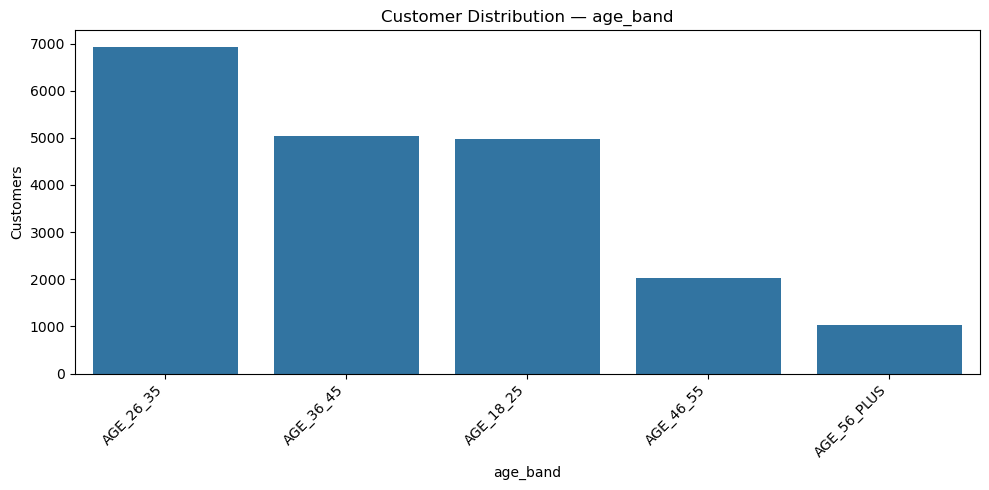

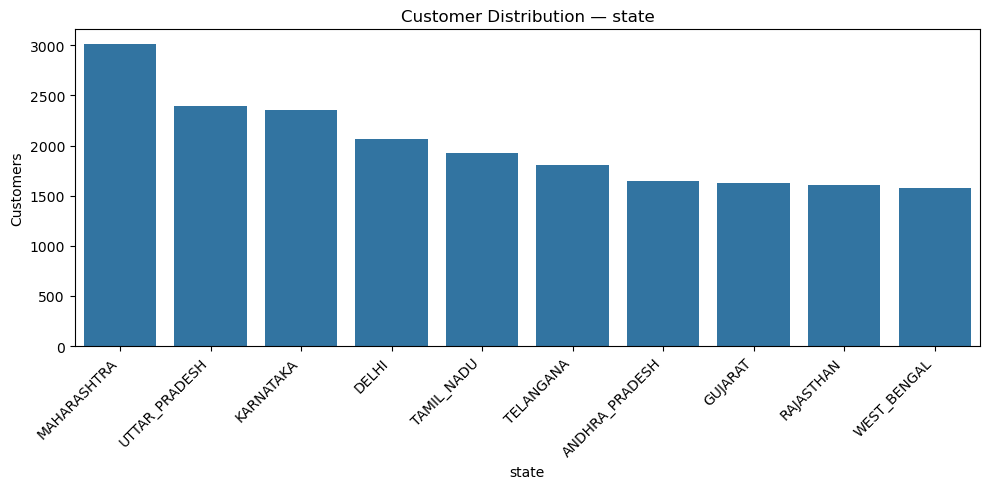

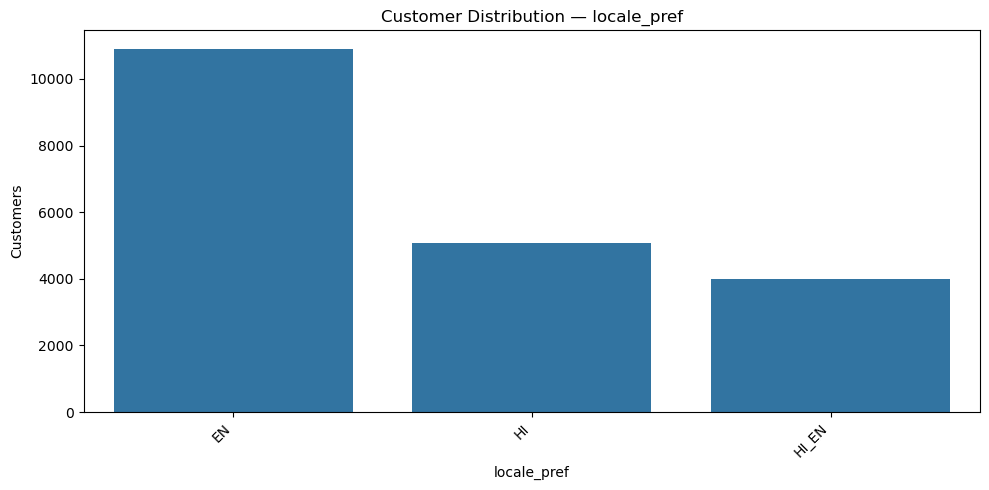

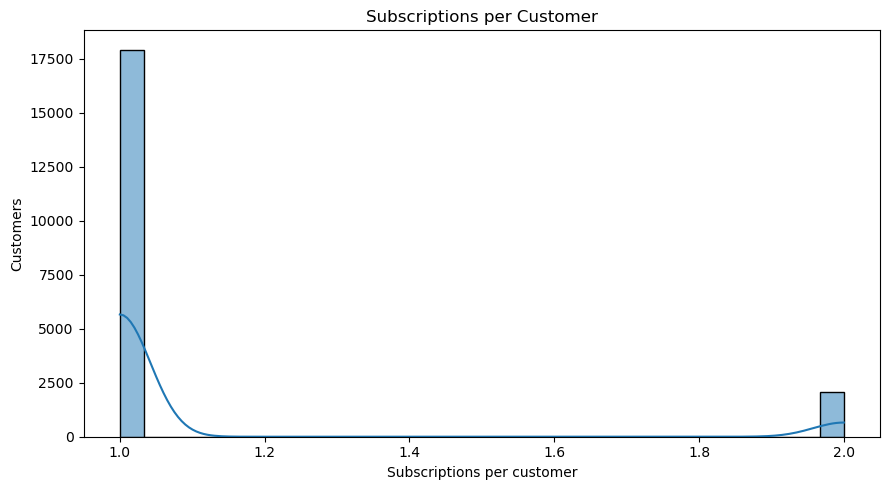

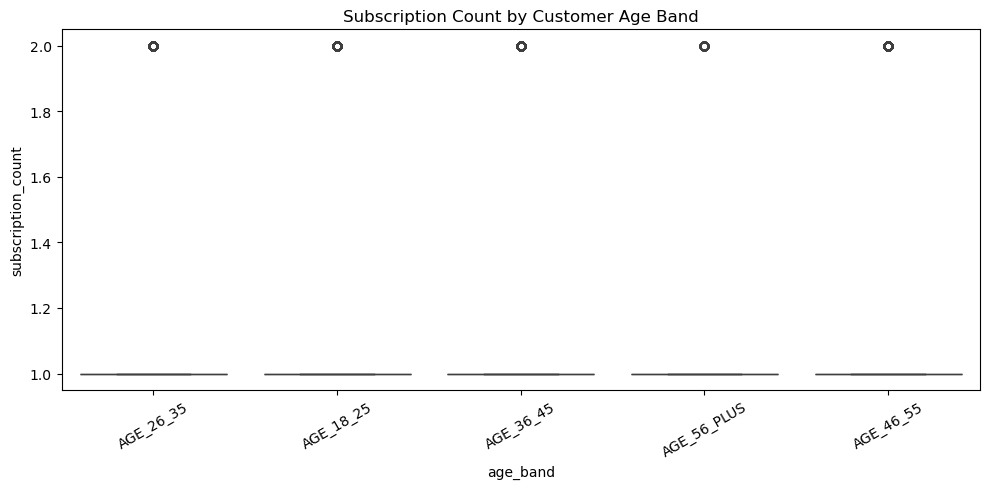

In [3]:

cust = data["customers"]
subs = data["subscriptions"]

# Customer population
for col in ["age_band", "state", "locale_pref"]:
    if col not in cust.columns:
        continue

    plt.figure(figsize=(10, 5))
    order = cust[col].value_counts(dropna=False).head(20).index
    sns.countplot(
        data=cust,
        x=col,
        order=order,
    )
    plt.title(f"Customer Distribution — {col}")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Customers")
    save_plot(f"customer_{col}_countplot.png")

# Subscription count by customer
if "customer_id" in subs.columns:
    sub_counts = subs.groupby("customer_id").size().rename("subscription_count")

    plt.figure(figsize=(9, 5))
    sns.histplot(
        sub_counts,
        bins=30,
        kde=True,
    )
    plt.title("Subscriptions per Customer")
    plt.xlabel("Subscriptions per customer")
    plt.ylabel("Customers")
    save_plot("subscriptions_per_customer_histplot.png")

# Customer age/state vs subscription count where available
if {"customer_id", "age_band"}.issubset(cust.columns) and "customer_id" in subs.columns:
    customer_sub_counts = (
        subs.groupby("customer_id").size().rename("subscription_count").reset_index()
    )
    customer_profile = cust.merge(
        customer_sub_counts,
        on="customer_id",
        how="left",
    )
    customer_profile["subscription_count"] = (
        customer_profile["subscription_count"].fillna(0)
    )

    if "age_band" in customer_profile.columns:
        plt.figure(figsize=(10, 5))
        sns.boxplot(
            data=customer_profile,
            x="age_band",
            y="subscription_count",
        )
        plt.title("Subscription Count by Customer Age Band")
        plt.xticks(rotation=30)
        save_plot("customer_age_band_vs_subscription_count.png")


## 2. Subscription Economics and Payment Setup

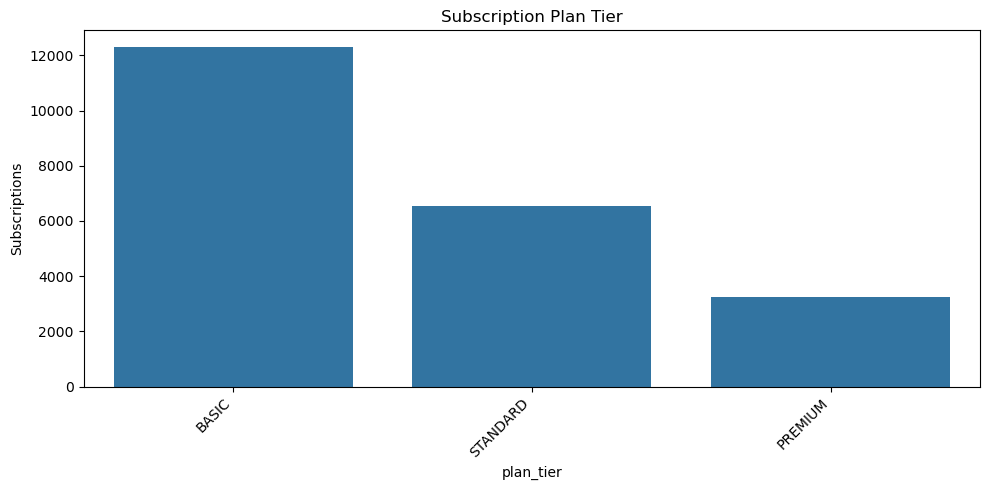

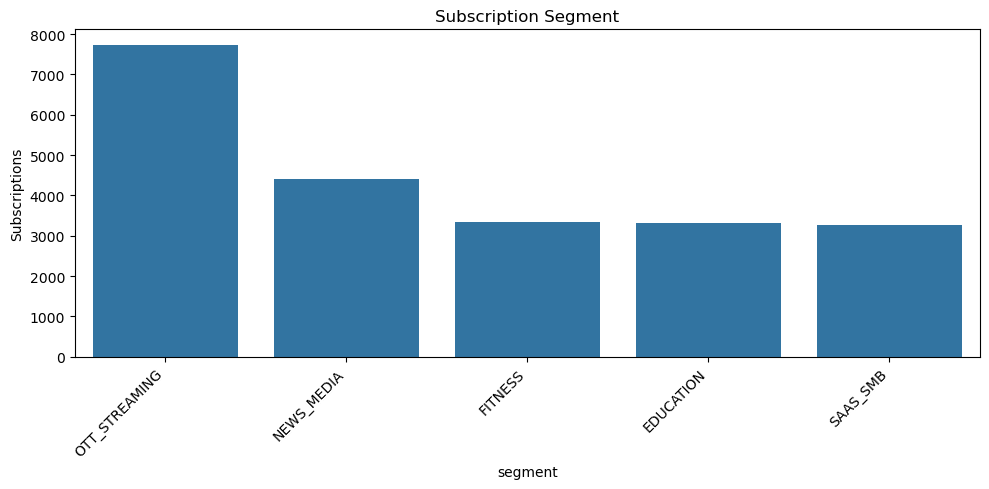

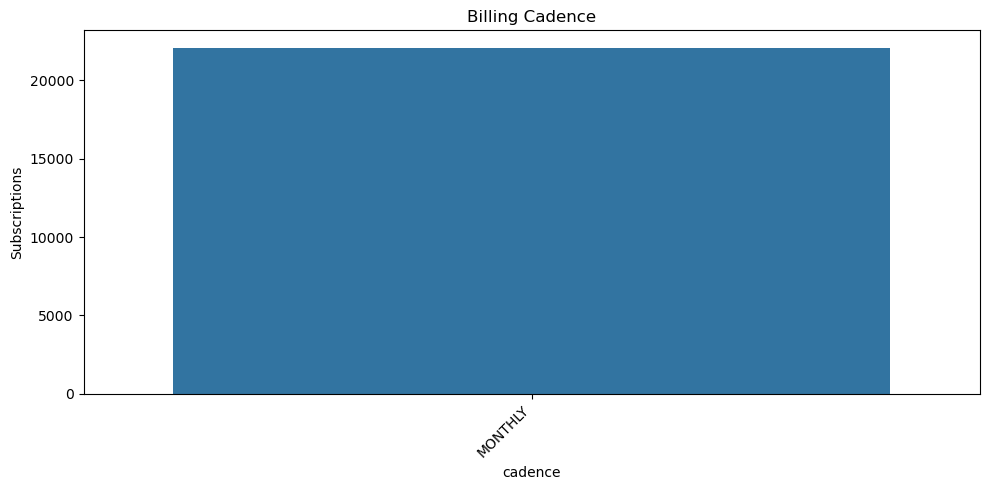

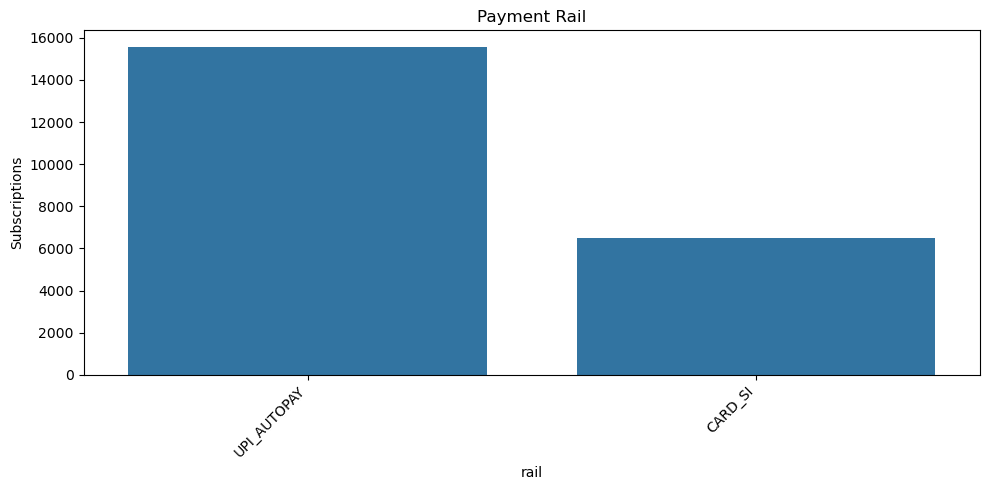

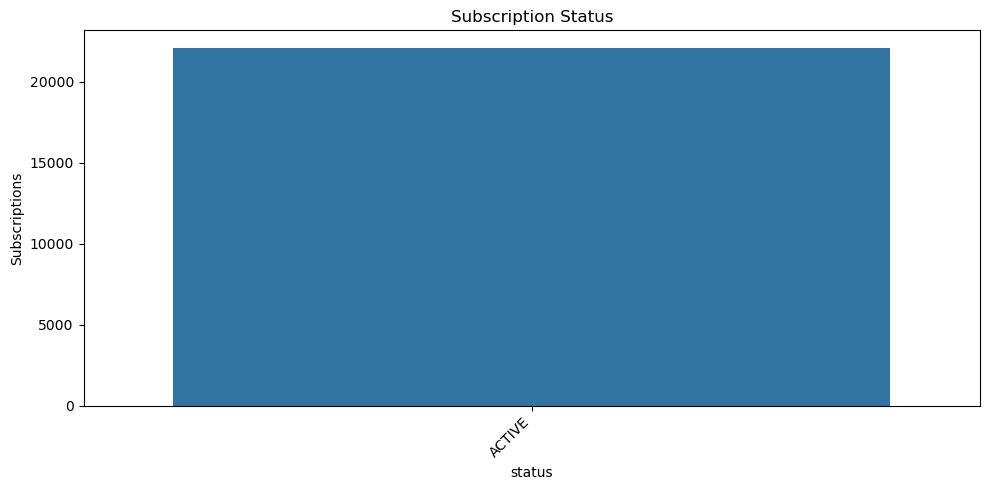

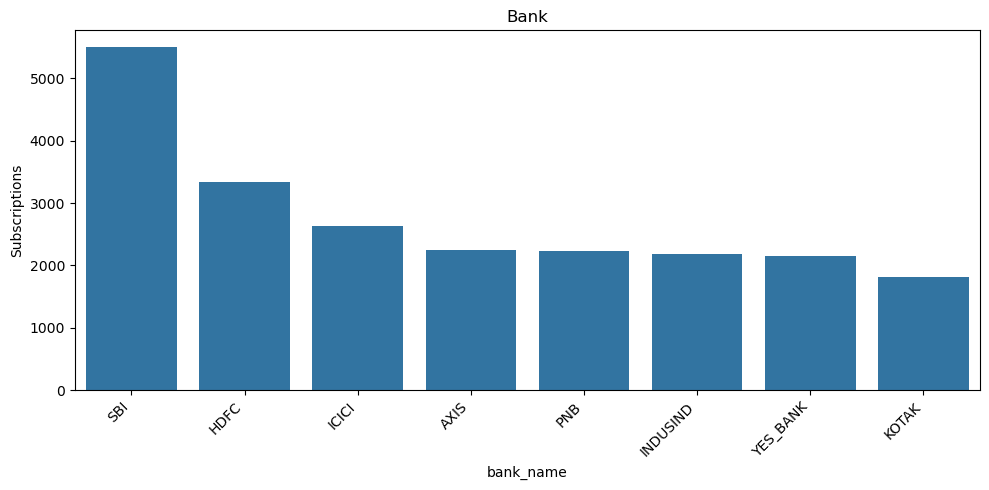

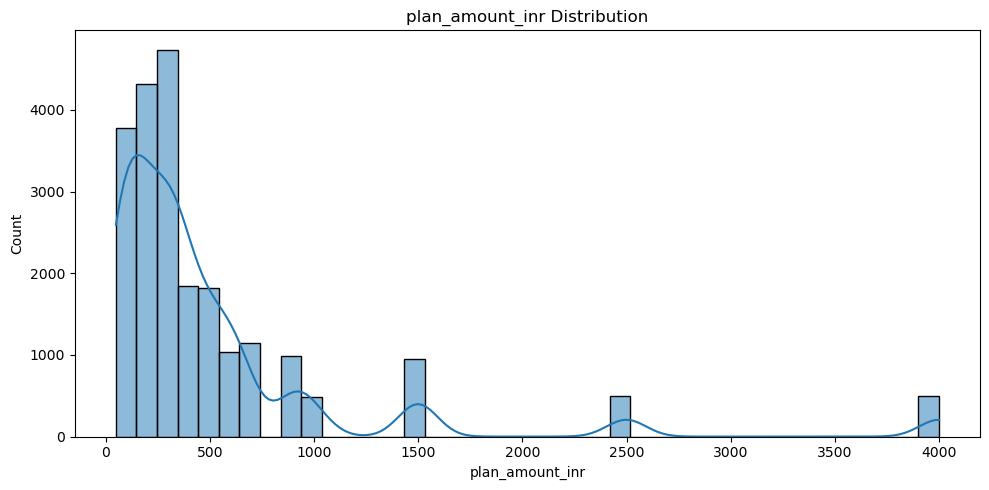

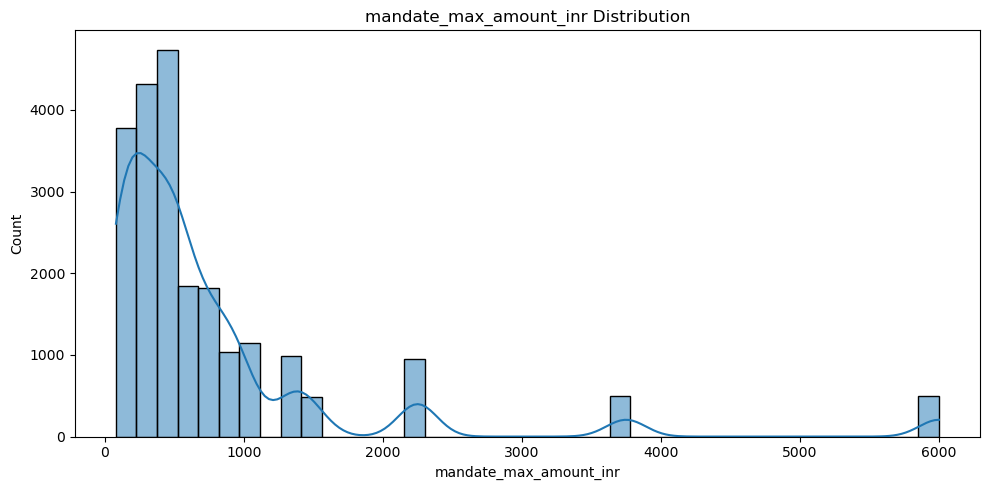

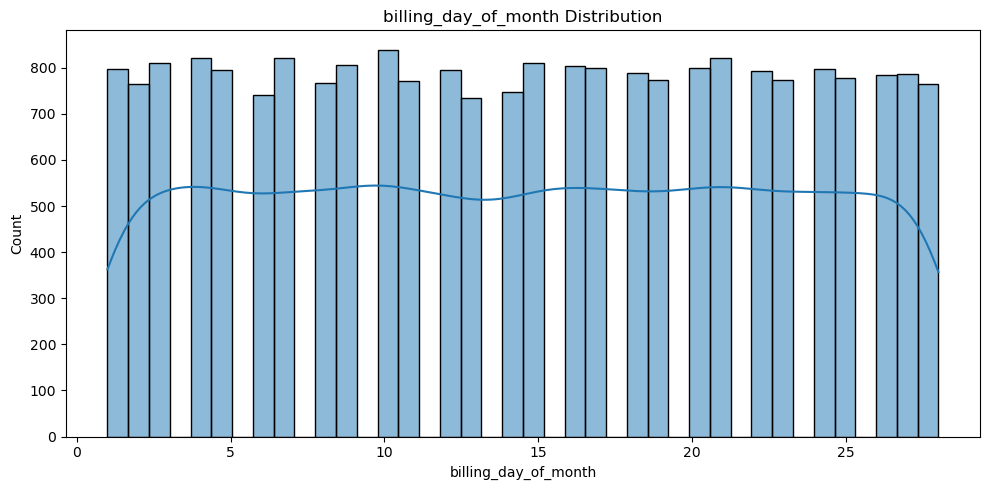

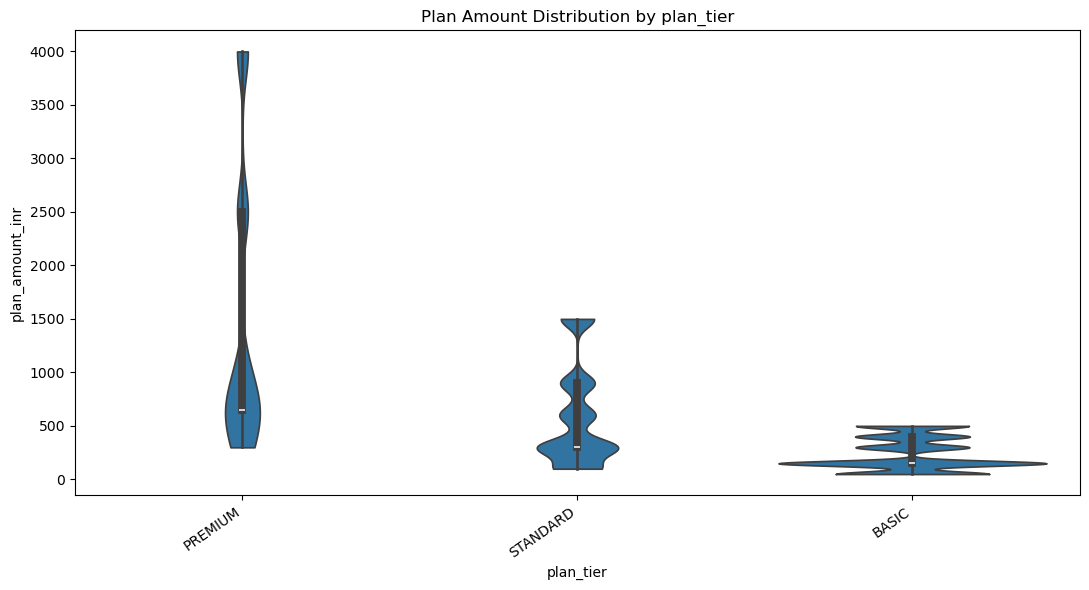

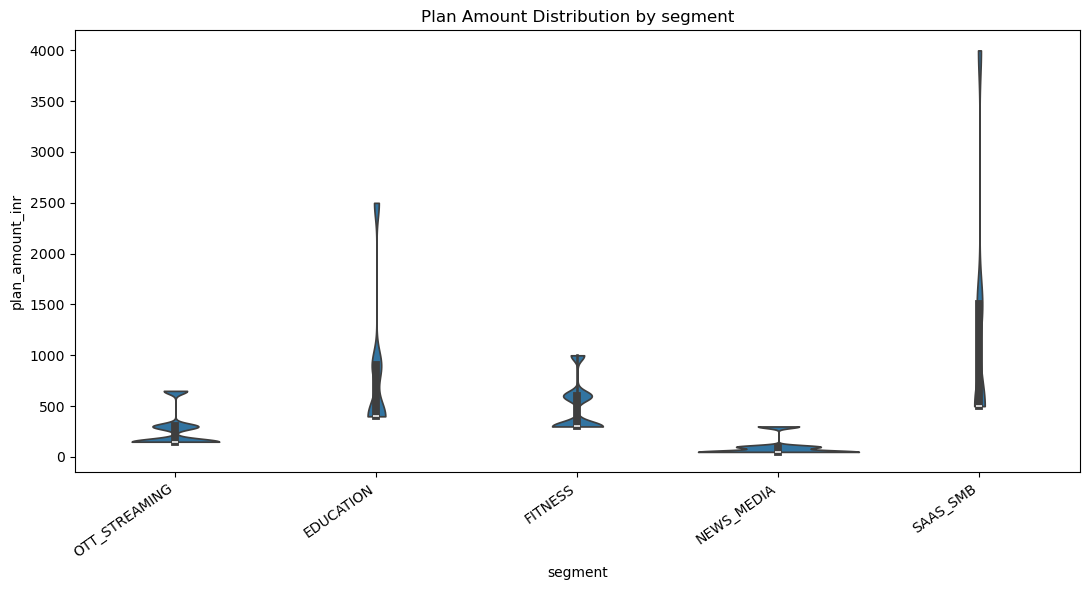

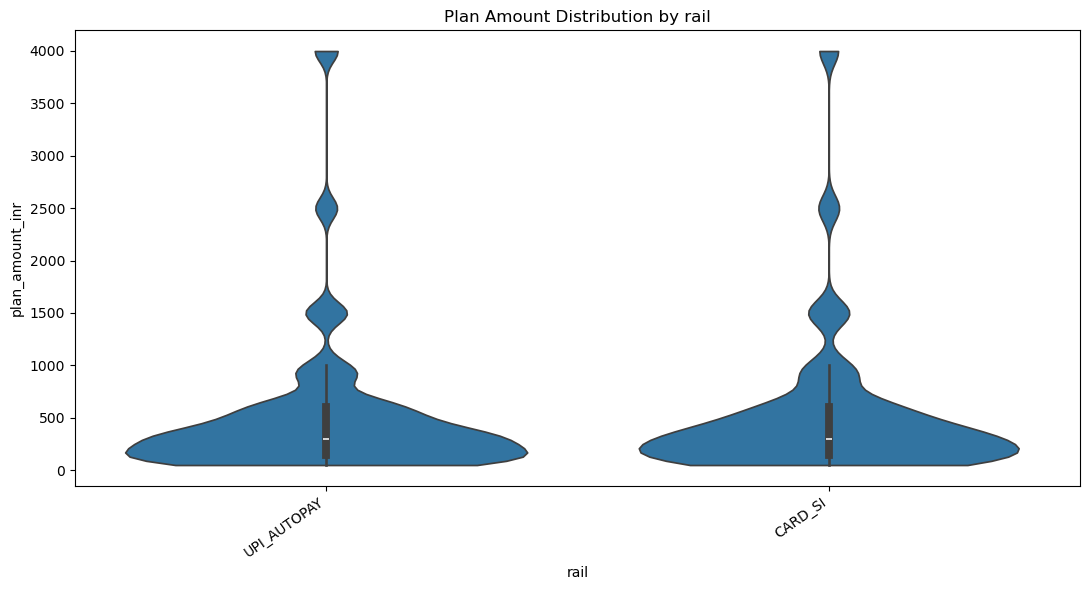

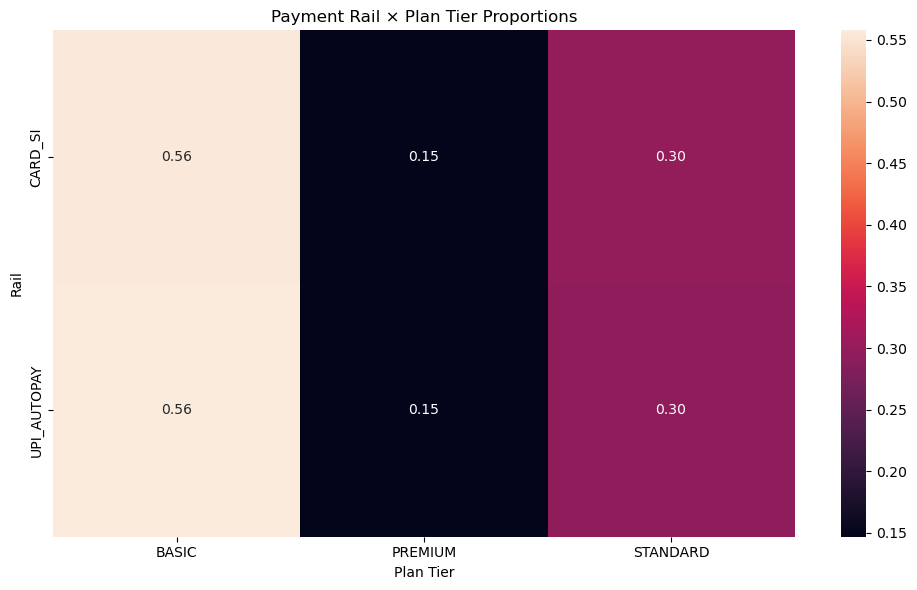

In [4]:

subs = data["subscriptions"]

categorical_specs = [
    ("plan_tier", "Subscription Plan Tier"),
    ("segment", "Subscription Segment"),
    ("cadence", "Billing Cadence"),
    ("rail", "Payment Rail"),
    ("status", "Subscription Status"),
    ("bank_name", "Bank"),
]

for col, title in categorical_specs:
    if col not in subs.columns:
        continue

    order = subs[col].value_counts(dropna=False).head(20).index

    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=subs,
        x=col,
        order=order,
    )
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Subscriptions")
    save_plot(f"subscription_{col}_countplot.png")

numeric_specs = [
    "plan_amount_inr",
    "mandate_max_amount_inr",
    "billing_day_of_month",
]

for col in numeric_specs:
    if col not in subs.columns:
        continue

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=subs,
        x=col,
        bins=40,
        kde=True,
    )
    plt.title(f"{col} Distribution")
    save_plot(f"subscription_{col}_histplot.png")

# Amount by plan / segment / rail
for group_col in ["plan_tier", "segment", "rail"]:
    if {group_col, "plan_amount_inr"}.issubset(subs.columns):

        plt.figure(figsize=(11, 6))
        sns.violinplot(
            data=subs,
            x=group_col,
            y="plan_amount_inr",
            cut=0,
        )
        plt.title(f"Plan Amount Distribution by {group_col}")
        plt.xticks(rotation=35, ha="right")
        save_plot(f"subscription_amount_by_{group_col}_violin.png")

# Rail × plan composition
if {"rail", "plan_tier"}.issubset(subs.columns):
    share = pd.crosstab(
        subs["rail"],
        subs["plan_tier"],
        normalize="index",
    )

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        share,
        annot=True,
        fmt=".2f",
    )
    plt.title("Payment Rail × Plan Tier Proportions")
    plt.xlabel("Plan Tier")
    plt.ylabel("Rail")
    save_plot("subscription_rail_plan_heatmap.png")


## 3. Payment Attempt Dynamics

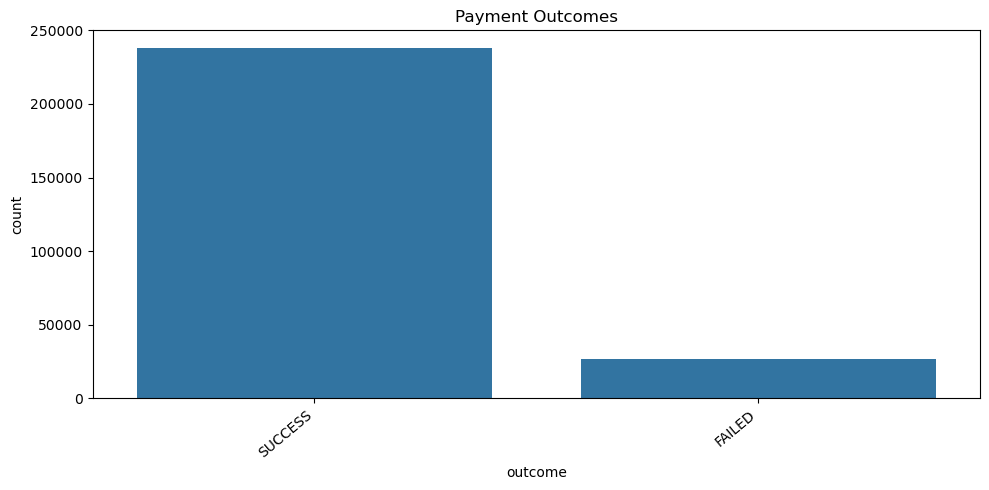

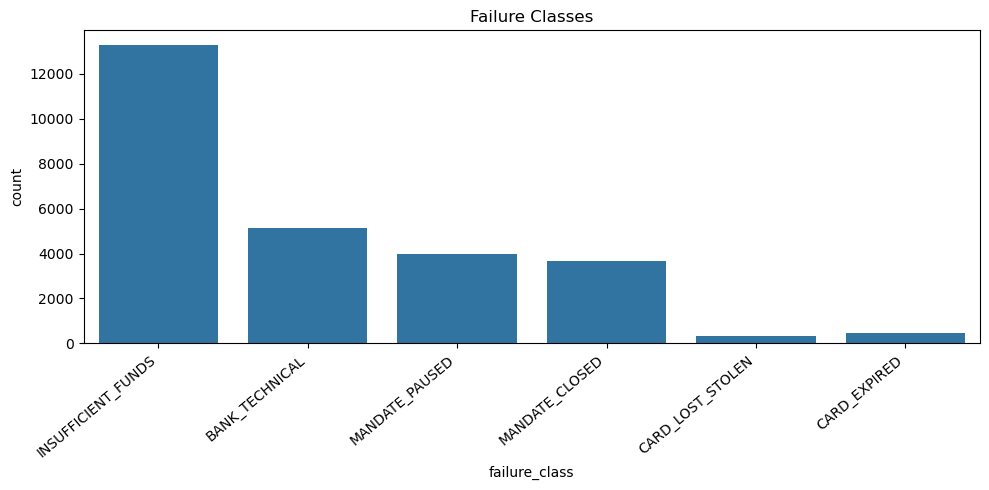

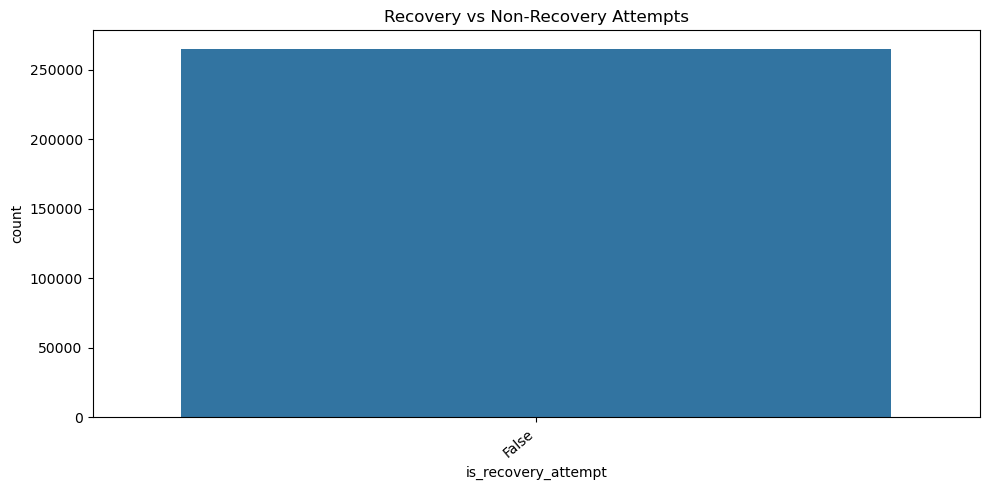

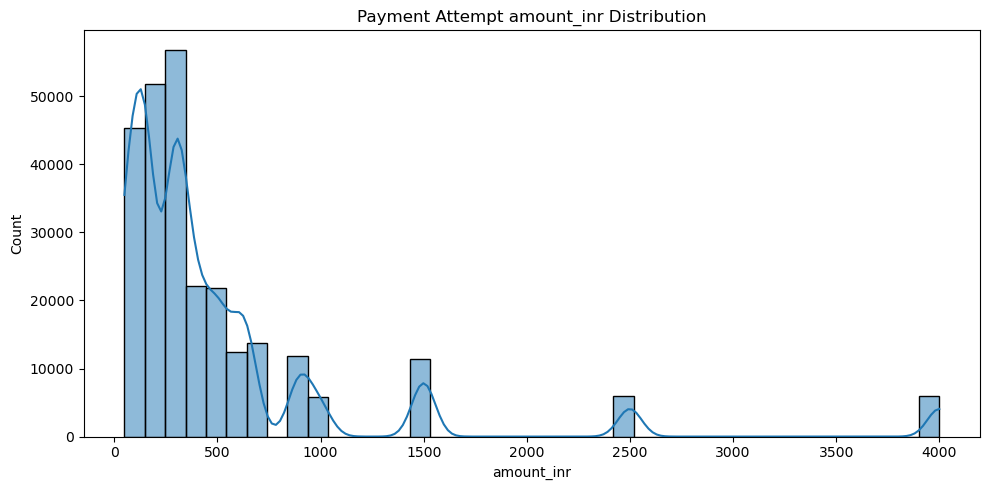

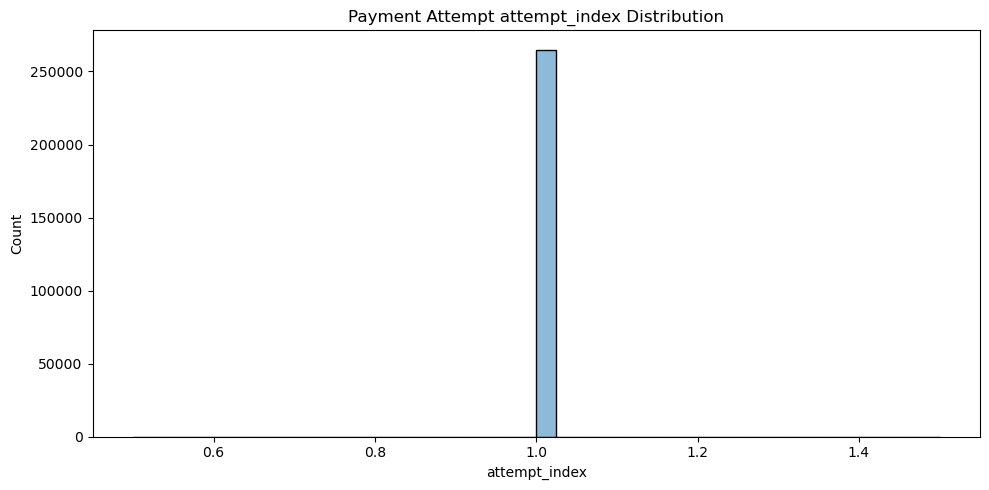

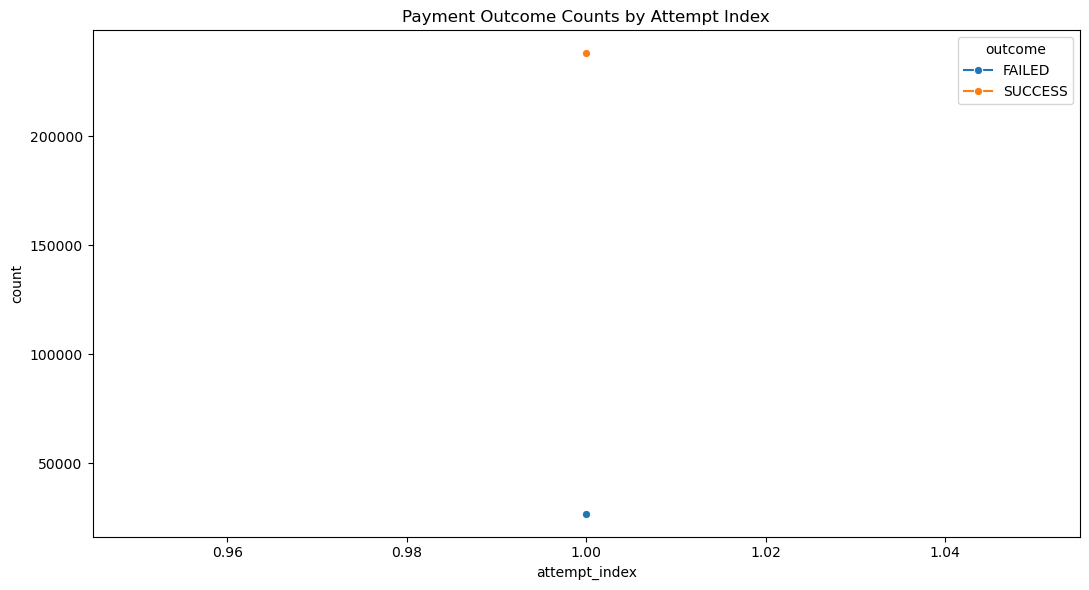

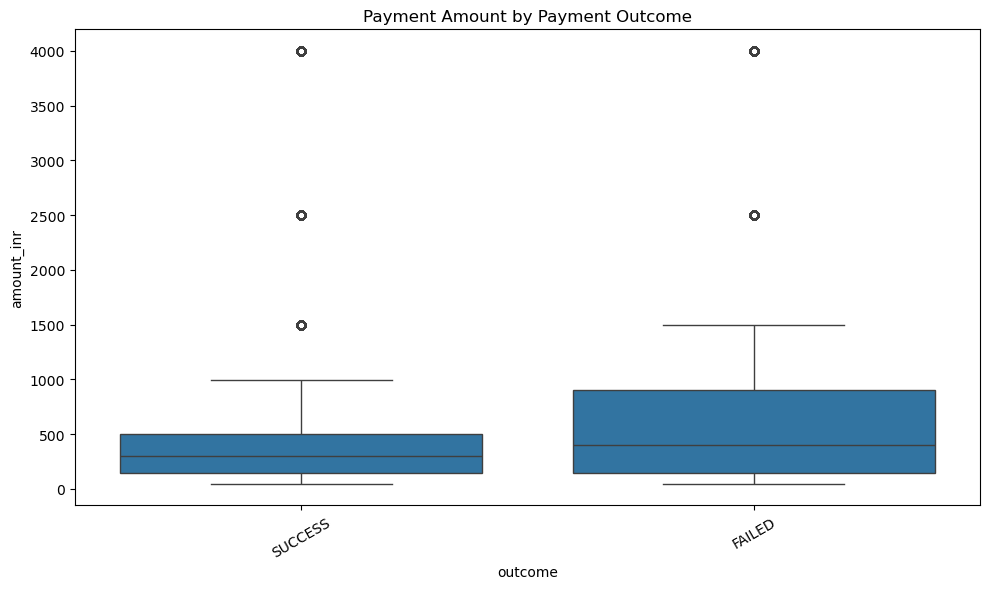

In [5]:

attempts = data["payment_attempts"]

for col, title in [
    ("outcome", "Payment Outcomes"),
    ("failure_class", "Failure Classes"),
    ("is_recovery_attempt", "Recovery vs Non-Recovery Attempts"),
]:
    if col not in attempts.columns:
        continue

    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=attempts,
        x=col,
    )
    plt.title(title)
    plt.xticks(rotation=40, ha="right")
    save_plot(f"attempt_{col}_countplot.png")

for col in ["amount_inr", "attempt_index"]:
    if col not in attempts.columns:
        continue

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=attempts,
        x=col,
        bins=40,
        kde=True,
    )
    plt.title(f"Payment Attempt {col} Distribution")
    save_plot(f"attempt_{col}_histplot.png")

# Outcome vs attempt index
if {"attempt_index", "outcome"}.issubset(attempts.columns):
    attempt_outcome = (
        attempts.groupby(
            ["attempt_index", "outcome"],
            dropna=False
        )
        .size()
        .reset_index(name="count")
    )

    plt.figure(figsize=(11, 6))
    sns.lineplot(
        data=attempt_outcome,
        x="attempt_index",
        y="count",
        hue="outcome",
        marker="o",
    )
    plt.title("Payment Outcome Counts by Attempt Index")
    save_plot("attempt_outcome_by_index_lineplot.png")

# Amount by outcome
if {"amount_inr", "outcome"}.issubset(attempts.columns):
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=attempts,
        x="outcome",
        y="amount_inr",
    )
    plt.title("Payment Amount by Payment Outcome")
    plt.xticks(rotation=30)
    save_plot("attempt_amount_by_outcome_boxplot.png")


## 4. Recovery Case Economics and State

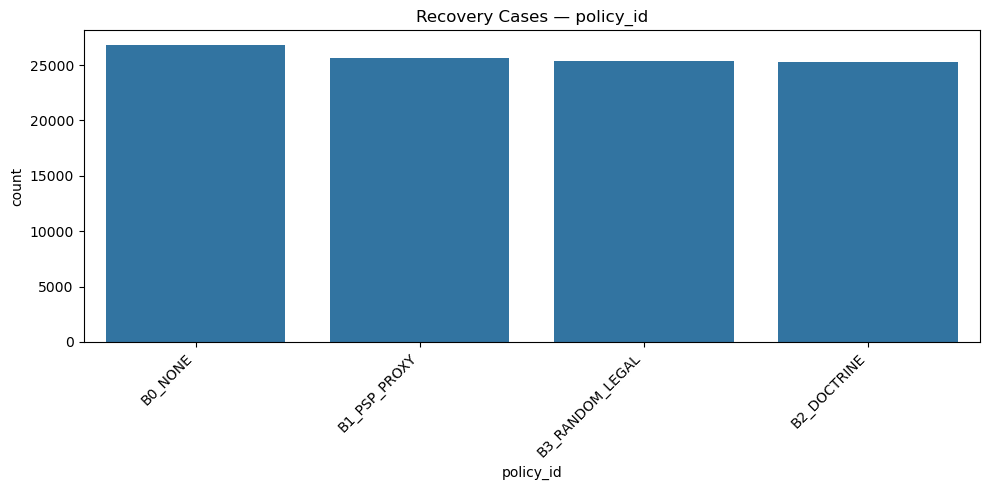

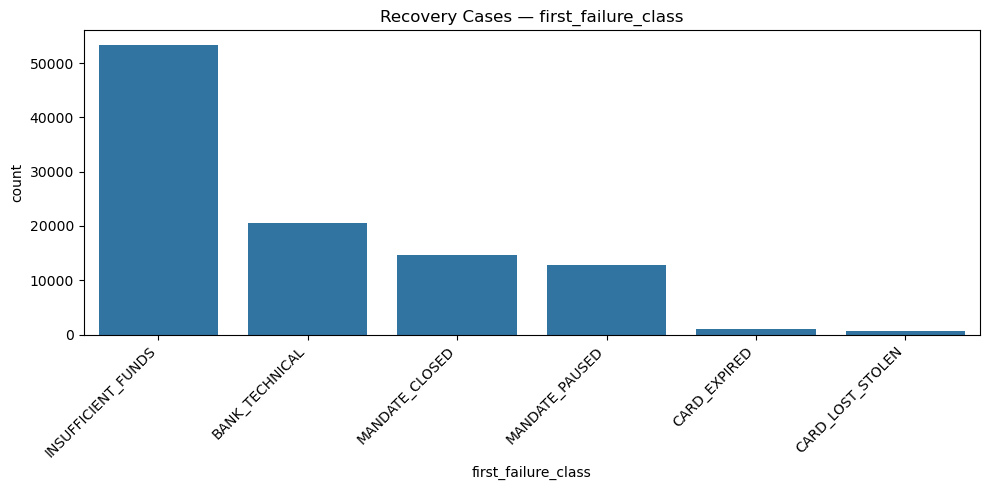

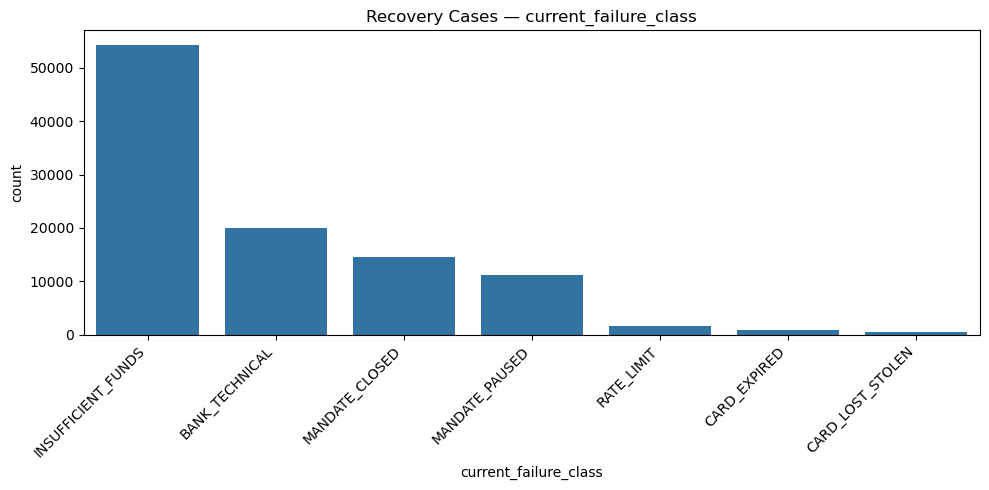

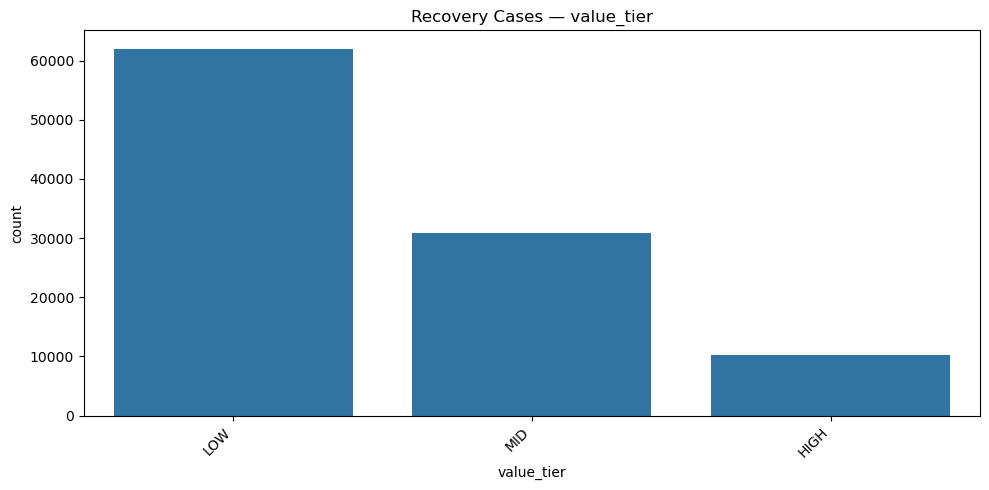

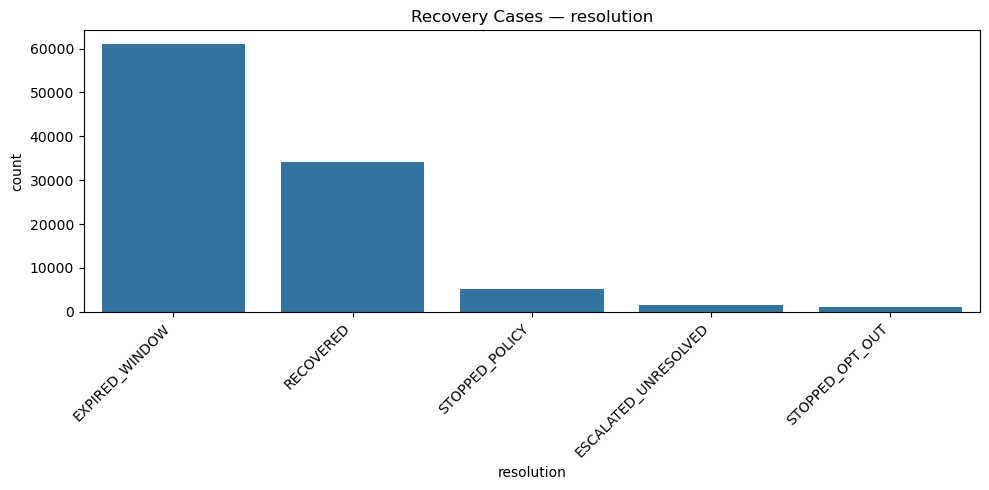

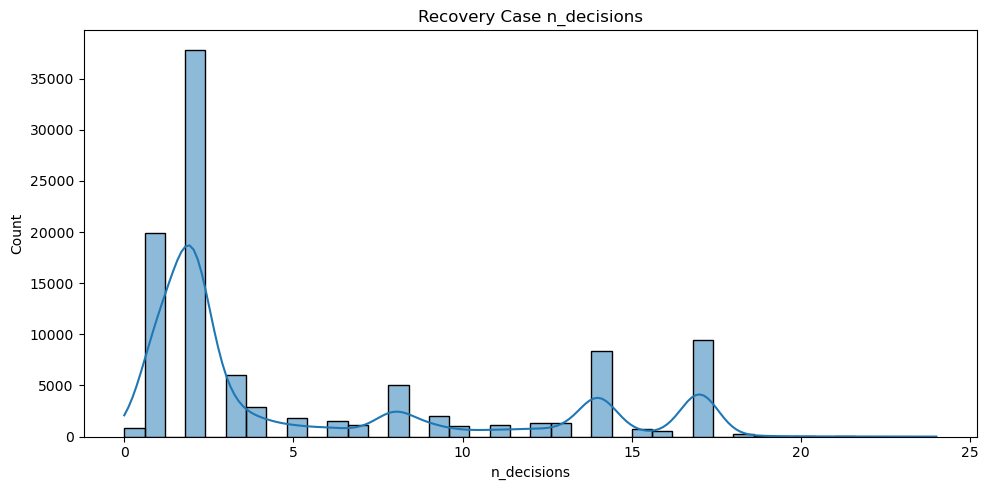

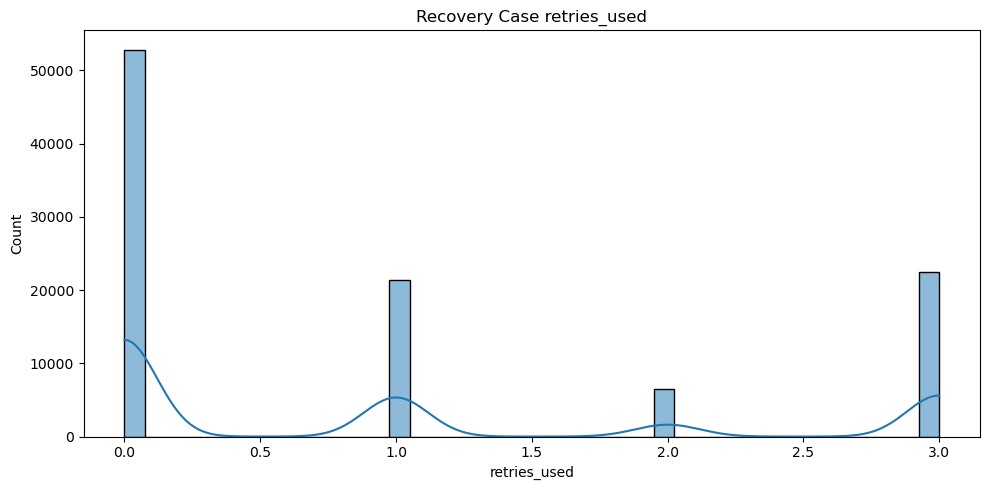

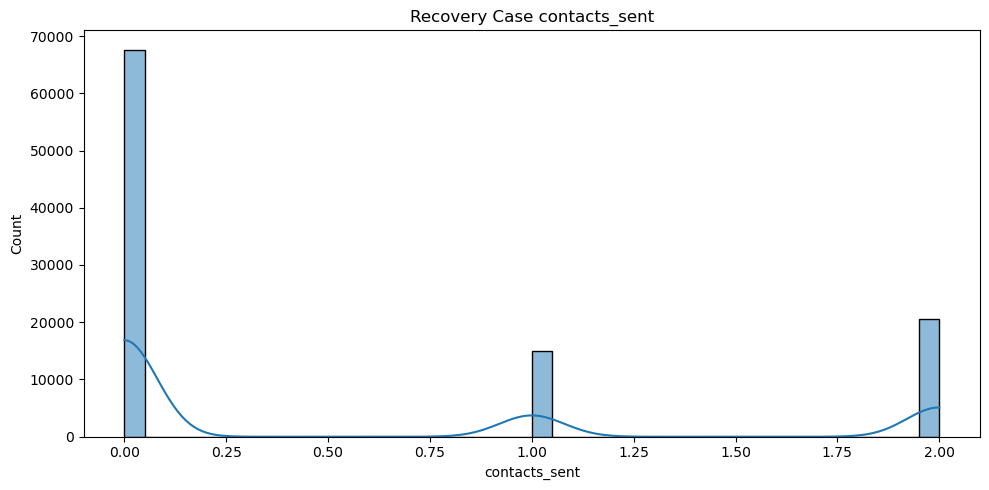

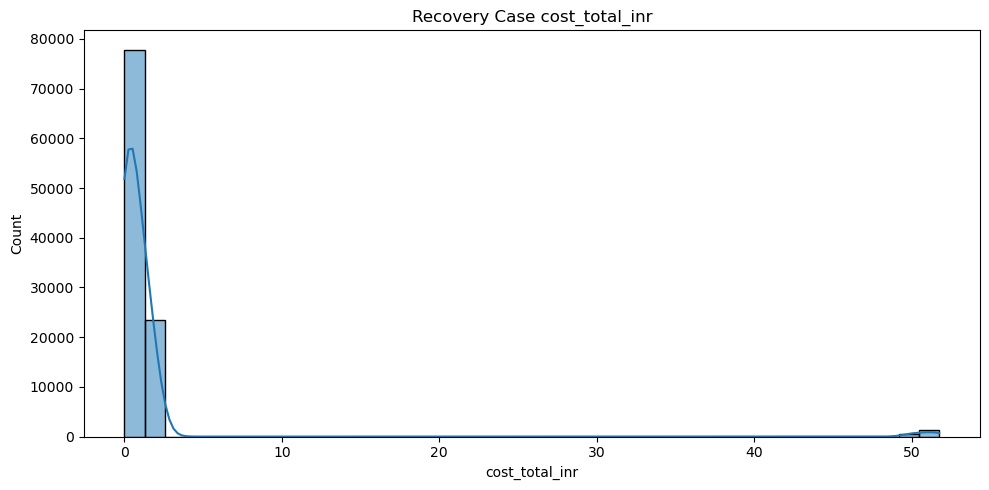

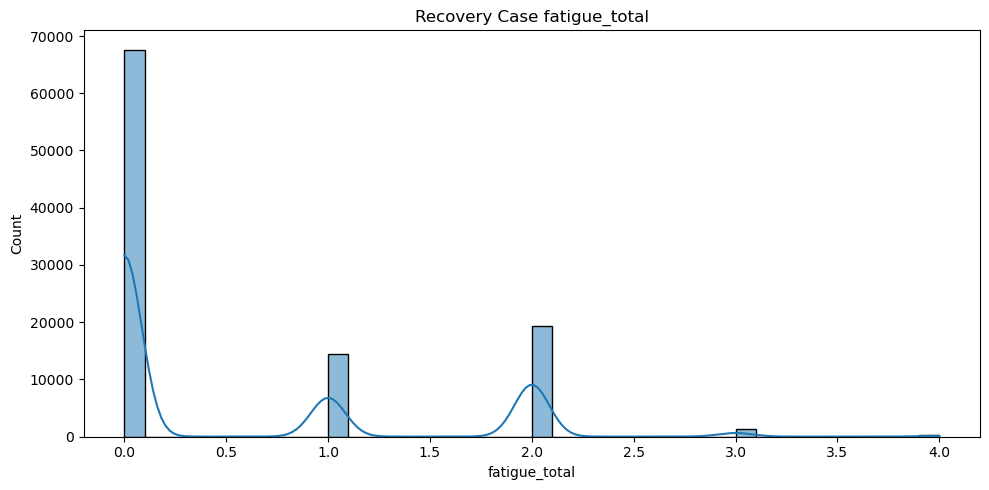

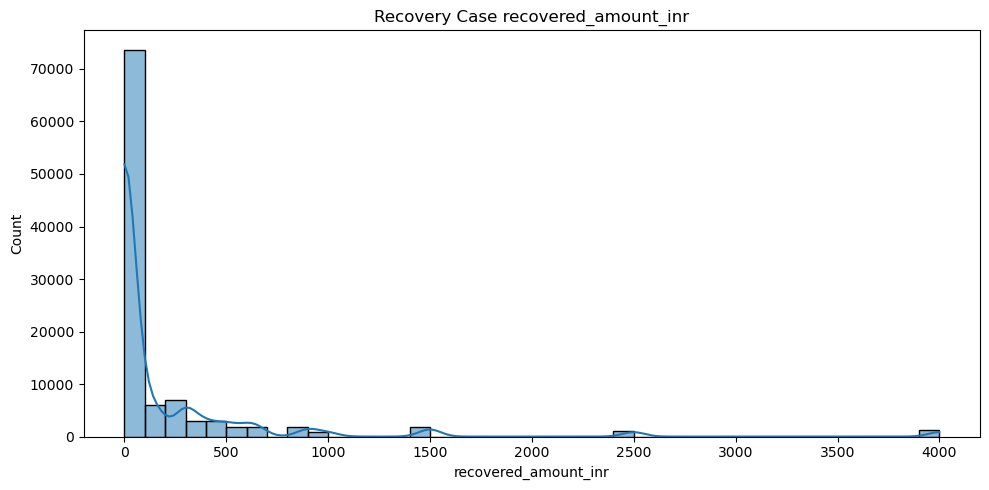

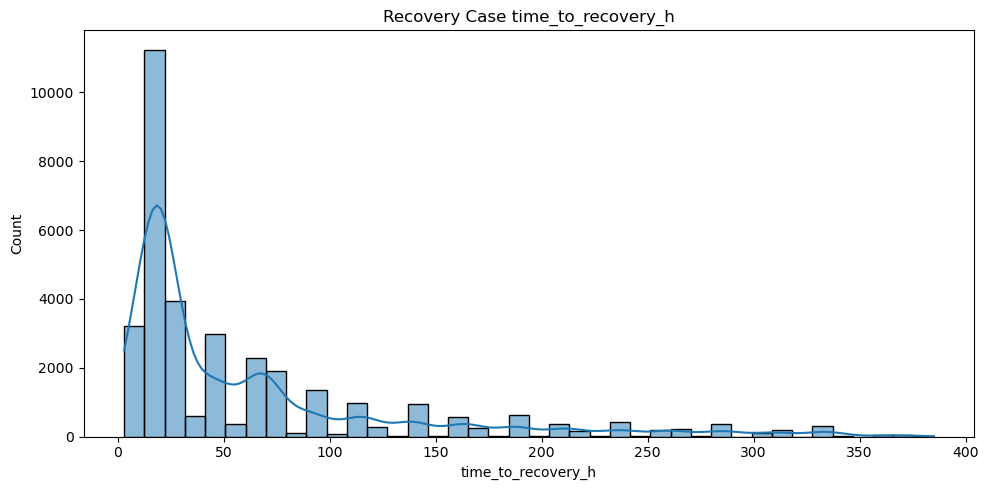

In [6]:

cases = data["recovery_cases"]

for col in [
    "policy_id",
    "first_failure_class",
    "current_failure_class",
    "value_tier",
    "resolution",
]:
    if col not in cases.columns:
        continue

    order = cases[col].value_counts(dropna=False).head(20).index
    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=cases,
        x=col,
        order=order,
    )
    plt.title(f"Recovery Cases — {col}")
    plt.xticks(rotation=45, ha="right")
    save_plot(f"case_{col}_countplot.png")

for col in [
    "amount_at_risk",
    "n_decisions",
    "retries_used",
    "contacts_sent",
    "cost_total_inr",
    "fatigue_total",
    "recovered_amount_inr",
    "time_to_recovery_h",
]:
    if col not in cases.columns:
        continue

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=cases,
        x=col,
        bins=40,
        kde=True,
    )
    plt.title(f"Recovery Case {col}")
    save_plot(f"case_{col}_histplot.png")

# Amount at risk by failure mechanism and value tier
for group_col in [
    "first_failure_class",
    "value_tier",
    "policy_id",
]:
    if {group_col, "amount_at_risk"}.issubset(cases.columns):
        plt.figure(figsize=(11, 6))
        sns.violinplot(
            data=cases,
            x=group_col,
            y="amount_at_risk",
            cut=0,
        )
        plt.title(f"Amount at Risk by {group_col}")
        plt.xticks(rotation=35, ha="right")
        save_plot(f"case_amount_at_risk_by_{group_col}.png")


## 5. Recovery Event Lifecycle

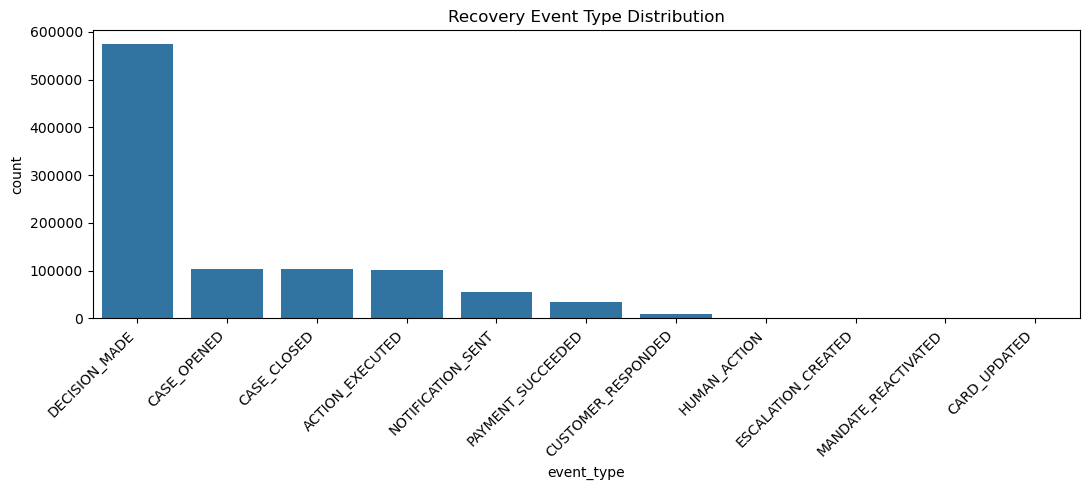

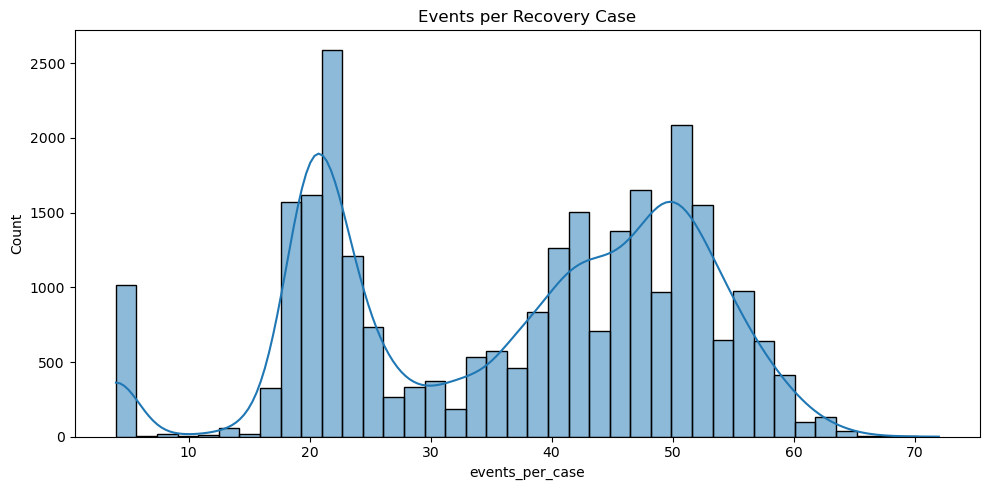

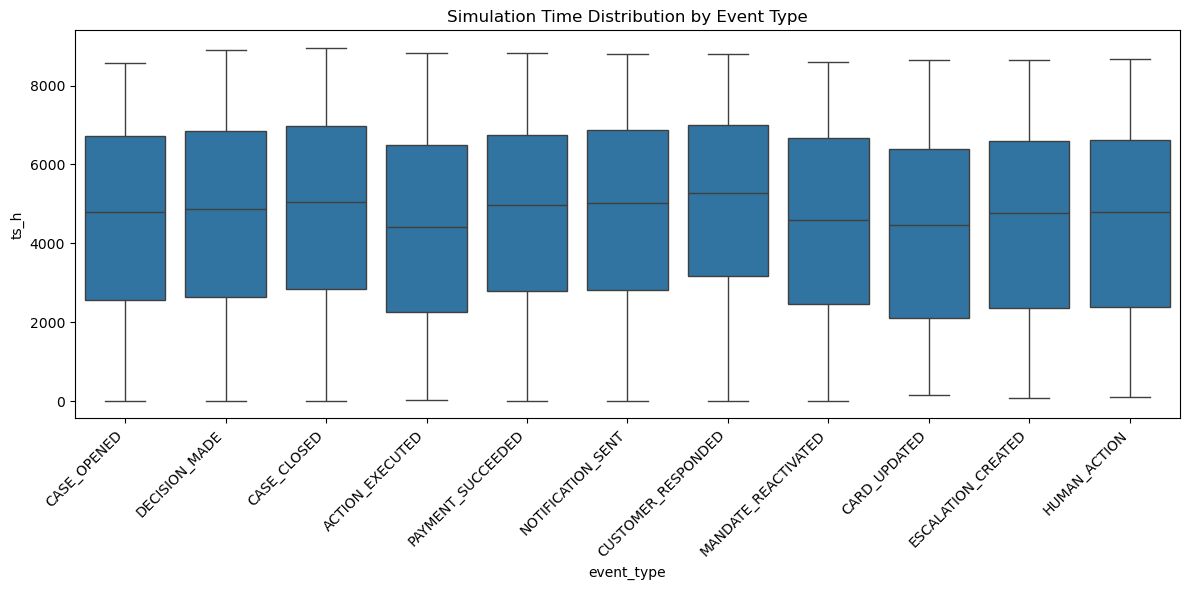

In [7]:

events = data["recovery_events"]

if "event_type" in events.columns:
    plt.figure(figsize=(11, 5))
    order = events["event_type"].value_counts().index
    sns.countplot(
        data=events,
        x="event_type",
        order=order,
    )
    plt.title("Recovery Event Type Distribution")
    plt.xticks(rotation=45, ha="right")
    save_plot("events_type_countplot.png")

if {"case_id", "ts_h"}.issubset(events.columns):
    event_counts = events.groupby("case_id").size().rename("events_per_case").reset_index()

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=event_counts,
        x="events_per_case",
        bins=40,
        kde=True,
    )
    plt.title("Events per Recovery Case")
    save_plot("events_per_case_distribution.png")

# Event timing by event type
if {"event_type", "ts_h"}.issubset(events.columns):
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=events,
        x="event_type",
        y="ts_h",
    )
    plt.title("Simulation Time Distribution by Event Type")
    plt.xticks(rotation=45, ha="right")
    save_plot("events_time_by_type_boxplot.png")


## 6. Intervention / Policy Behaviour — Core Analysis

This section is central to the project because the eventual model estimates
success conditional on a candidate intervention.

All outcome plots below are **observed associations**, not causal effects.

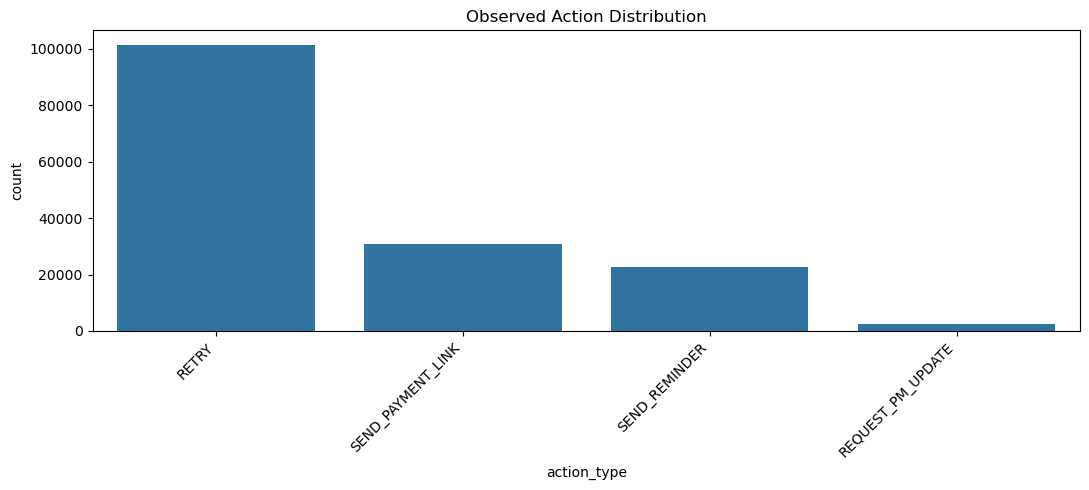

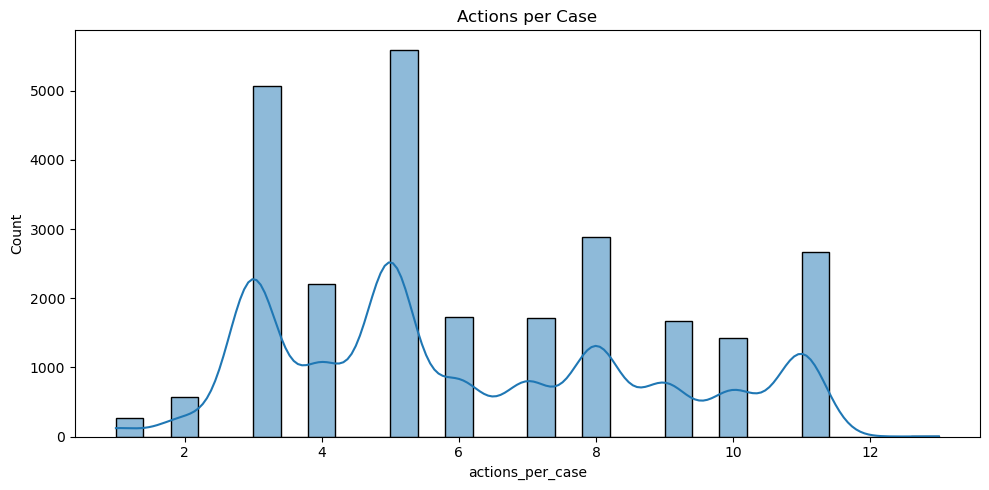

In [8]:

actions = data["action_log"]

if "action_type" in actions.columns:
    order = actions["action_type"].value_counts().index

    plt.figure(figsize=(11, 5))
    sns.countplot(
        data=actions,
        x="action_type",
        order=order,
    )
    plt.title("Observed Action Distribution")
    plt.xticks(rotation=45, ha="right")
    save_plot("actions_observed_distribution.png")

if {"logging_policy", "action_type"}.issubset(actions.columns):
    policy_action_share = pd.crosstab(
        actions["logging_policy"],
        actions["action_type"],
        normalize="index",
    )

    plt.figure(figsize=(11, 6))
    sns.heatmap(
        policy_action_share,
        annot=True,
        fmt=".2f",
    )
    plt.title("Policy × Action Proportion")
    plt.xlabel("Action")
    plt.ylabel("Logging Policy")
    save_plot("policy_action_proportion_heatmap.png")

if "candidate_window_days_offset" in actions.columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(
        data=actions,
        x="candidate_window_days_offset",
    )
    plt.title("Candidate Execution Window Distribution")
    plt.xticks(rotation=45, ha="right")
    save_plot("candidate_window_countplot.png")

if "case_id" in actions.columns:
    action_counts = (
        actions.groupby("case_id")
        .size()
        .rename("actions_per_case")
        .reset_index()
    )

    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=action_counts,
        x="actions_per_case",
        bins=30,
        kde=True,
    )
    plt.title("Actions per Case")
    save_plot("actions_per_case_distribution.png")


## 7. Observed Intervention Success — Advanced Comparisons

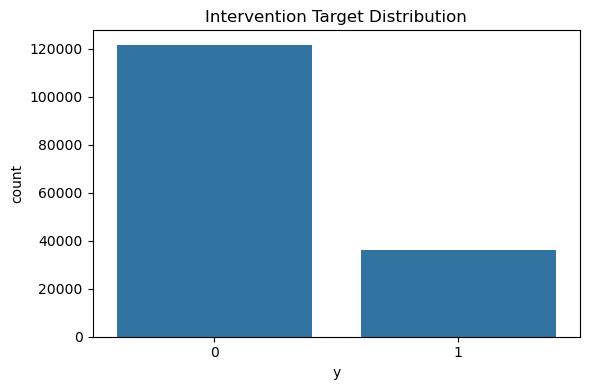

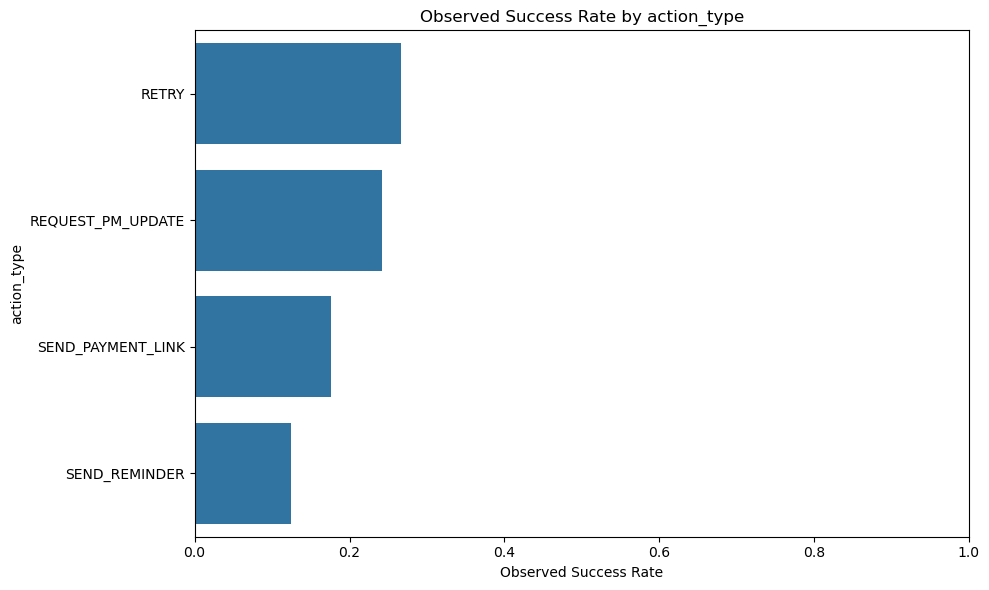

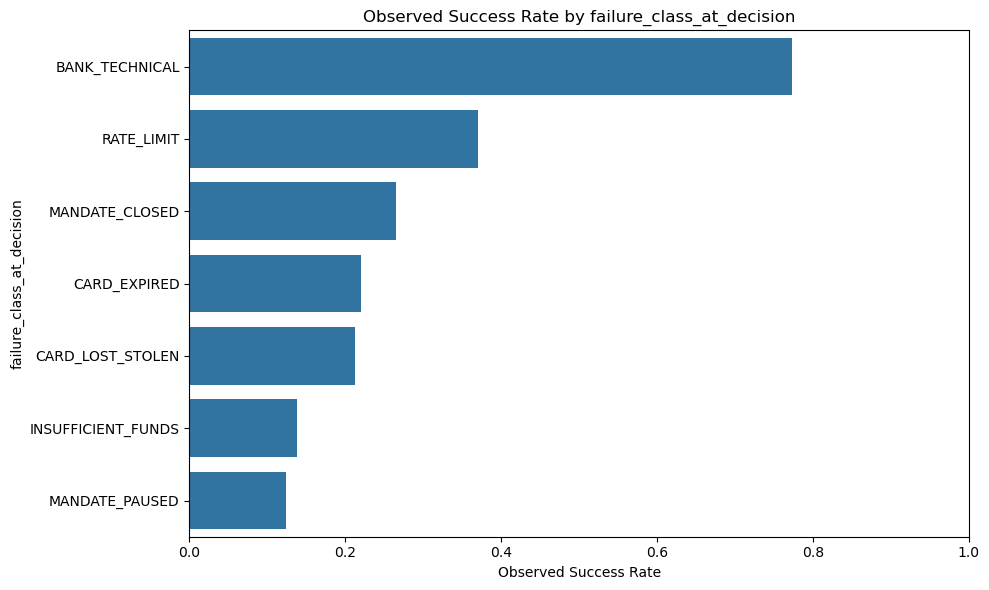

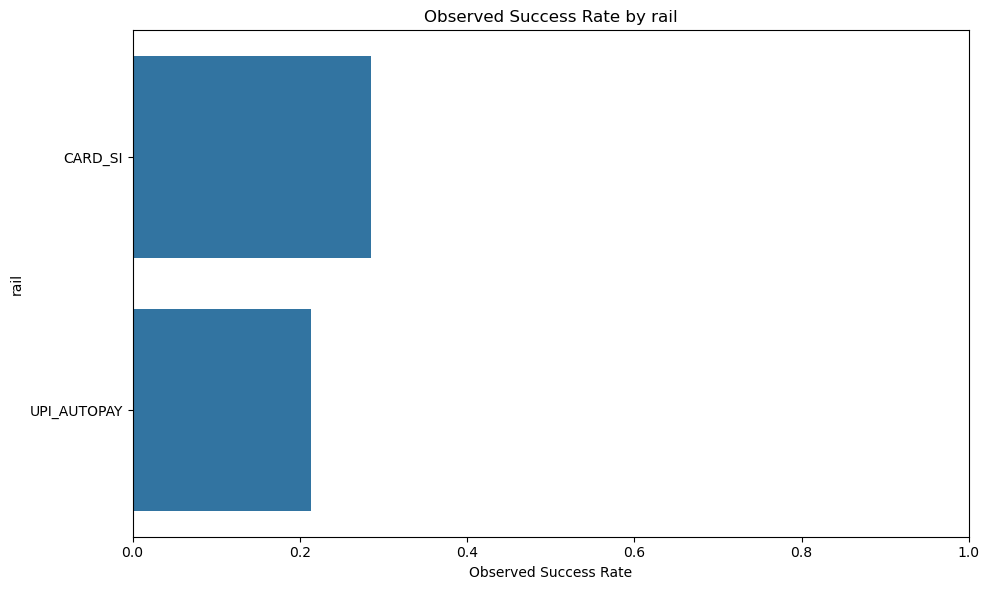

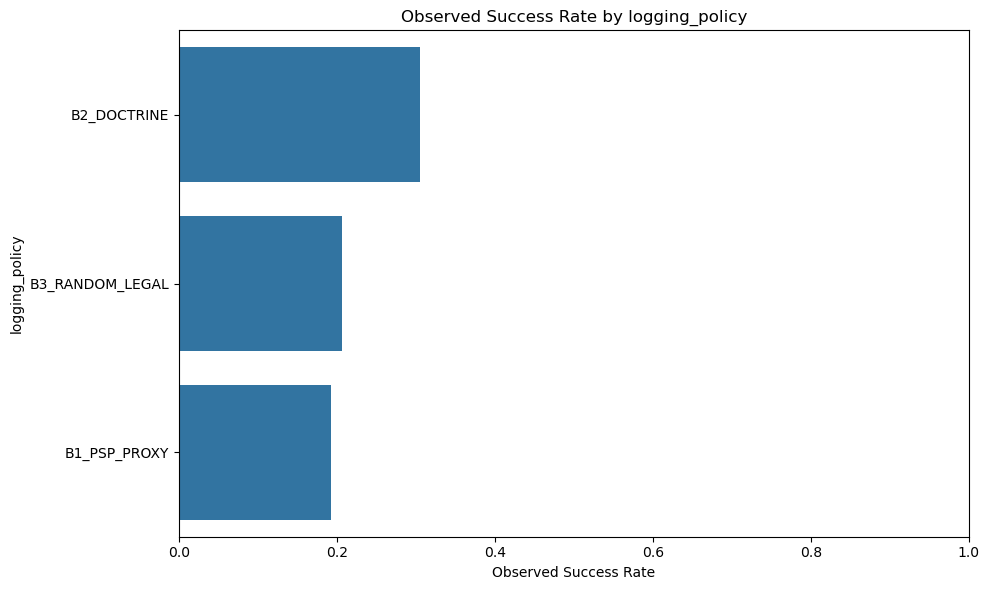

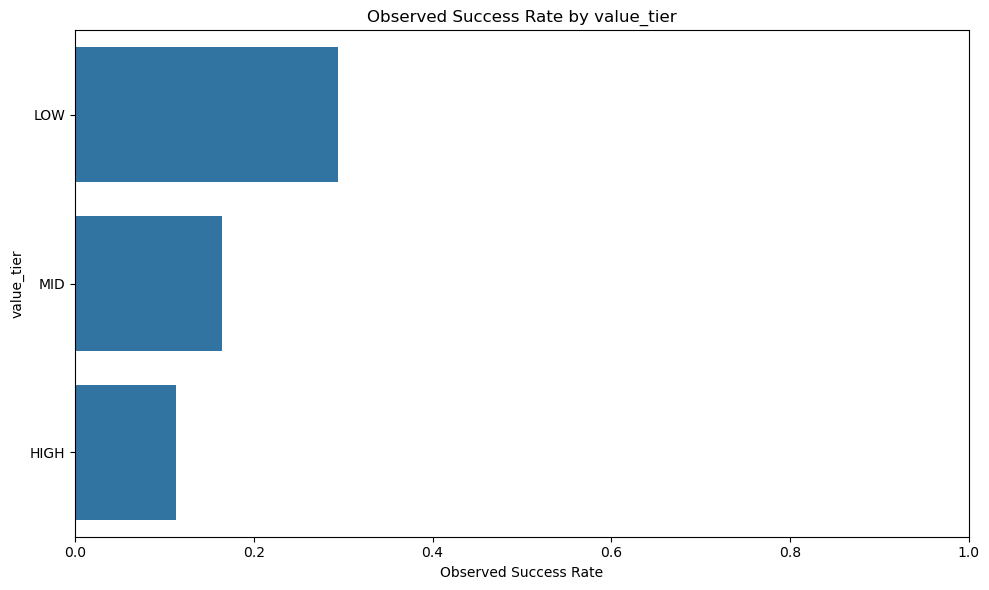

In [9]:

# Count target first
plt.figure(figsize=(6, 4))
sns.countplot(
    data=ml,
    x=target_col,
)
plt.title("Intervention Target Distribution")
plt.xlabel(target_col)
save_plot("target_distribution.png")

success_dims = [
    "action_type",
    "failure_class",
    "failure_class_at_decision",
    "rail",
    "logging_policy",
    "amount_bucket",
    "value_tier",
]

for col in success_dims:
    if col not in ml.columns:
        continue

    summary = observed_rate_table(
        ml,
        col,
        target=target_col,
        min_count=30,
    )

    if len(summary) < 2:
        continue

    summary = summary.sort_values(
        "observed_success_rate",
        ascending=False,
    )

    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=summary,
        x="observed_success_rate",
        y=col,
        errorbar=None,
    )
    plt.xlim(0, 1)
    plt.xlabel("Observed Success Rate")
    plt.ylabel(col)
    plt.title(f"Observed Success Rate by {col}")
    save_plot(f"success_by_{col}.png")

    summary.to_csv(
        REPORT_DIR / f"success_by_{col}.csv",
        index=False,
    )


## 8. Candidate Feature Distributions

In [10]:

numeric_candidates = []
categorical_candidates = []

for col in candidate_cols:
    s = ml[col]

    if (
        pd.api.types.is_numeric_dtype(s)
        and not pd.api.types.is_bool_dtype(s)
    ):
        numeric_candidates.append(col)
    else:
        categorical_candidates.append(col)

print("Numeric candidate features:")
print(numeric_candidates)

print("\nCategorical / binary candidate features:")
print(categorical_candidates)


Numeric candidate features:
['amount_inr', 'subscription_age_days', 'sub_billing_day', 'decision_seq', 'retries_used_before', 'contacts_sent_before', 'hours_since_open', 'customer_tenure_days', 'prior_cycles_seen', 'prior_successes', 'prior_success_rate', 'prior_failed_cases_before', 'prior_recovered_cases_before', 'day_of_month', 'day_of_week', 'hour_of_day', 'hours_to_next_cluster_slot', 'salary_day_proxy_dom']

Categorical / binary candidate features:
['rail', 'bank_name', 'segment', 'plan_tier', 'value_tier', 'failure_class_at_decision', 'first_failure_class', 'instrument_fixed', 'age_band', 'state', 'locale_pref', 'in_salary_cluster', 'action_type', 'channel']


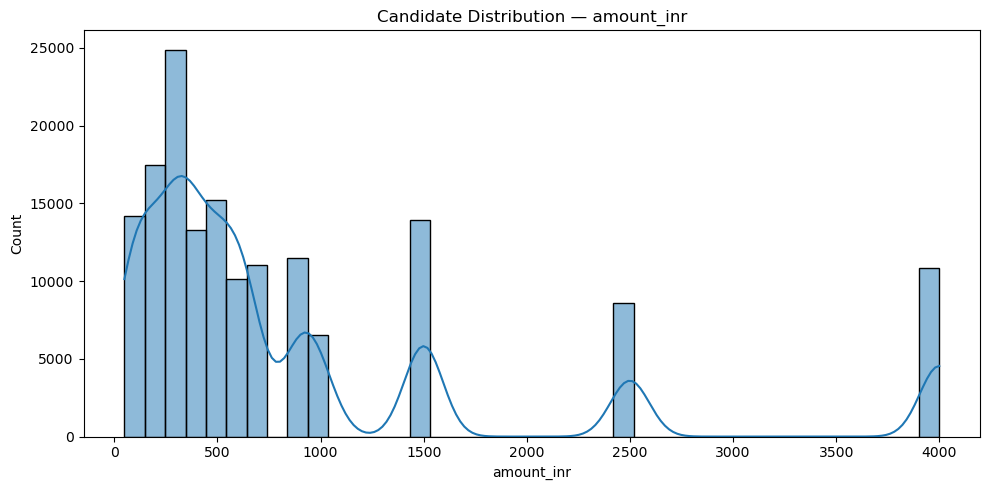

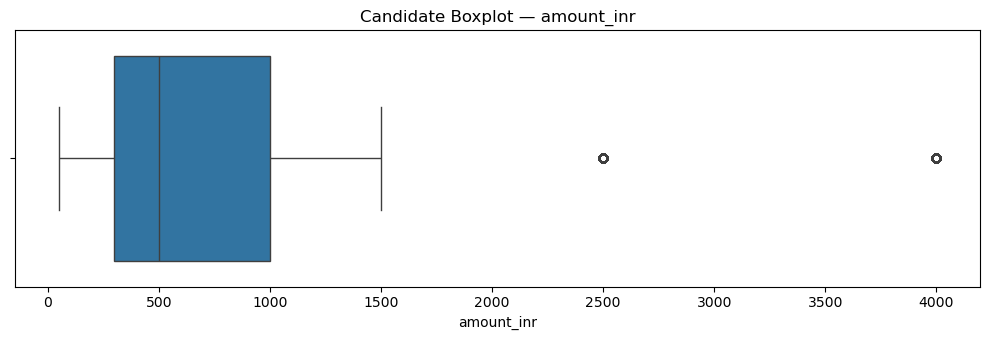

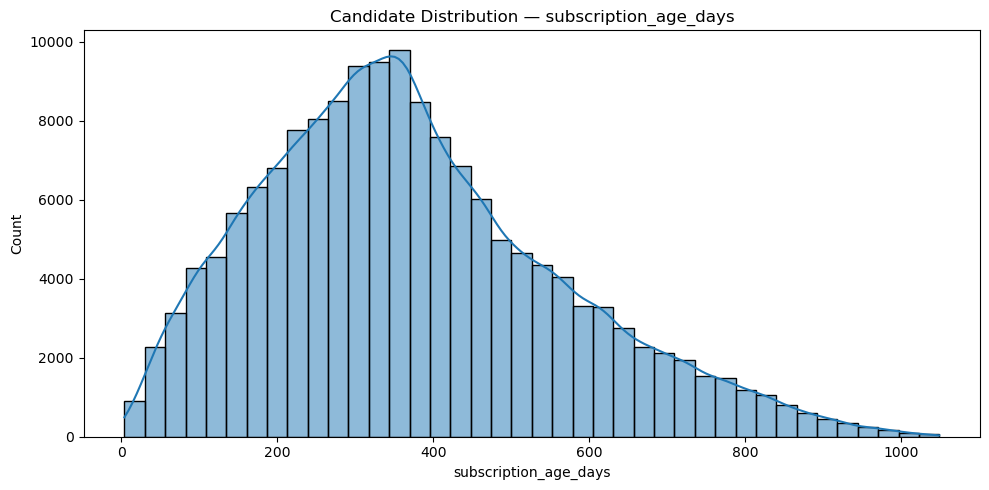

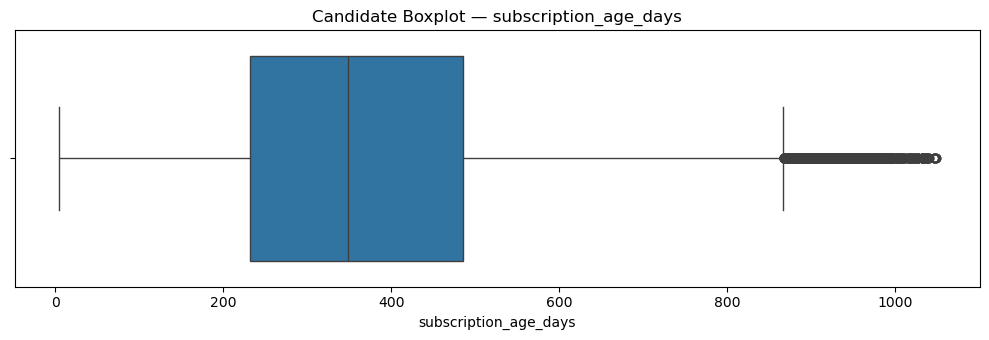

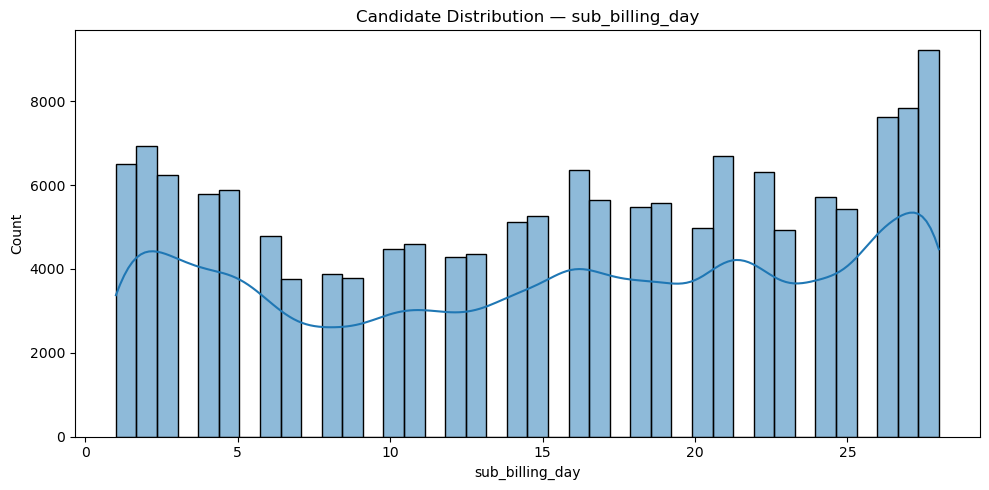

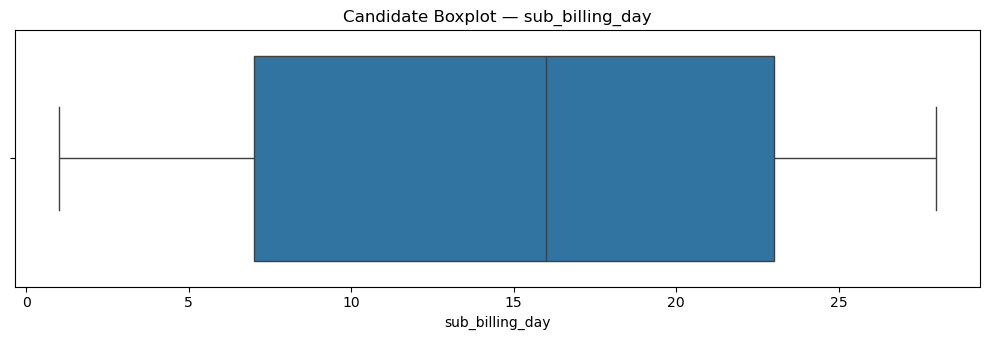

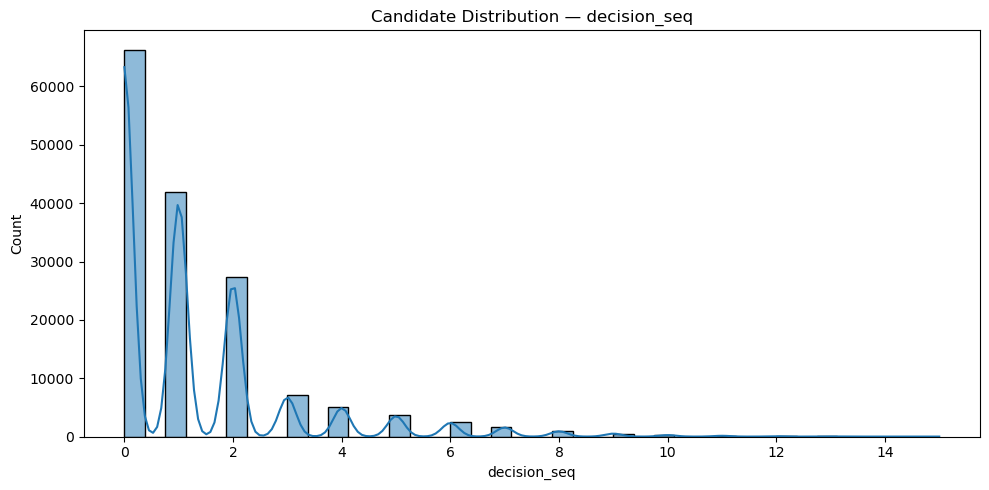

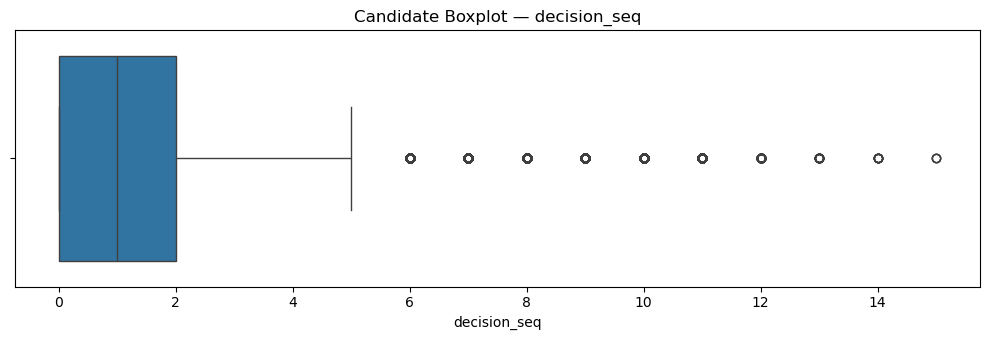

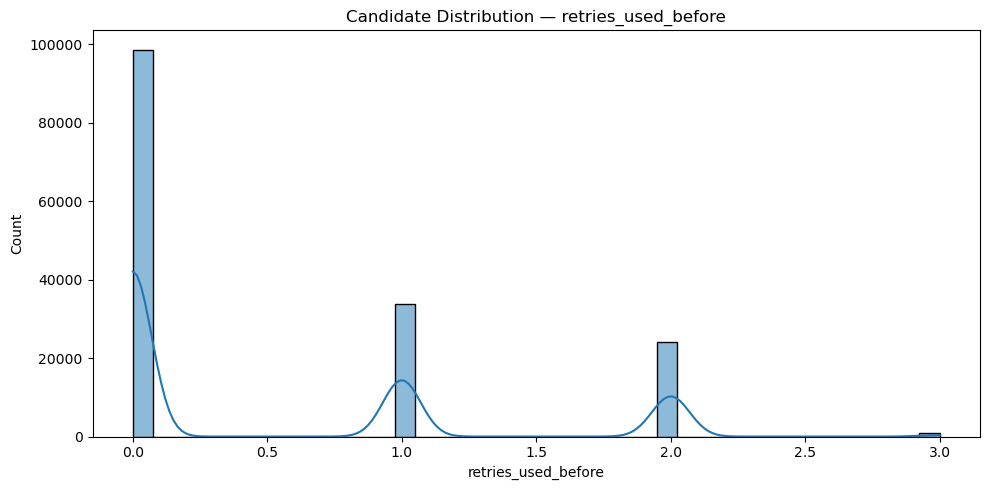

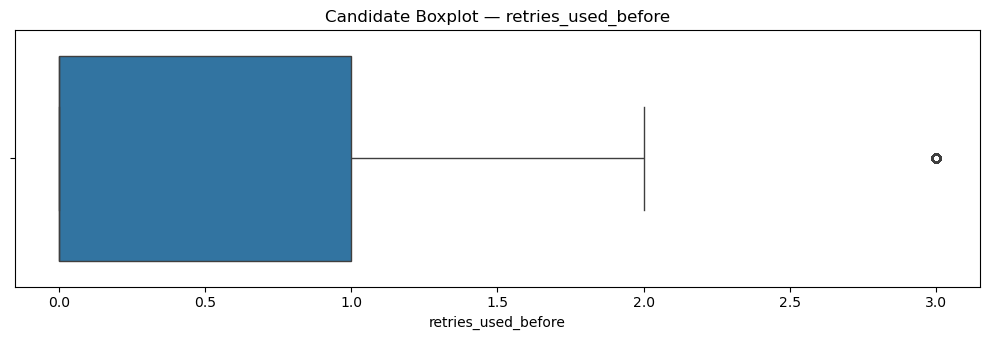

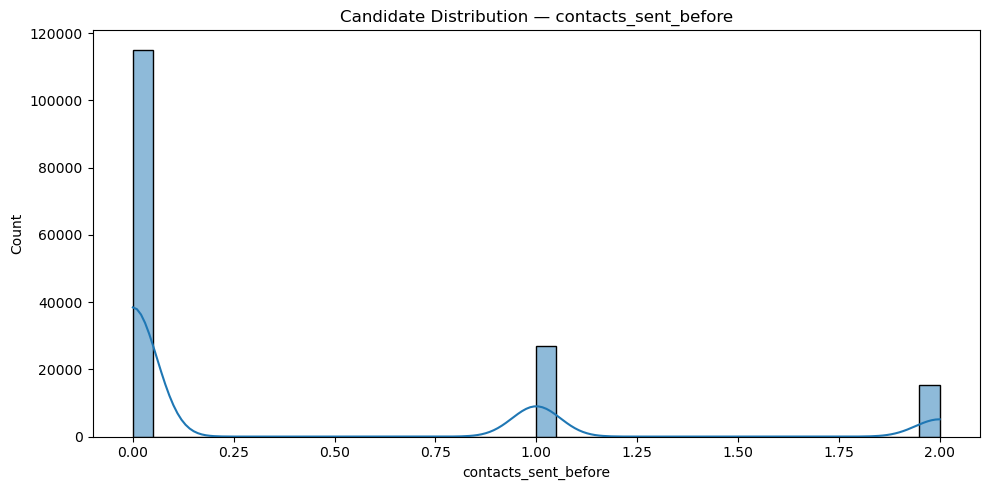

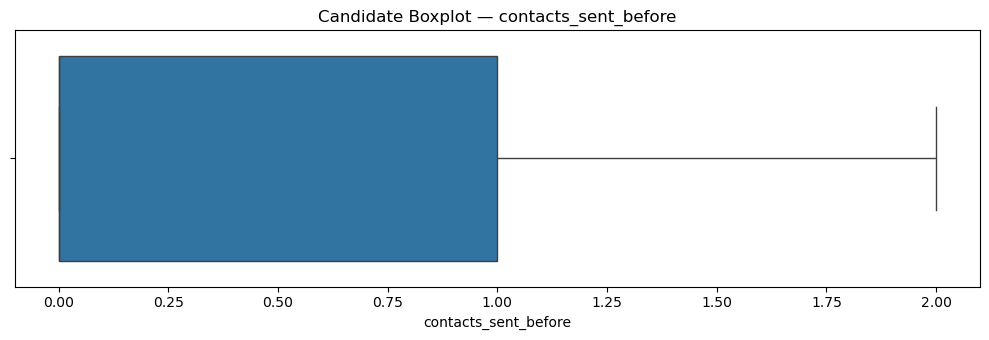

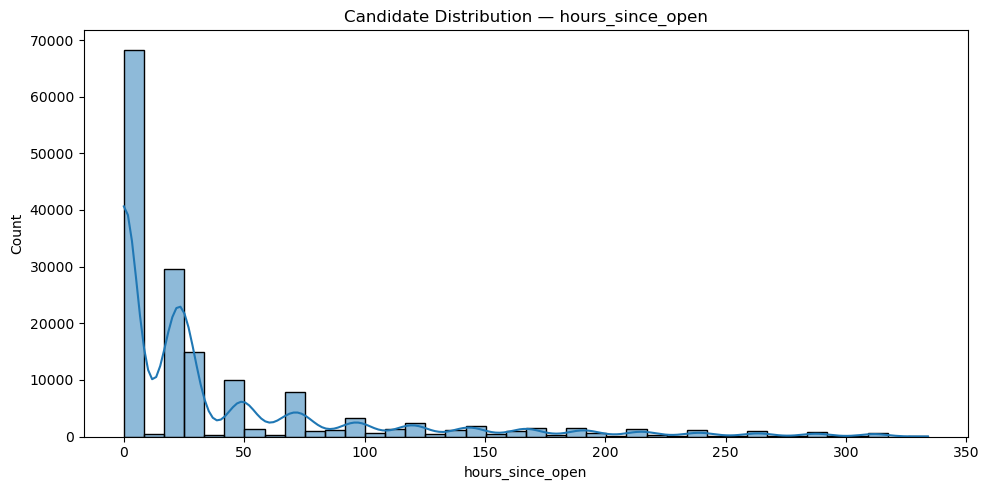

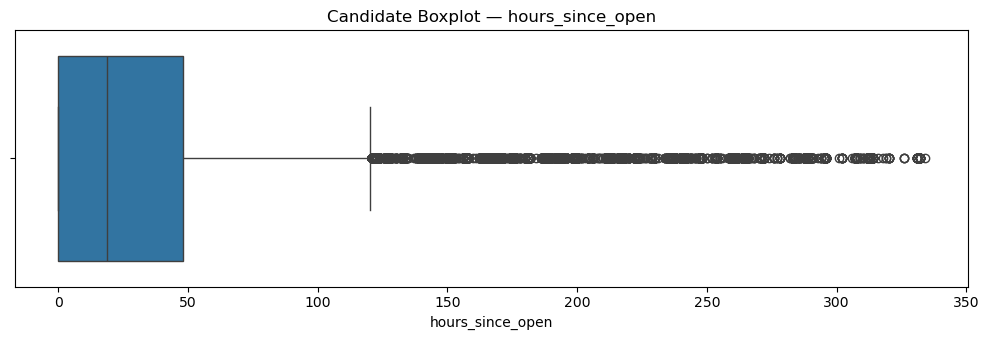

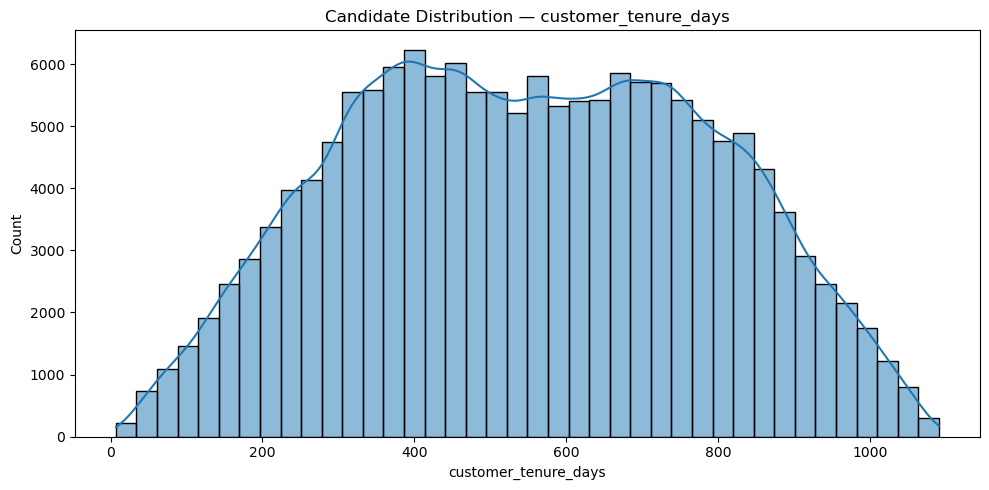

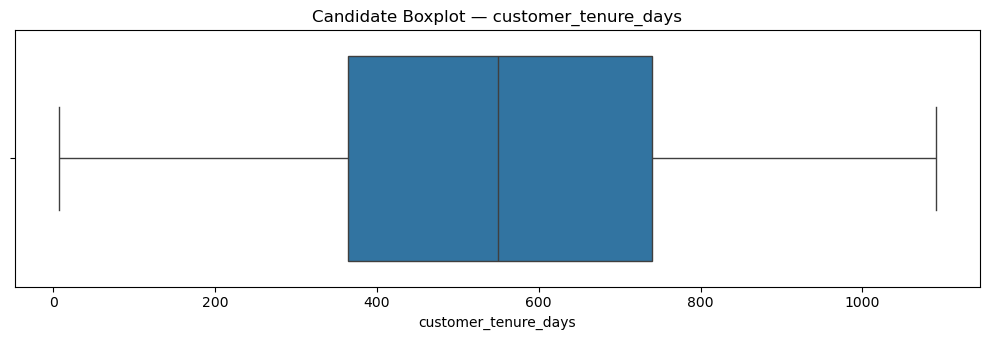

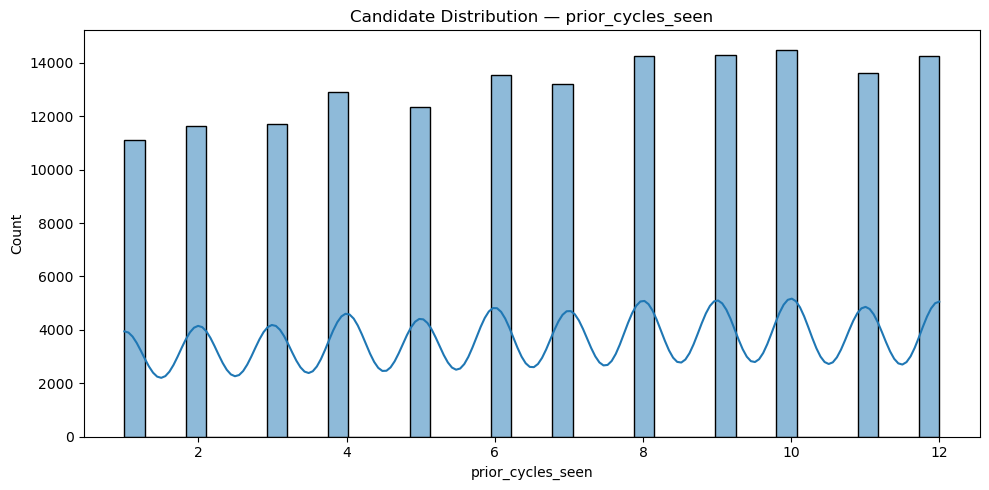

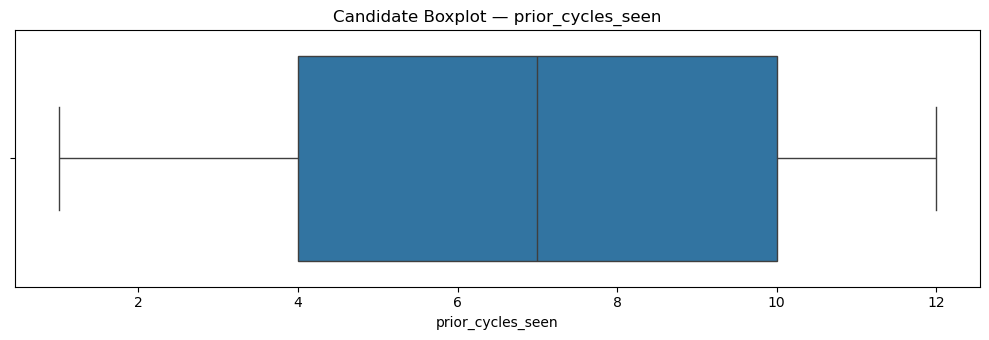

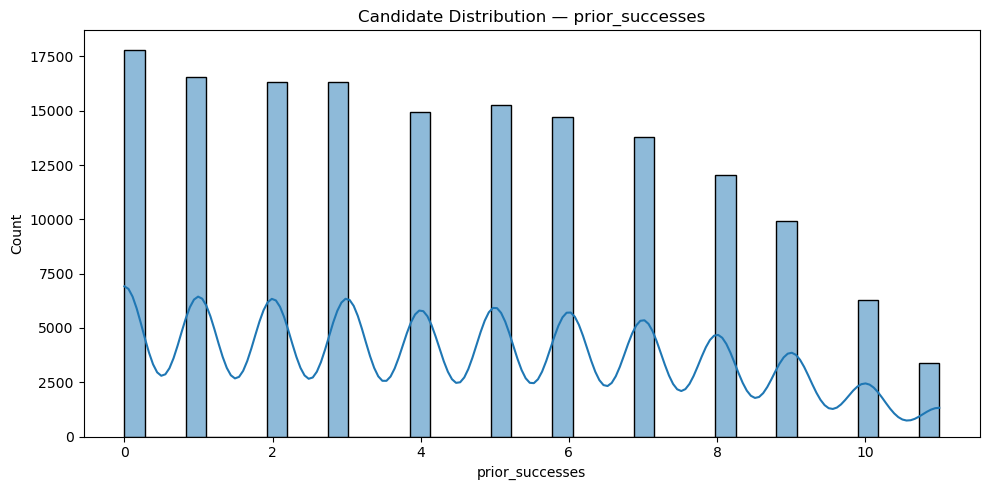

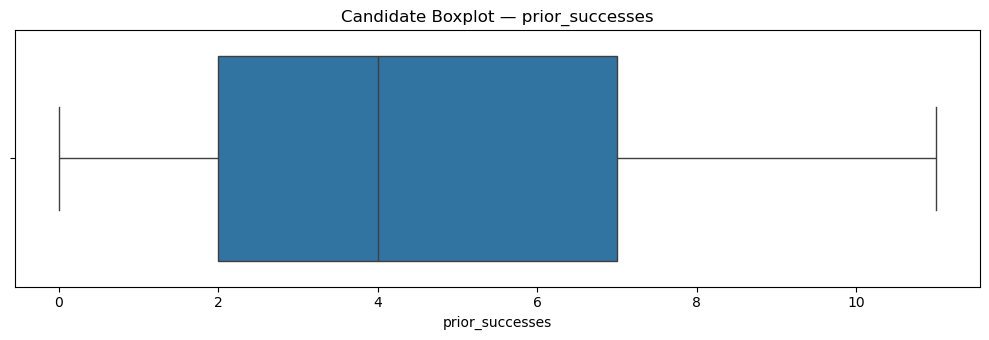

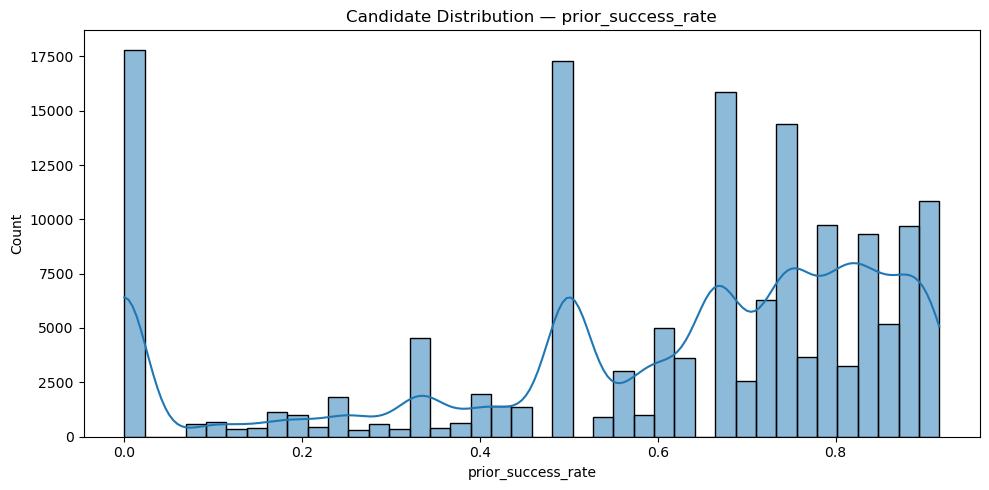

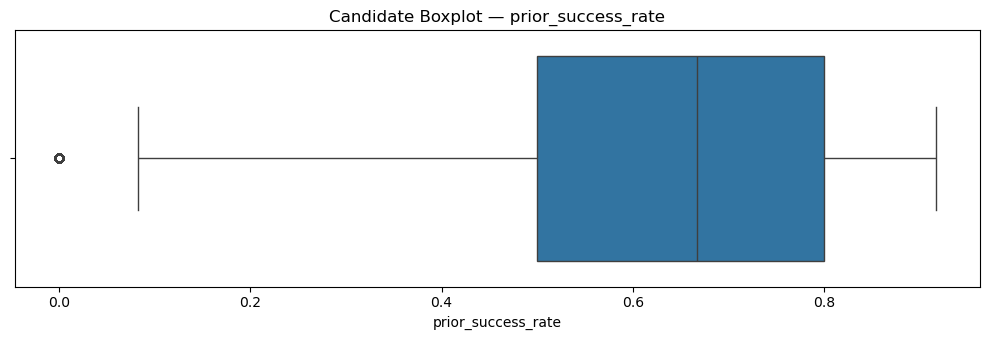

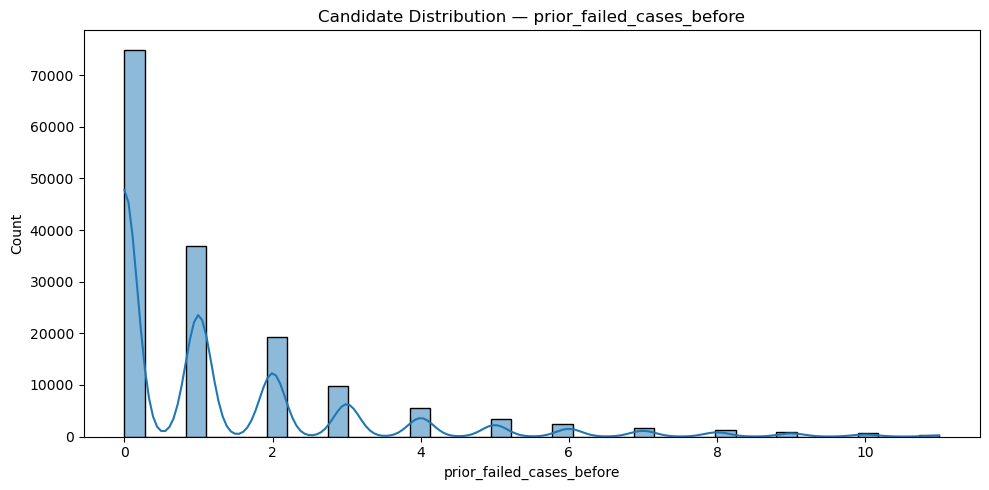

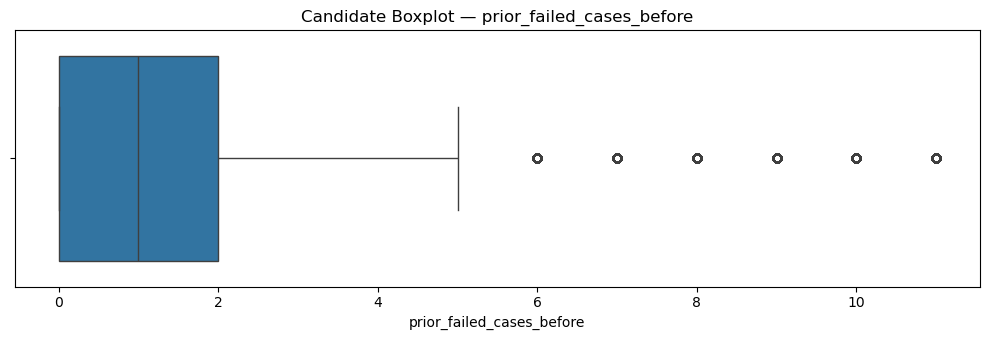

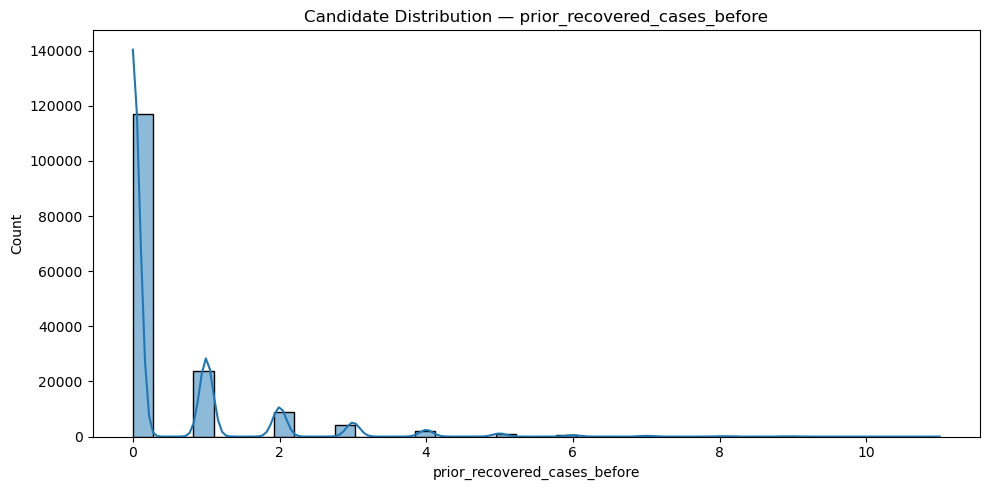

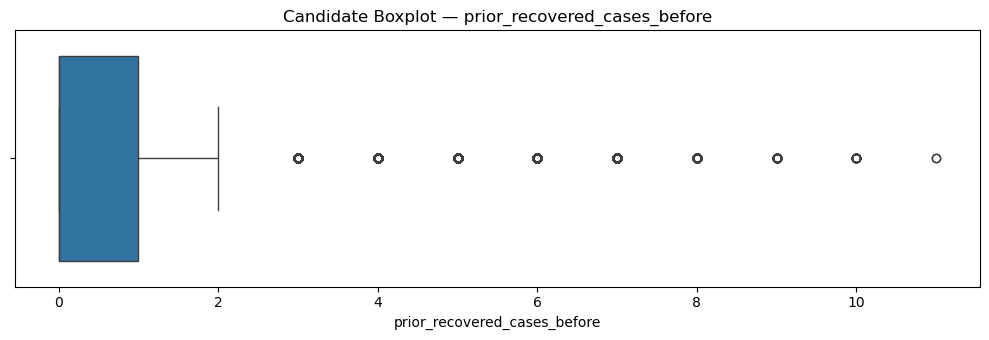

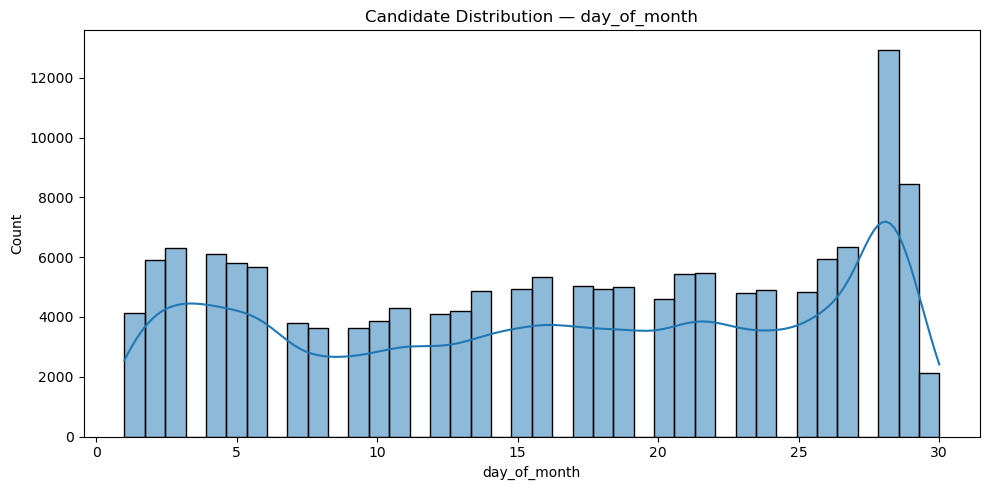

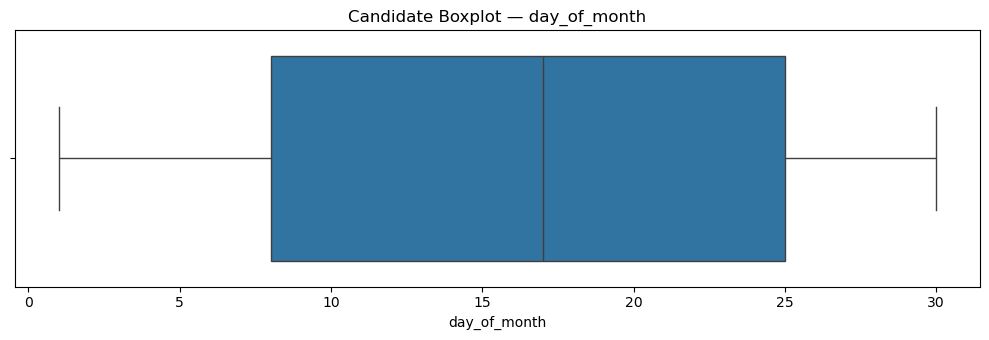

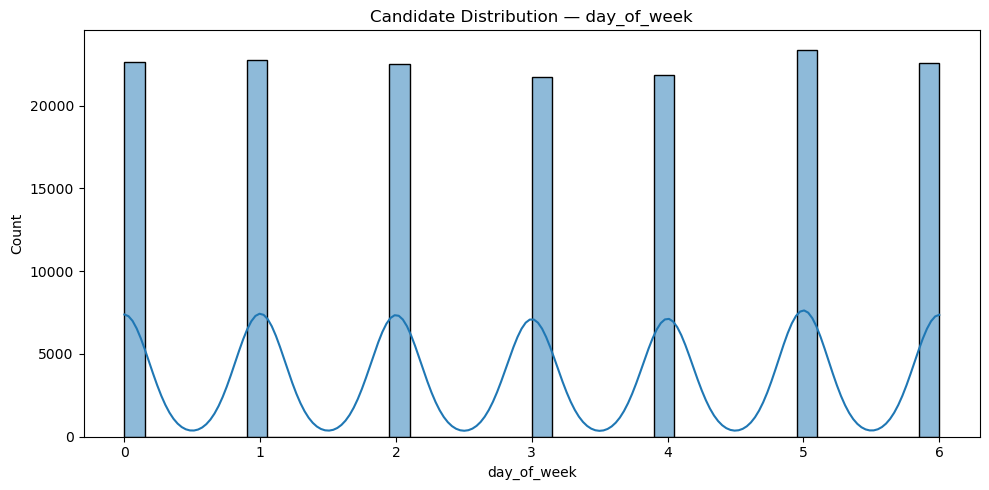

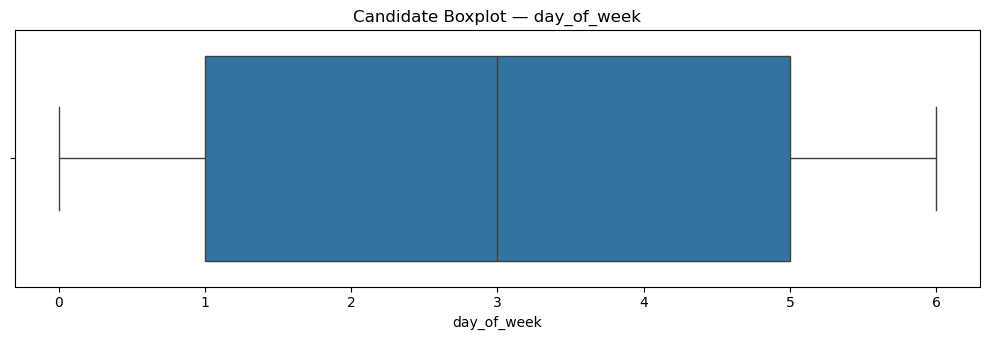

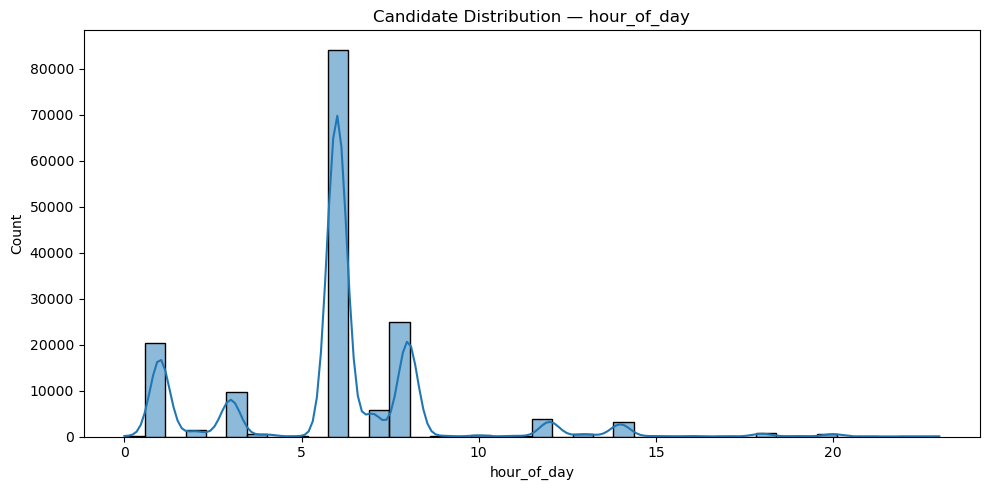

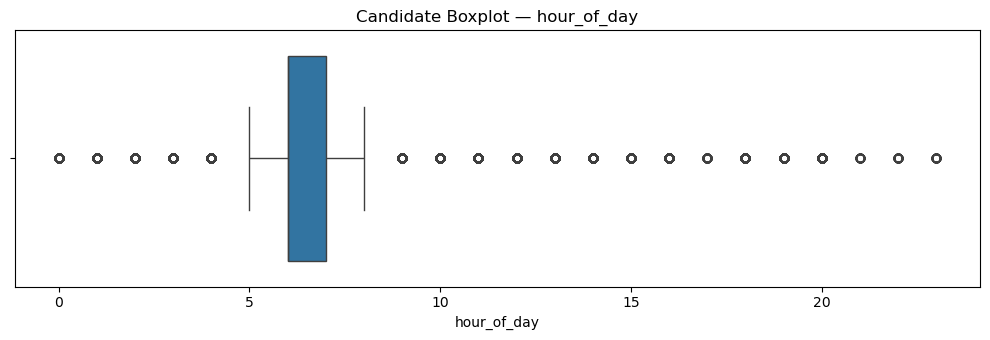

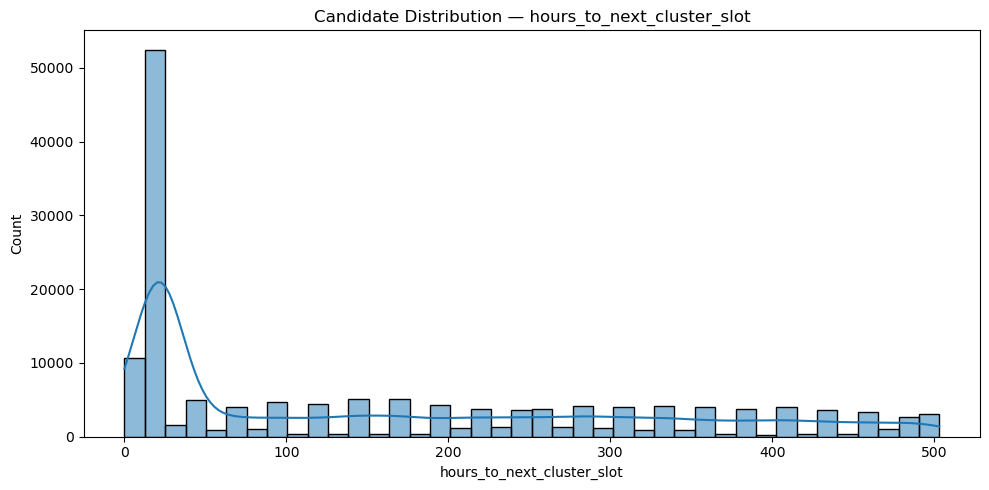

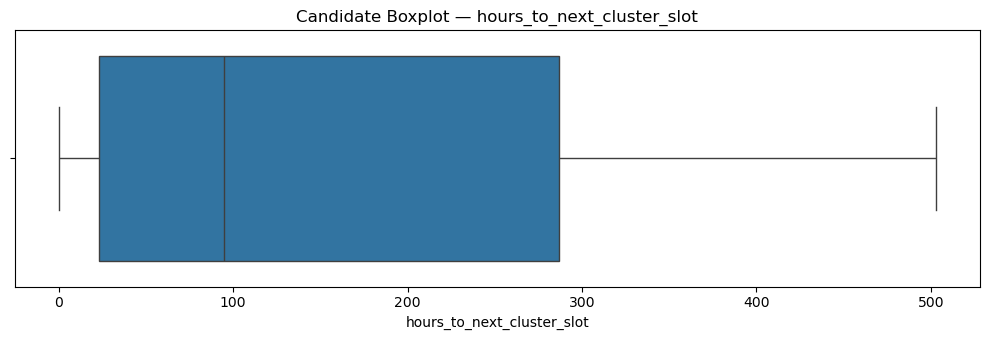

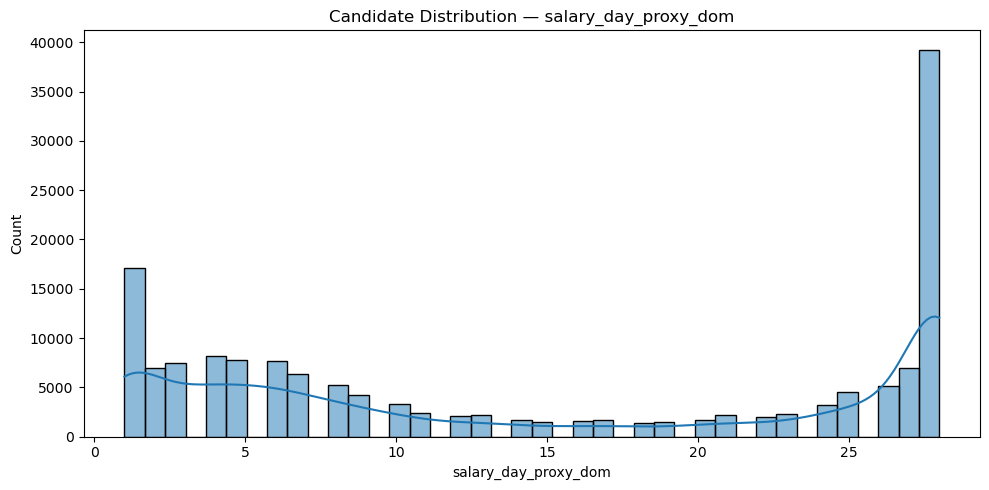

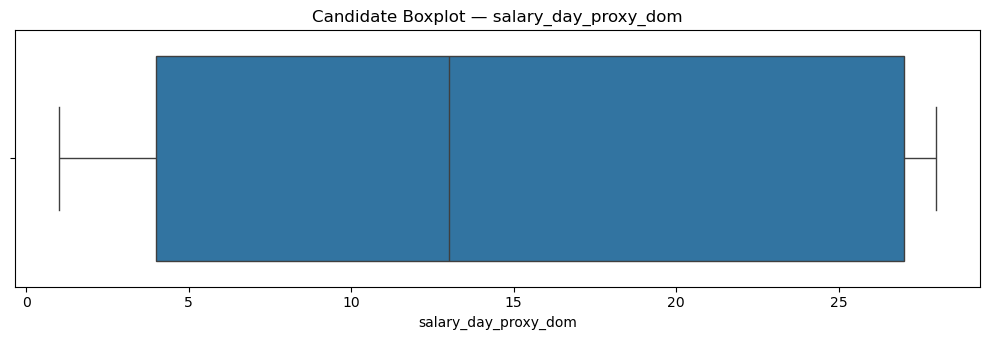

In [11]:

for col in numeric_candidates:
    plt.figure(figsize=(10, 5))
    sns.histplot(
        data=ml,
        x=col,
        bins=40,
        kde=True,
    )
    plt.title(f"Candidate Distribution — {col}")
    save_plot(f"feature_{col}_distribution.png")

    plt.figure(figsize=(10, 3.5))
    sns.boxplot(
        data=ml,
        x=col,
    )
    plt.title(f"Candidate Boxplot — {col}")
    save_plot(f"feature_{col}_boxplot.png")


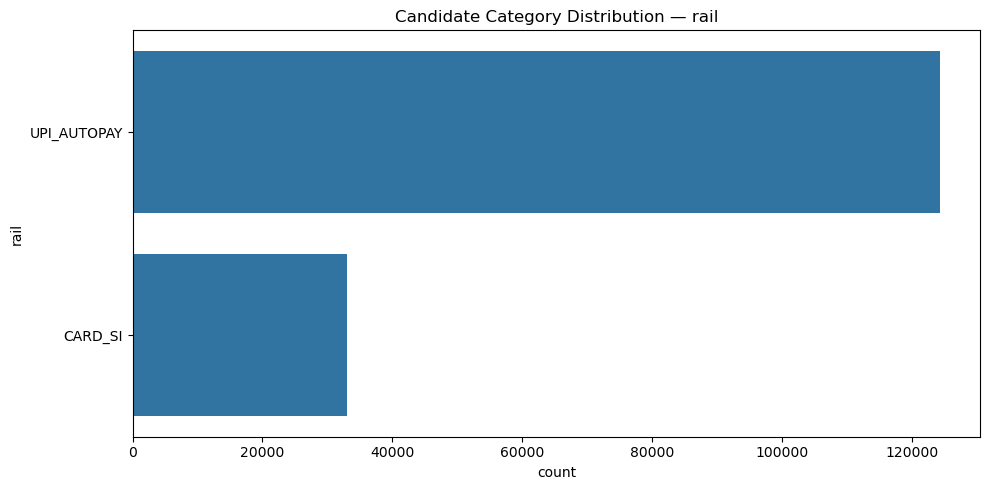

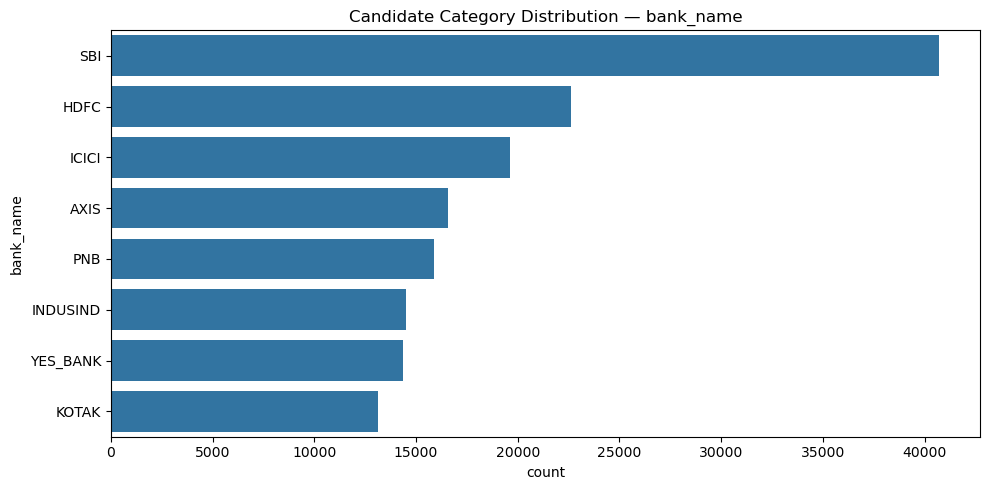

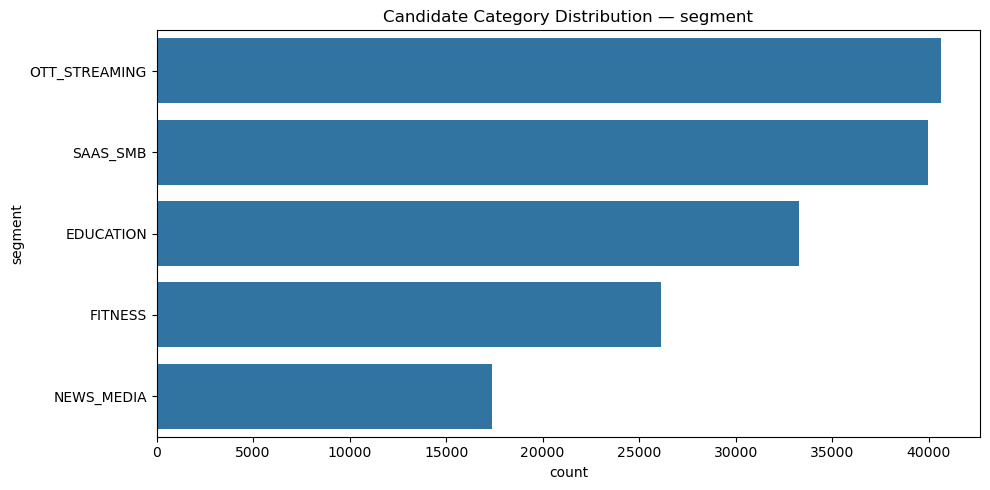

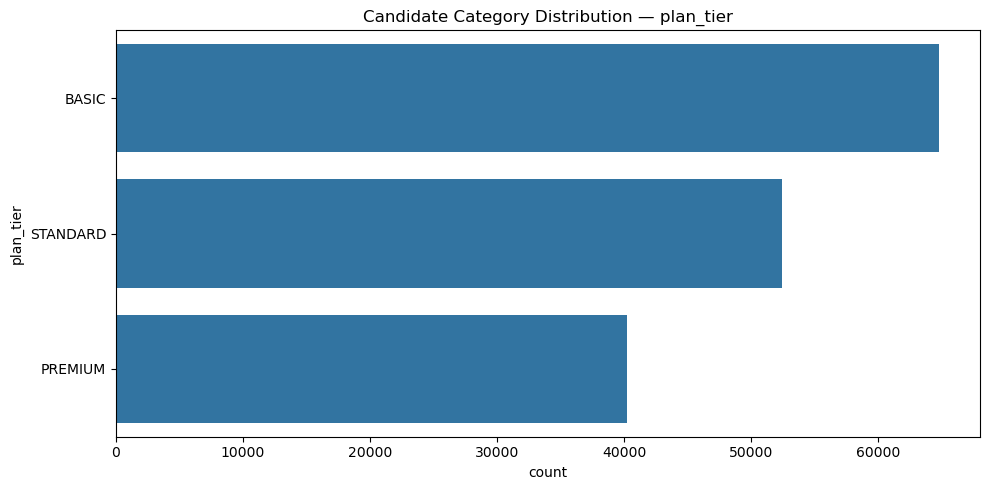

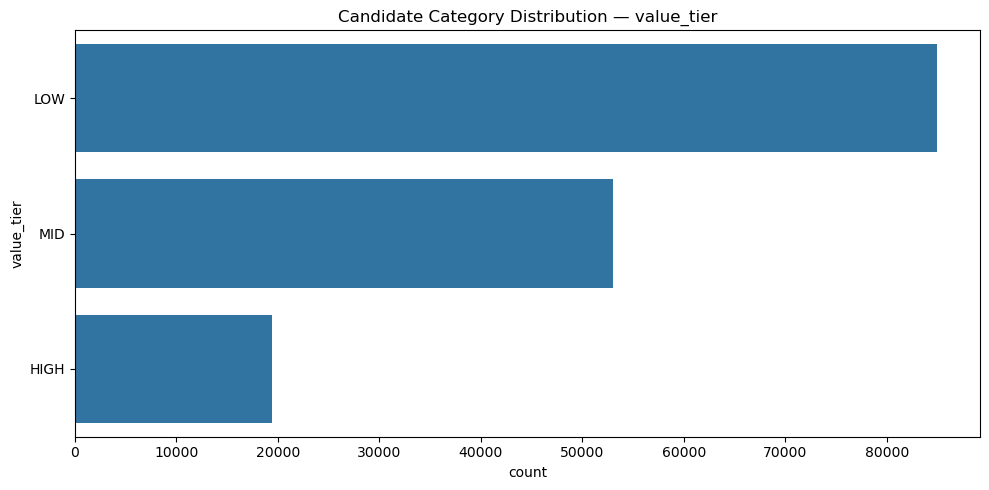

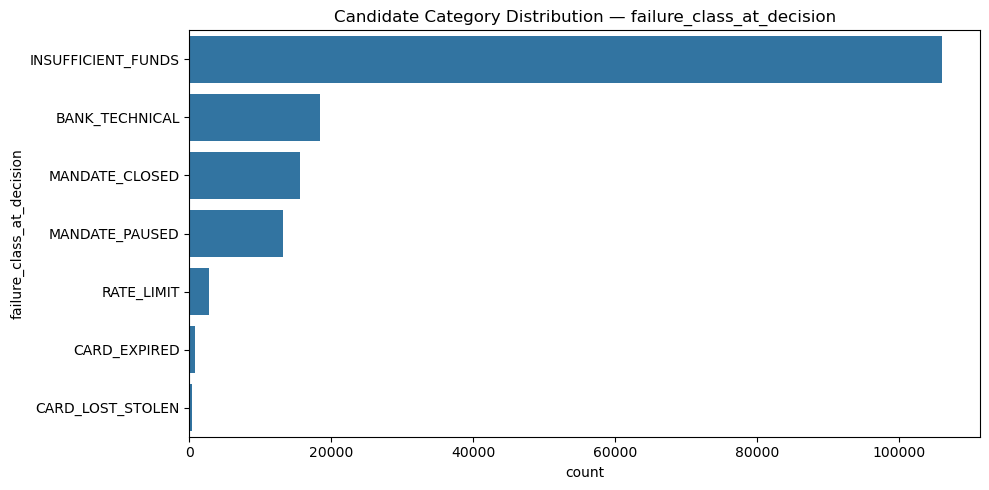

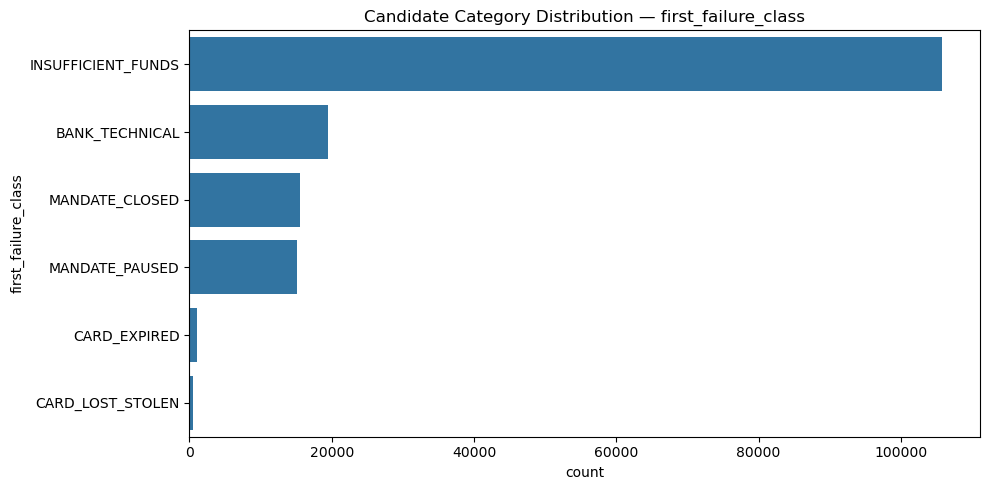

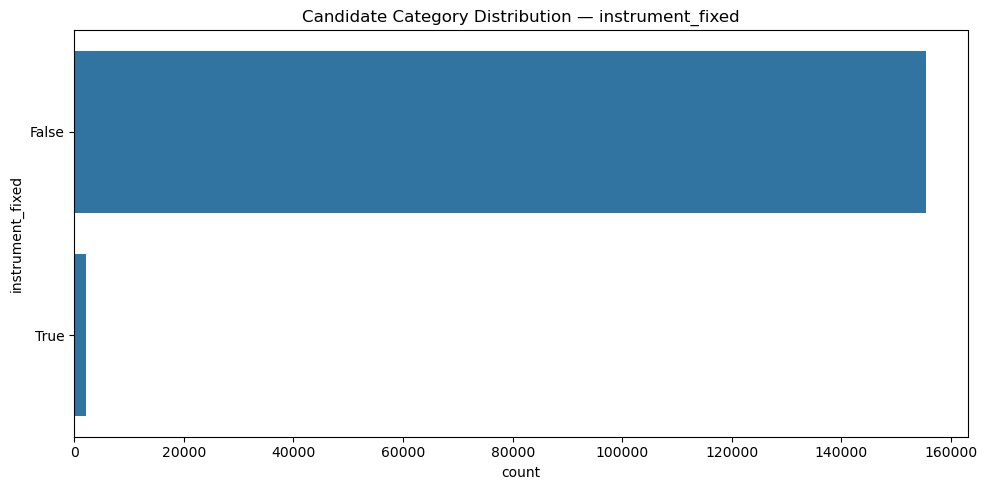

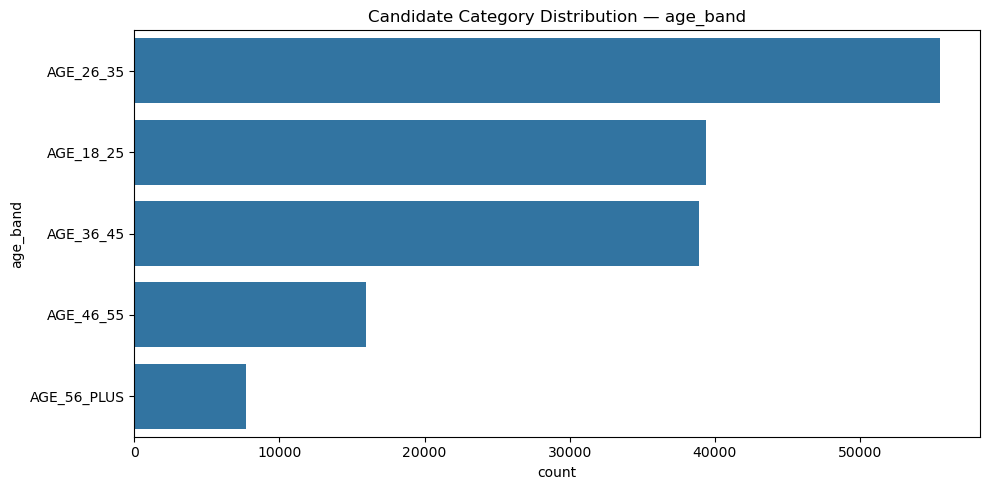

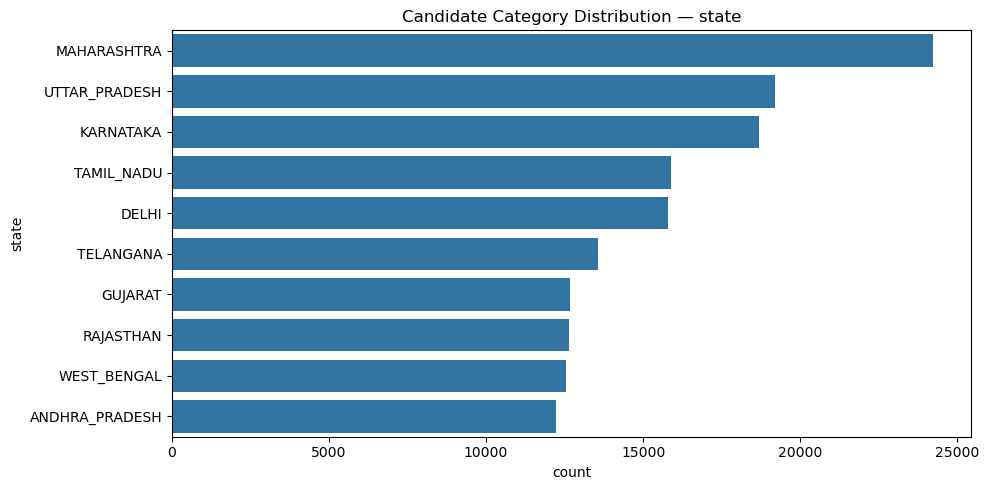

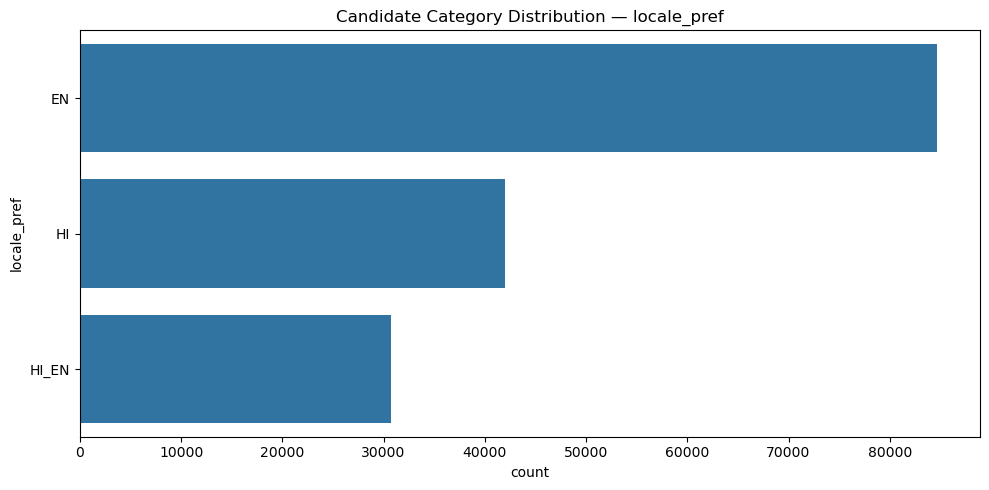

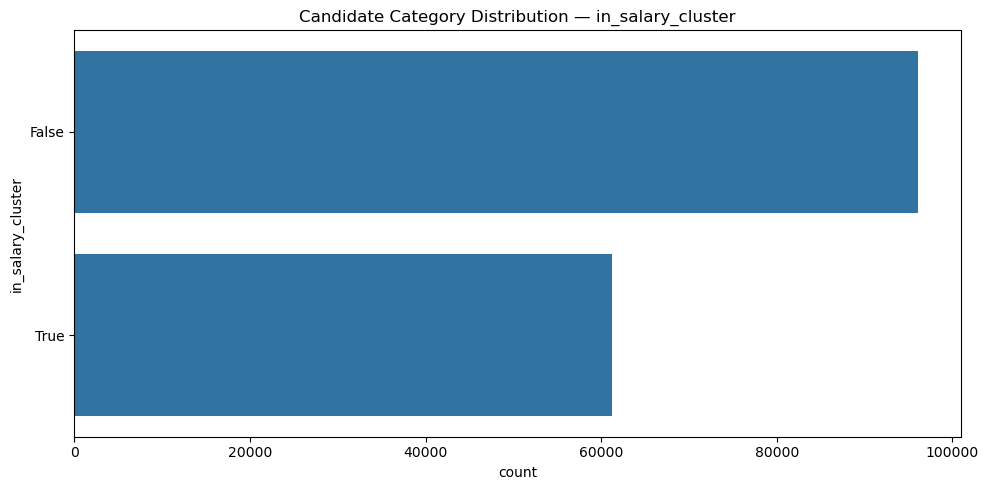

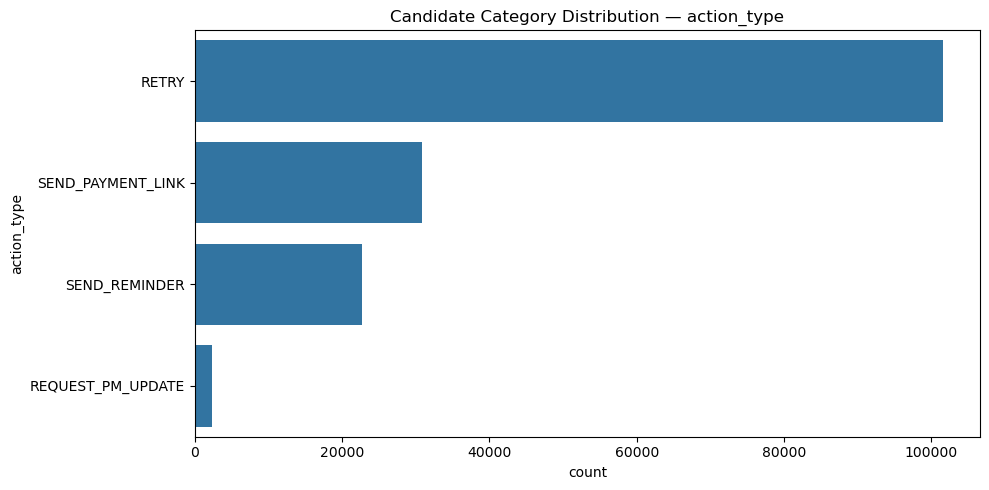

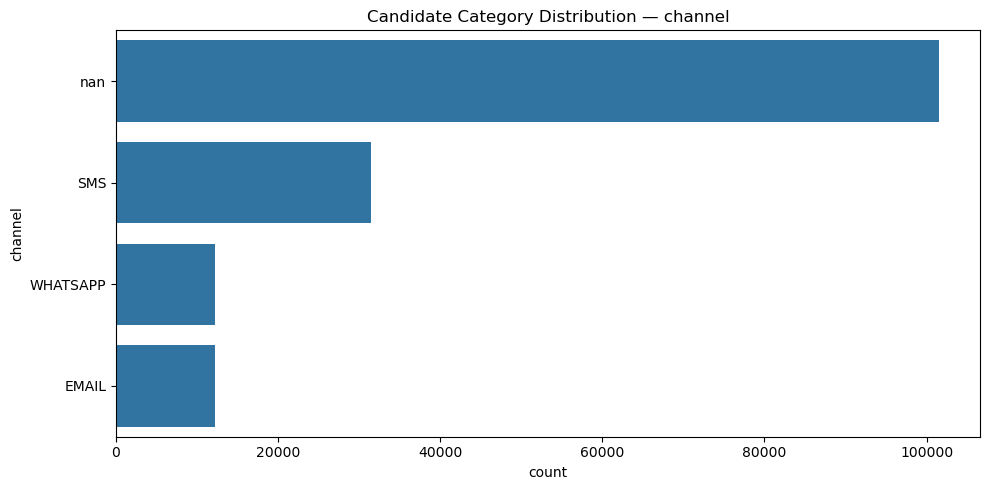

In [12]:

for col in categorical_candidates:
    counts = ml[col].value_counts(
        dropna=False
    ).head(20)

    plot_df = pd.DataFrame({
        col: counts.index.astype(str),
        "count": counts.values,
    })

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=plot_df,
        x="count",
        y=col,
        errorbar=None,
    )
    plt.title(f"Candidate Category Distribution — {col}")
    save_plot(f"feature_{col}_categories.png")


## 9. Nonlinear Numeric Feature × Target Analysis

Correlation alone is insufficient for this project.

For numeric features, quantile-bin the feature and visualize observed success
across the bins to reveal nonlinear structure.

Skipped amount_inr: Invalid object type at position 0
Skipped subscription_age_days: Invalid object type at position 0
Skipped sub_billing_day: Invalid object type at position 0
Skipped decision_seq: Invalid object type at position 0
Skipped hours_since_open: Invalid object type at position 0
Skipped customer_tenure_days: Invalid object type at position 0
Skipped prior_cycles_seen: Invalid object type at position 0
Skipped prior_successes: Invalid object type at position 0
Skipped prior_success_rate: Invalid object type at position 0
Skipped prior_failed_cases_before: Invalid object type at position 0
Skipped prior_recovered_cases_before: Invalid object type at position 0
Skipped day_of_month: Invalid object type at position 0
Skipped hour_of_day: Invalid object type at position 0
Skipped hours_to_next_cluster_slot: Invalid object type at position 0
Skipped salary_day_proxy_dom: Invalid object type at position 0


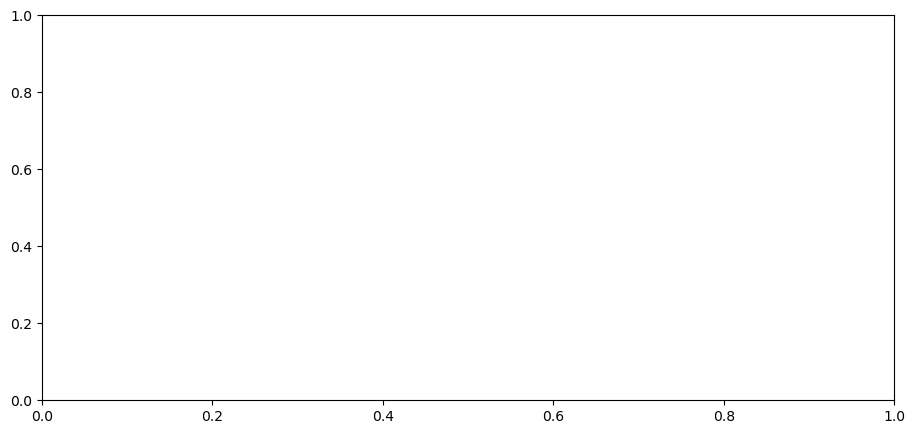

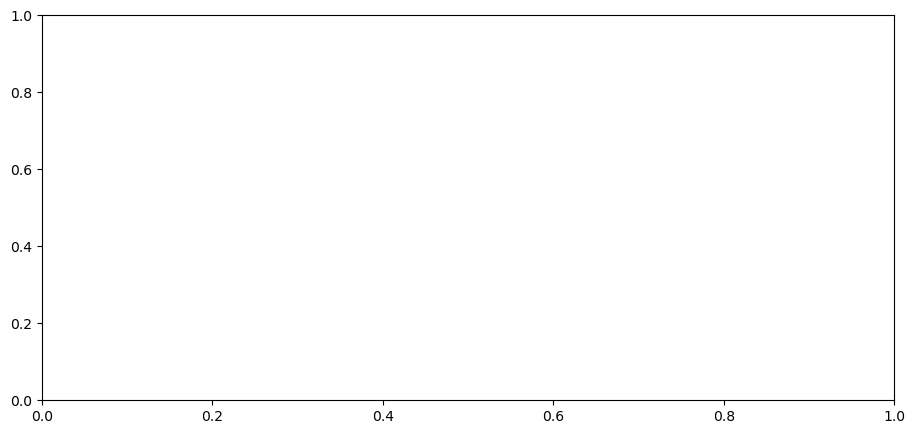

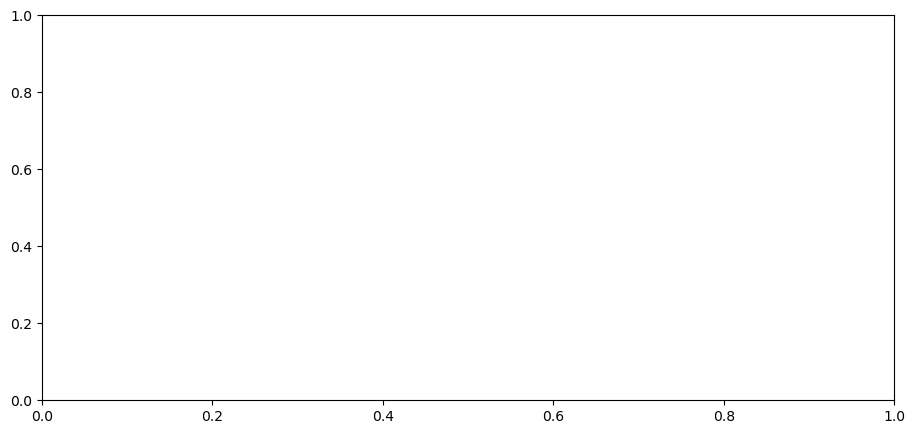

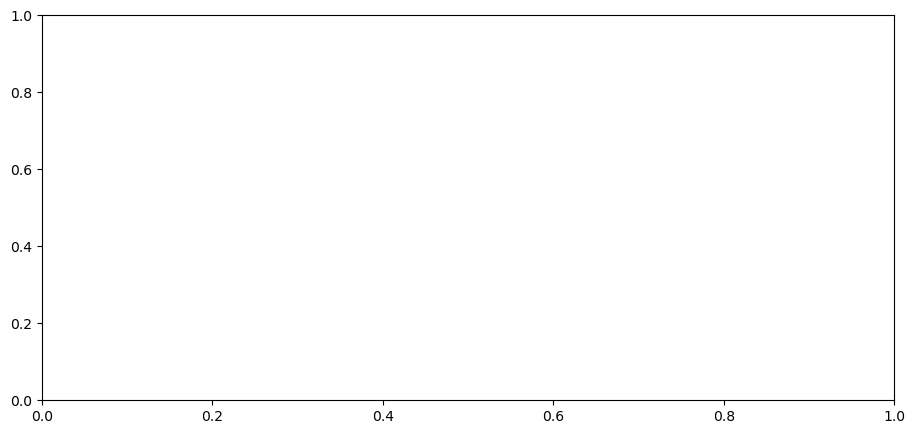

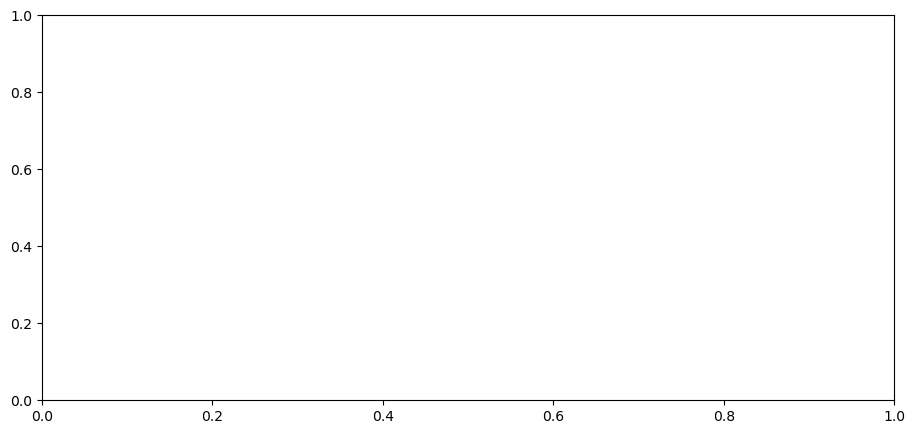

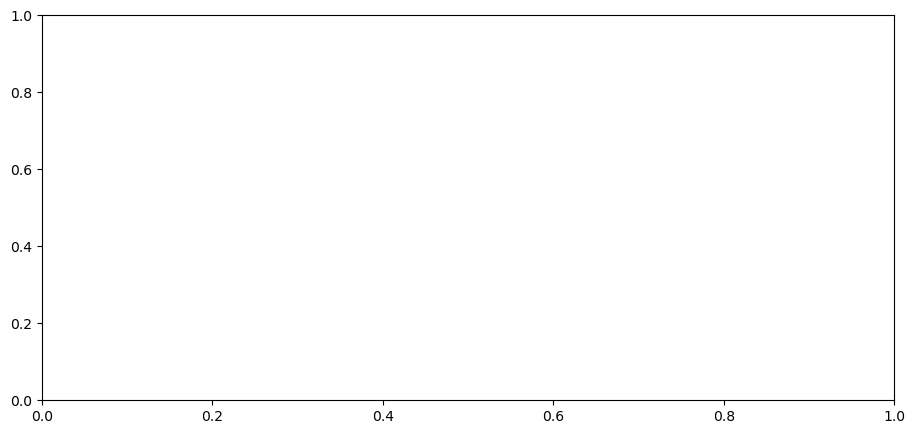

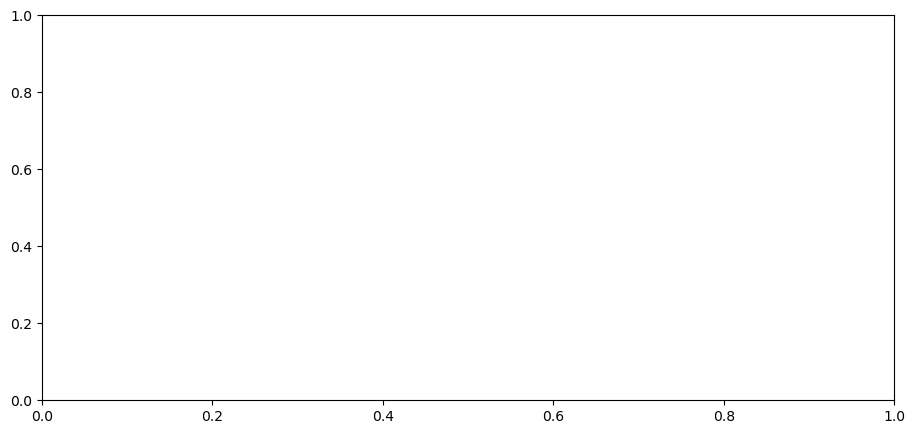

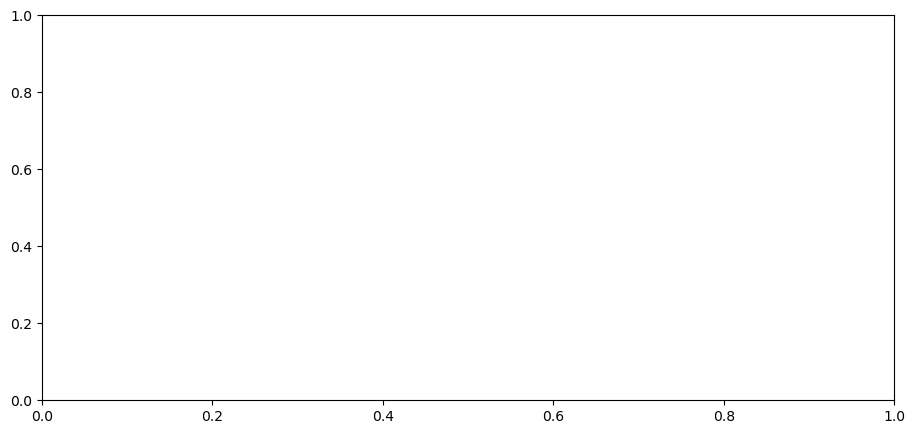

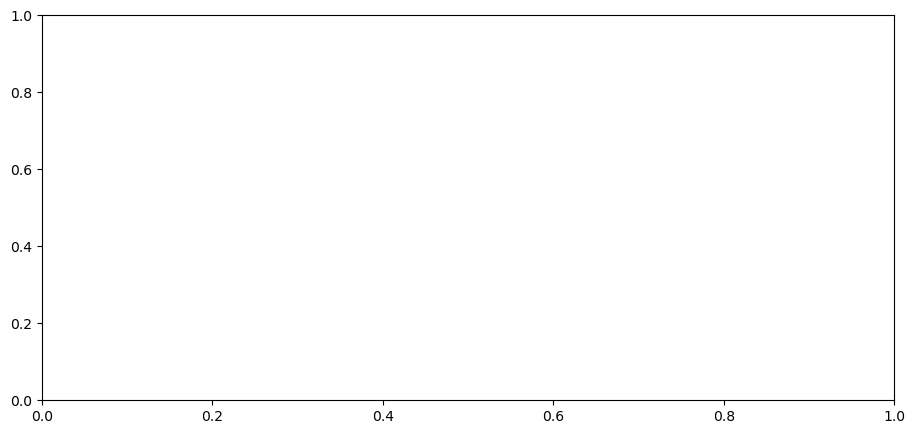

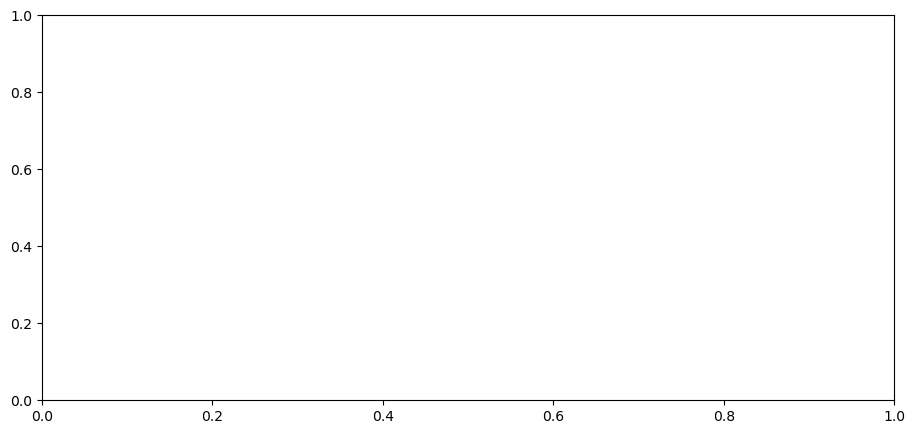

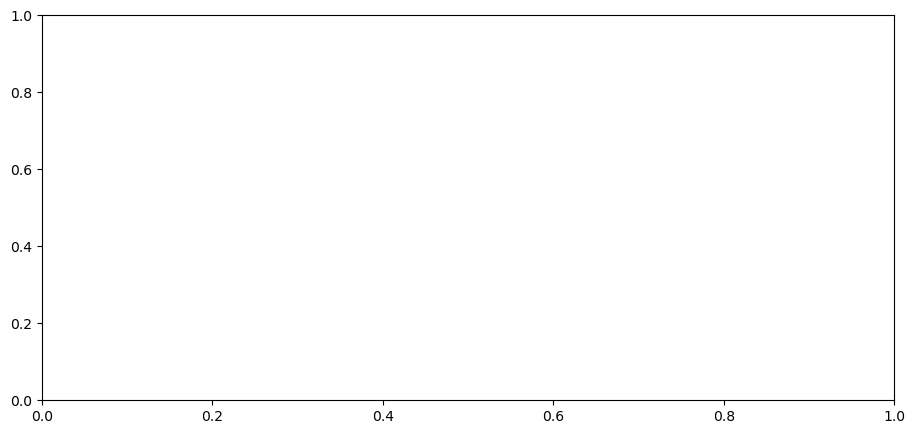

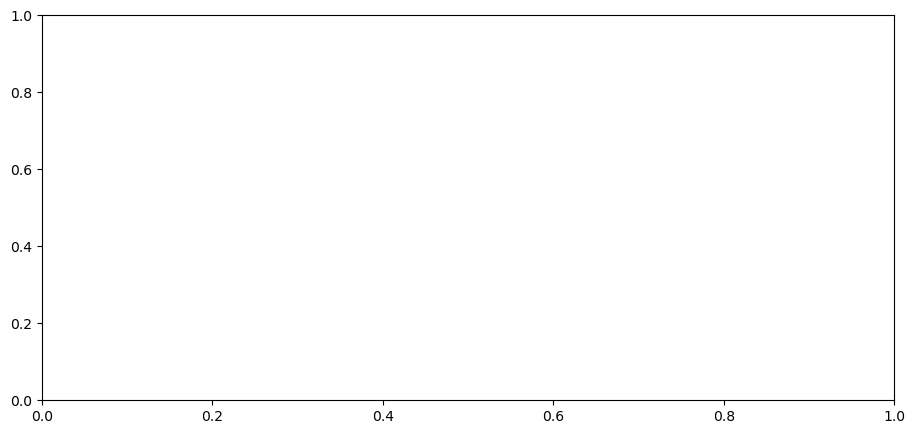

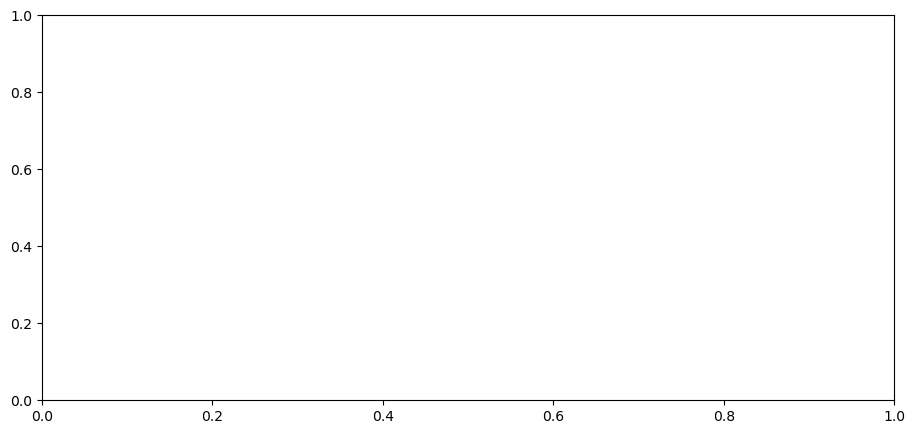

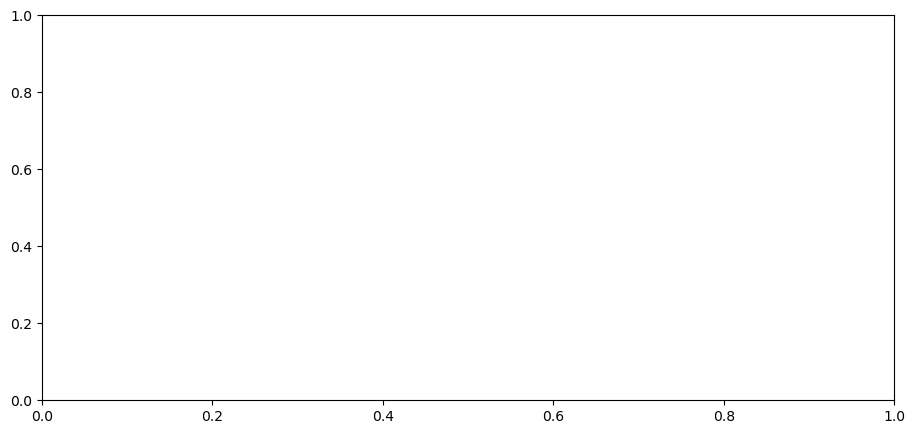

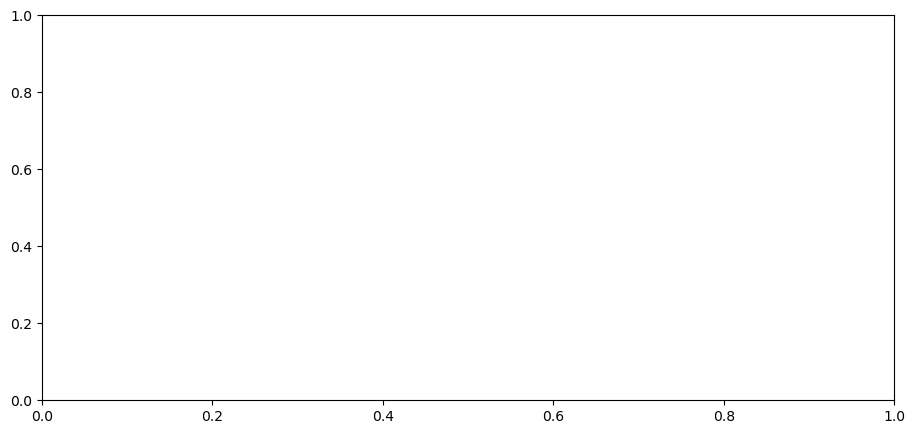

In [13]:

numeric_relationships = []

for col in numeric_candidates:
    temp = ml[[col, target_col]].dropna()

    if temp[col].nunique() < 8 or len(temp) < 100:
        continue

    try:
        temp["quantile_bin"] = pd.qcut(
            temp[col],
            q=8,
            duplicates="drop",
        )

        summary = (
            temp.groupby(
                "quantile_bin",
                observed=False
            )[target_col]
            .agg(
                observations="size",
                observed_success_rate="mean",
            )
            .reset_index()
        )

        if len(summary) < 2:
            continue

        plt.figure(figsize=(11, 5))
        sns.lineplot(
            data=summary,
            x="quantile_bin",
            y="observed_success_rate",
            marker="o",
        )
        plt.ylim(0, 1)
        plt.title(
            f"Observed Success Across {col} Quantiles"
        )
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("Observed Success Rate")
        save_plot(
            f"feature_{col}_quantile_success.png"
        )

        spread = (
            summary["observed_success_rate"].max()
            - summary["observed_success_rate"].min()
        )

        numeric_relationships.append({
            "feature": col,
            "min_binned_rate": summary["observed_success_rate"].min(),
            "max_binned_rate": summary["observed_success_rate"].max(),
            "max_minus_min_rate": spread,
        })

    except Exception as exc:
        print(f"Skipped {col}: {exc}")

numeric_relationships = pd.DataFrame(
    numeric_relationships
)

if not numeric_relationships.empty:
    numeric_relationships = numeric_relationships.sort_values(
        "max_minus_min_rate",
        ascending=False,
    )
    display(numeric_relationships)
    numeric_relationships.to_csv(
        REPORT_DIR / "numeric_nonlinear_relationships.csv",
        index=False,
    )


## 10. Intervention Interaction Heatmaps

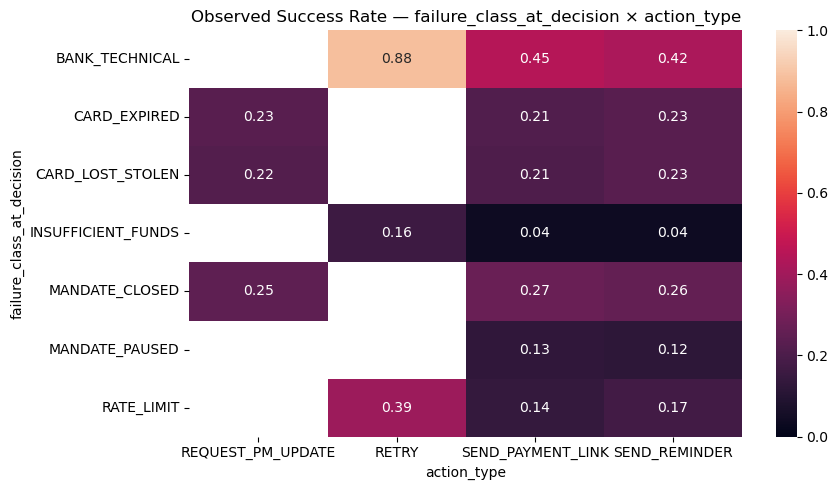

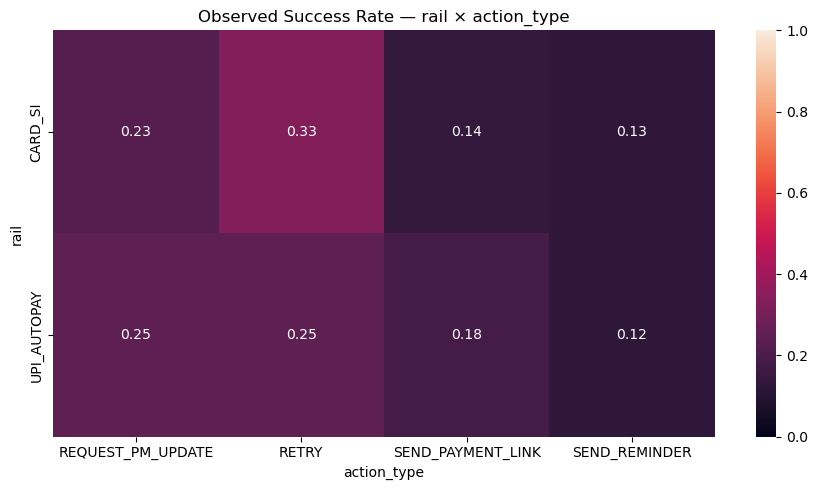

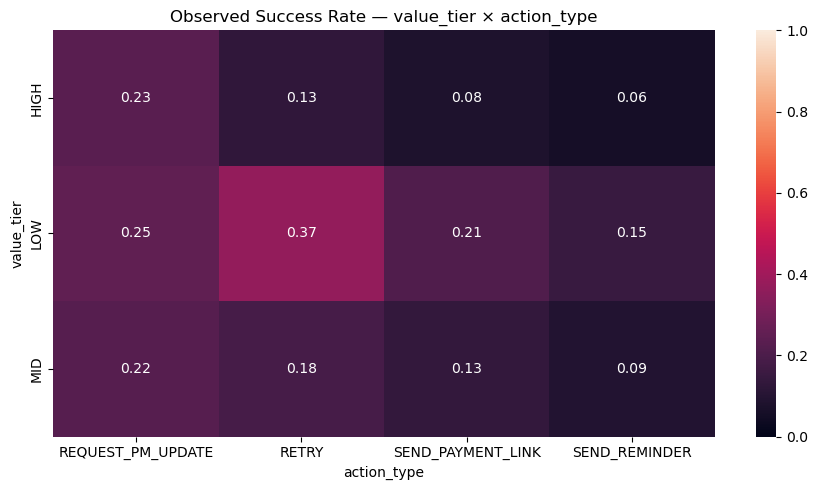

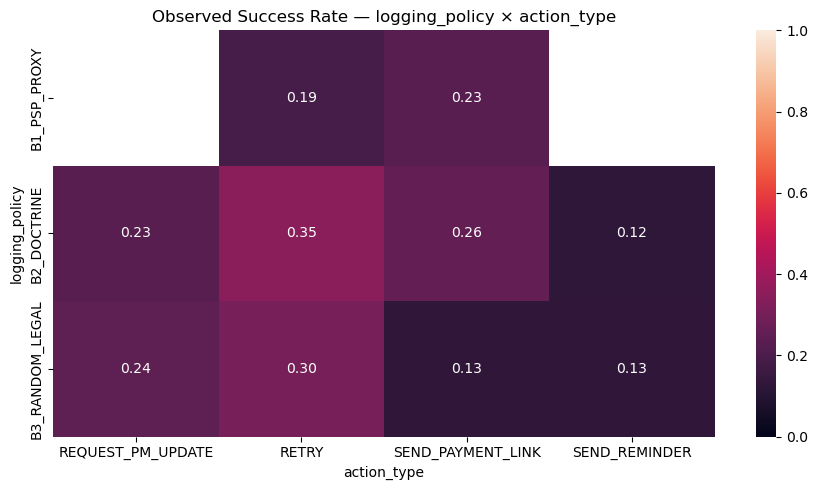

In [14]:

interaction_specs = [
    ("failure_class", "action_type"),
    ("failure_class_at_decision", "action_type"),
    ("rail", "action_type"),
    ("value_tier", "action_type"),
    ("logging_policy", "action_type"),
]

interaction_summaries = []

for x_col, action_col in interaction_specs:

    if not {x_col, action_col}.issubset(ml.columns):
        continue

    summary = (
        ml.groupby(
            [x_col, action_col],
            dropna=False
        )[target_col]
        .agg(
            observations="size",
            observed_success_rate="mean",
        )
        .reset_index()
    )

    summary = summary[
        summary["observations"] >= 30
    ]

    if summary.empty:
        continue

    pivot = summary.pivot(
        index=x_col,
        columns=action_col,
        values="observed_success_rate",
    )

    if pivot.empty:
        continue

    plt.figure(
        figsize=(
            max(9, len(pivot.columns) * 1.5),
            max(5, len(pivot.index) * 0.6),
        )
    )

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".2f",
        vmin=0,
        vmax=1,
    )
    plt.title(
        f"Observed Success Rate — {x_col} × {action_col}"
    )
    plt.xlabel(action_col)
    plt.ylabel(x_col)
    save_plot(
        f"interaction_{x_col}_x_{action_col}_success.png"
    )

    summary["dimension"] = x_col
    interaction_summaries.append(summary)

if interaction_summaries:
    pd.concat(
        interaction_summaries,
        ignore_index=True,
    ).to_csv(
        REPORT_DIR / "intervention_interaction_summaries.csv",
        index=False,
    )


## 11. Salary / Timing Proxy Deep Dive

Only observable proxies are allowed.

The latent true salary day is never loaded.

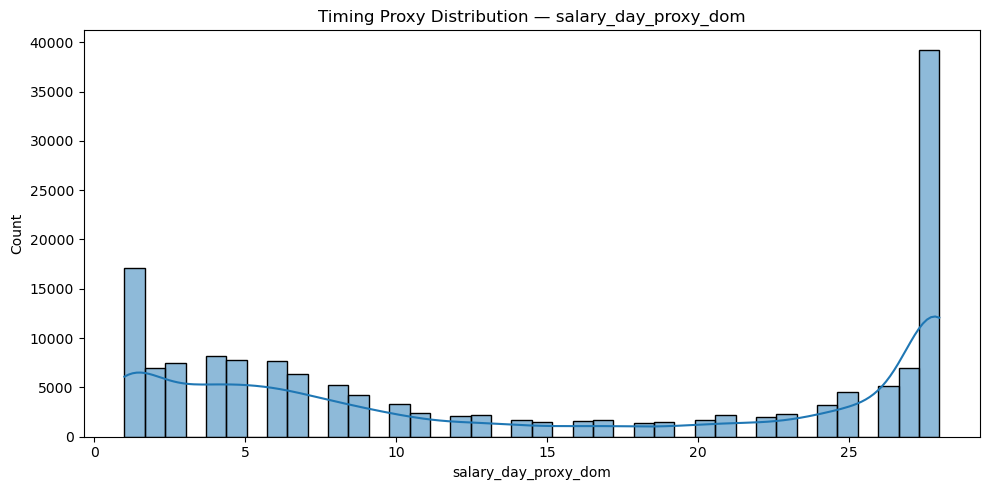

Skipped timing relationship for salary_day_proxy_dom: Invalid object type at position 0


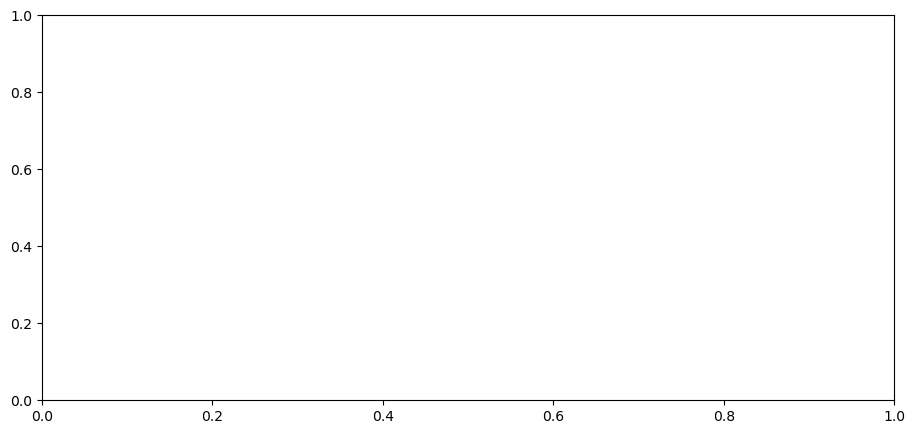

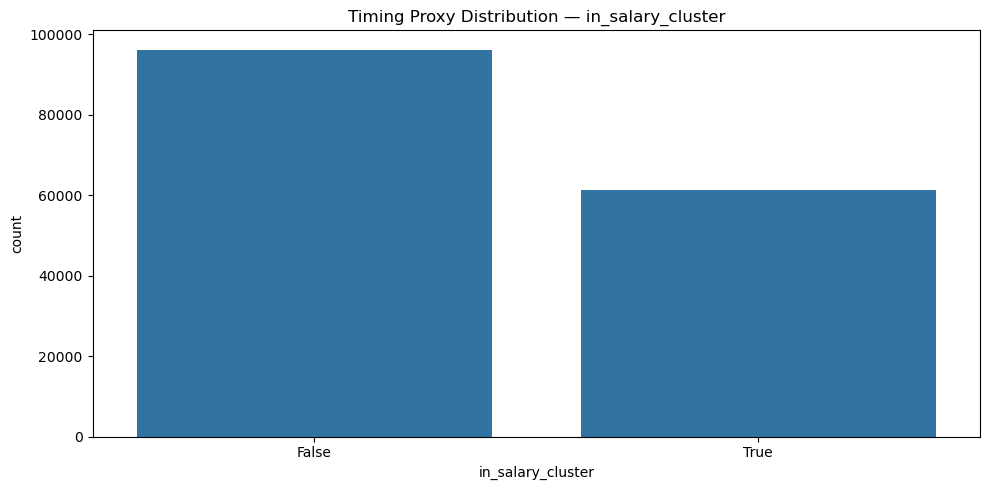

In [15]:

timing_cols = [
    "proxy_days_to_salary",
    "salary_day_proxy_dom",
    "time_since_first_failure_days",
    "tenure_months",
    "in_salary_cluster",
]

for col in timing_cols:

    if col not in ml.columns:
        continue

    # Distribution
    plt.figure(figsize=(10, 5))
    if pd.api.types.is_bool_dtype(ml[col]):
        sns.countplot(data=ml, x=col)
    elif pd.api.types.is_numeric_dtype(ml[col]):
        sns.histplot(
            data=ml,
            x=col,
            bins=40,
            kde=True,
        )
    else:
        order = ml[col].value_counts().head(20).index
        sns.countplot(
            data=ml,
            x=col,
            order=order,
        )
        plt.xticks(rotation=45, ha="right")

    plt.title(f"Timing Proxy Distribution — {col}")
    save_plot(
        f"timing_{col}_distribution.png"
    )

    # Target relationship
    if pd.api.types.is_numeric_dtype(ml[col]) and ml[col].nunique() > 10:
        temp = ml[[col, target_col]].dropna()

        if len(temp) >= 100:
            try:
                temp["bin"] = pd.qcut(
                    temp[col],
                    q=8,
                    duplicates="drop",
                )

                summary = (
                    temp.groupby(
                        "bin",
                        observed=False
                    )[target_col]
                    .agg(
                        observations="size",
                        observed_success_rate="mean",
                    )
                    .reset_index()
                )

                plt.figure(figsize=(11, 5))
                sns.lineplot(
                    data=summary,
                    x="bin",
                    y="observed_success_rate",
                    marker="o",
                )
                plt.ylim(0, 1)
                plt.xticks(rotation=45, ha="right")
                plt.title(
                    f"Observed Success Across {col} Quantiles"
                )
                save_plot(
                    f"timing_{col}_success.png"
                )
            except Exception as exc:
                print(f"Skipped timing relationship for {col}: {exc}")

# Dedicated action × timing if both exist
if {"action_type", "proxy_days_to_salary"}.issubset(ml.columns):

    temp = ml[
        ["action_type", "proxy_days_to_salary", target_col]
    ].dropna()

    if len(temp) >= 100:
        temp["salary_bin"] = pd.qcut(
            temp["proxy_days_to_salary"],
            q=6,
            duplicates="drop",
        )

        summary = (
            temp.groupby(
                ["salary_bin", "action_type"],
                observed=False
            )[target_col]
            .agg(
                observations="size",
                observed_success_rate="mean",
            )
            .reset_index()
        )

        pivot = summary.pivot(
            index="salary_bin",
            columns="action_type",
            values="observed_success_rate",
        )

        plt.figure(
            figsize=(
                max(10, len(pivot.columns) * 1.5),
                6
            )
        )
        sns.heatmap(
            pivot,
            annot=True,
            fmt=".2f",
            vmin=0,
            vmax=1,
        )
        plt.title(
            "Observed Success — Salary Proximity × Action"
        )
        plt.xlabel("Action")
        plt.ylabel("Salary-Proximity Bin")
        save_plot(
            "salary_proximity_x_action_success.png"
        )


## 12. Target-Stratified Distributions

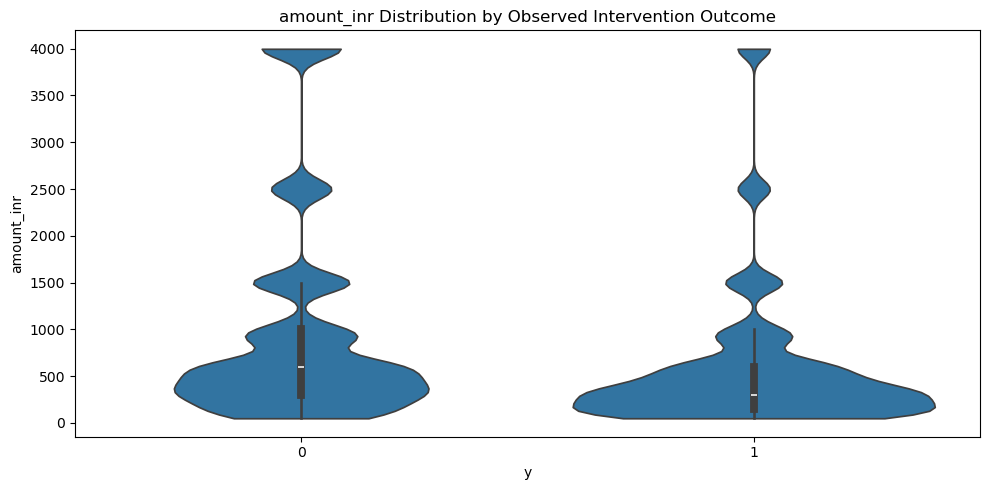

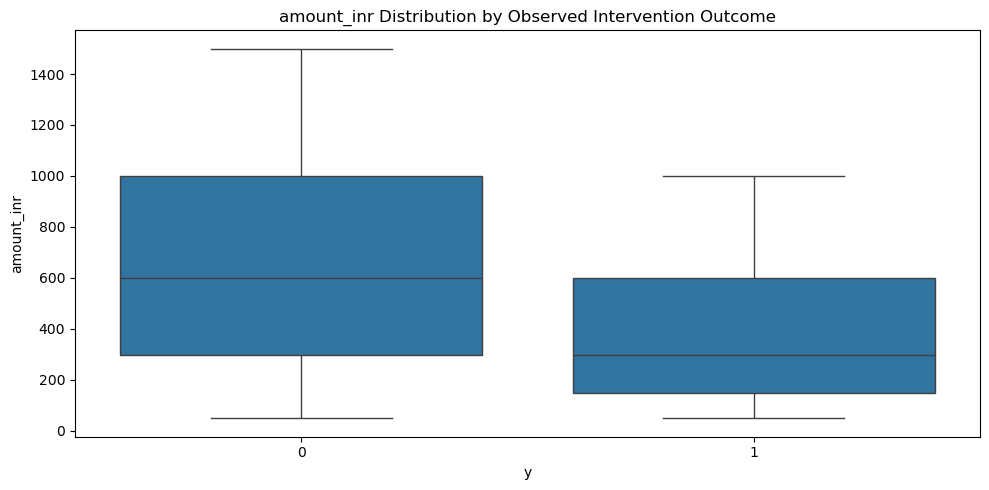

In [16]:

preferred_numeric = [
    "amount_inr",
    "prior_failure_count",
    "tenure_months",
    "attempt_index",
    "time_since_first_failure_days",
    "proxy_days_to_salary",
]

for col in preferred_numeric:

    if col not in ml.columns:
        continue

    temp = ml[
        [col, target_col]
    ].dropna()

    if temp[col].nunique() < 5:
        continue

    plt.figure(figsize=(10, 5))
    sns.violinplot(
        data=temp,
        x=target_col,
        y=col,
        cut=0,
    )
    plt.title(
        f"{col} Distribution by Observed Intervention Outcome"
    )
    save_plot(
        f"target_stratified_{col}_violin.png"
    )

    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=temp,
        x=target_col,
        y=col,
        showfliers=False,
    )
    plt.title(
        f"{col} Distribution by Observed Intervention Outcome"
    )
    save_plot(
        f"target_stratified_{col}_boxplot.png"
    )


## 13. Numeric Feature Correlation and Pairwise Structure

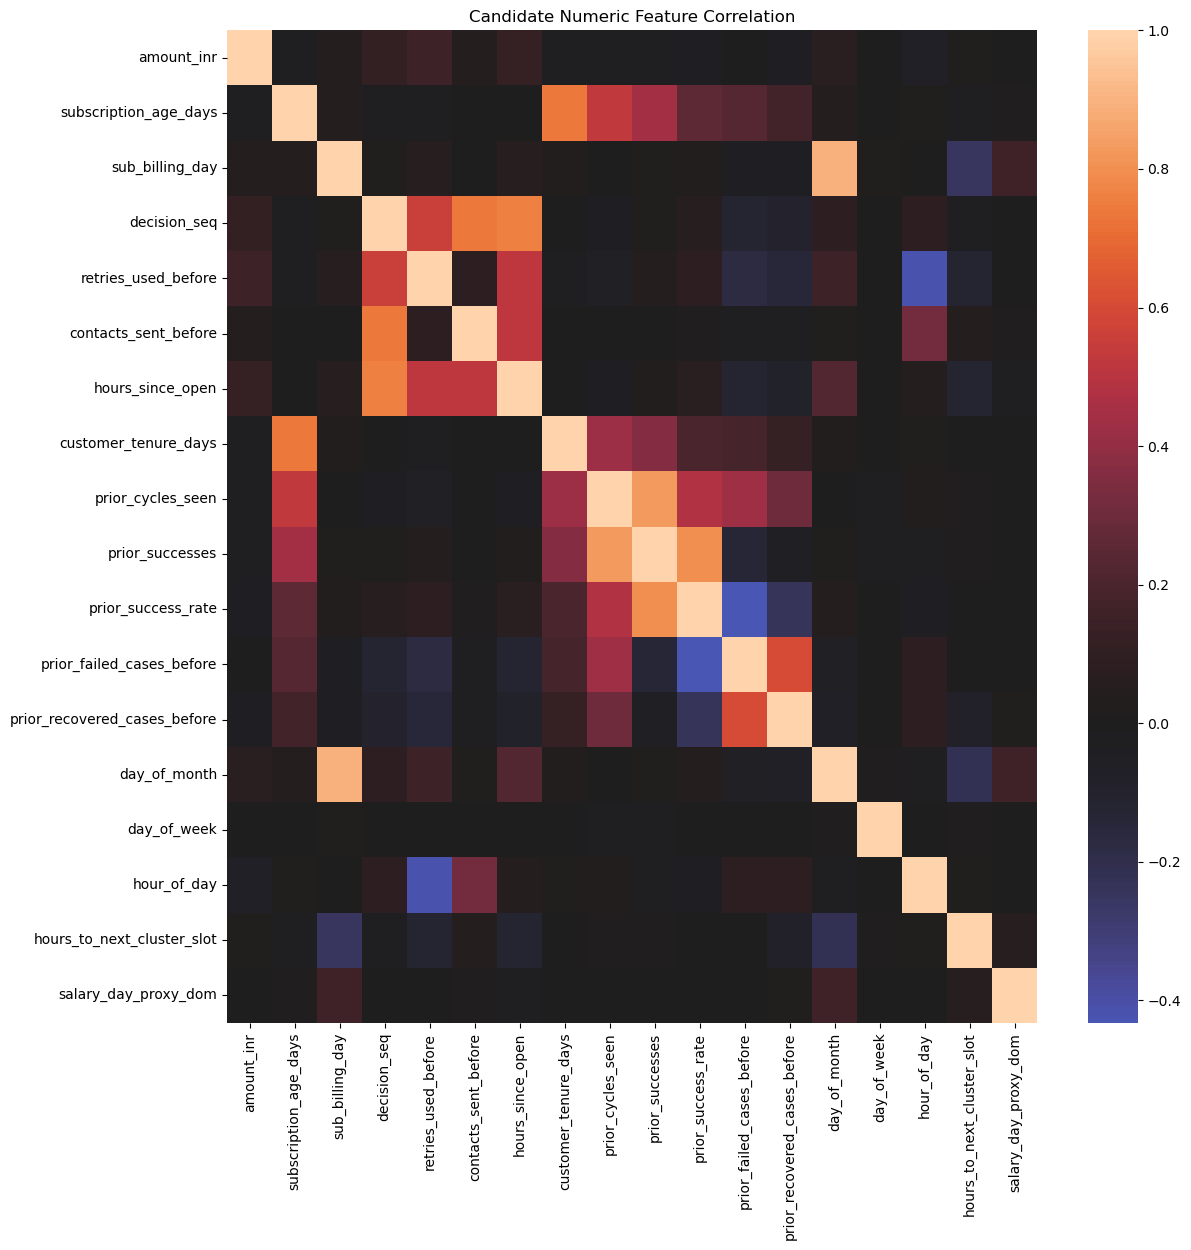

In [17]:

available_numeric = [
    c for c in numeric_candidates
    if c in ml.columns
]

if len(available_numeric) >= 2:

    corr = ml[available_numeric].corr(
        numeric_only=True
    )

    plt.figure(
        figsize=(
            max(9, len(corr.columns) * 0.7),
            max(7, len(corr.columns) * 0.7),
        )
    )

    sns.heatmap(
        corr,
        annot=len(corr.columns) <= 12,
        fmt=".2f",
        center=0,
    )
    plt.title("Candidate Numeric Feature Correlation")
    save_plot(
        "candidate_numeric_correlation_heatmap.png"
    )


In [18]:

# Small pairplot only for a selected high-value subset.
pair_cols = [
    c for c in [
        "amount_inr",
        "prior_failure_count",
        "tenure_months",
        "attempt_index",
    ]
    if c in ml.columns
]

if len(pair_cols) >= 2:
    pair_df = ml[
        pair_cols + [target_col]
    ].dropna()

    # Limit rows for readability / runtime.
    if len(pair_df) > 5000:
        pair_df = pair_df.sample(
            5000,
            random_state=42
        )

    g = sns.pairplot(
        pair_df,
        vars=pair_cols,
        hue=target_col,
        corner=True,
        diag_kind="hist",
    )

    g.fig.suptitle(
        "Selected Candidate Feature Pairwise Structure",
        y=1.02,
    )

    g.fig.savefig(
        REPORT_DIR / "selected_feature_pairplot.png",
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()
    plt.close("all")


## 14. Action Support and Selection Visuals

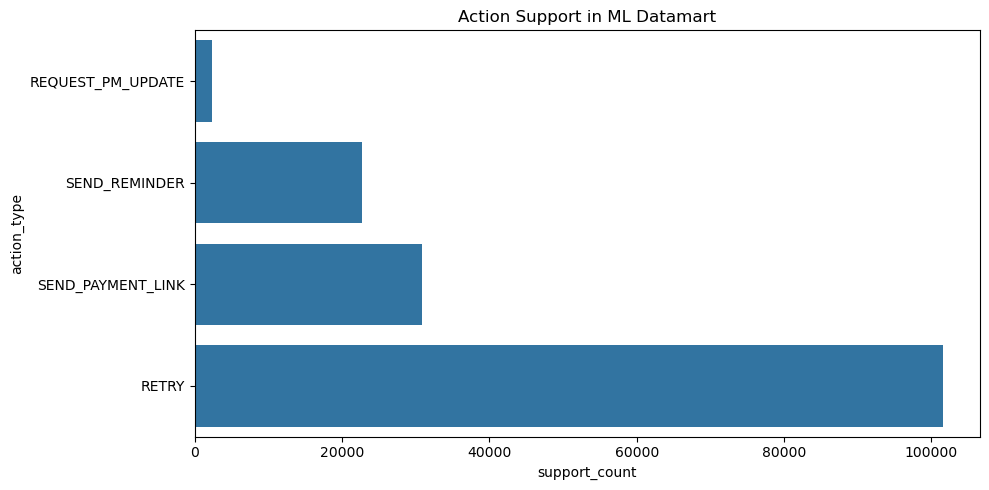

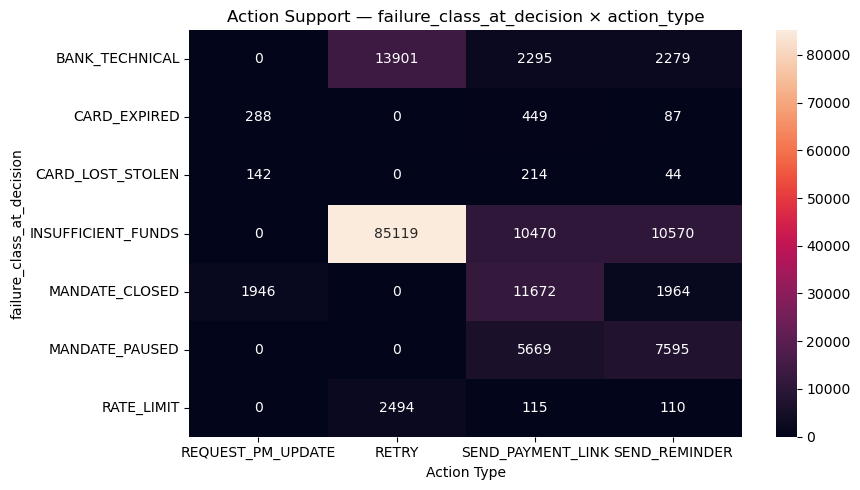

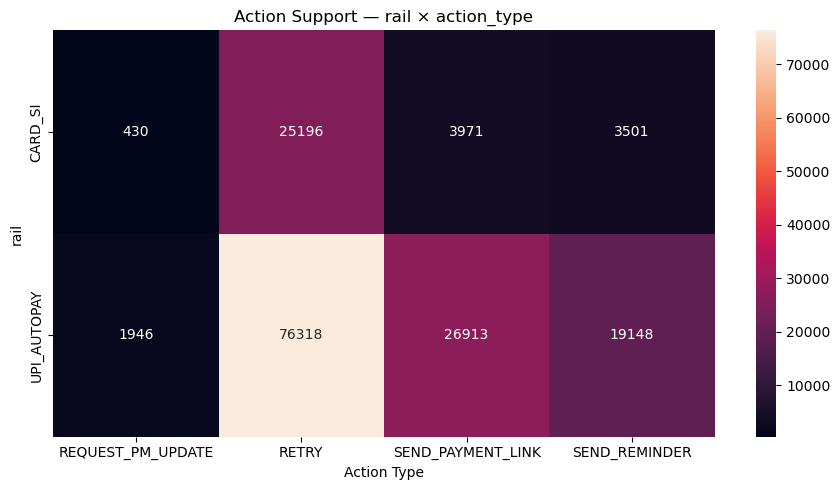

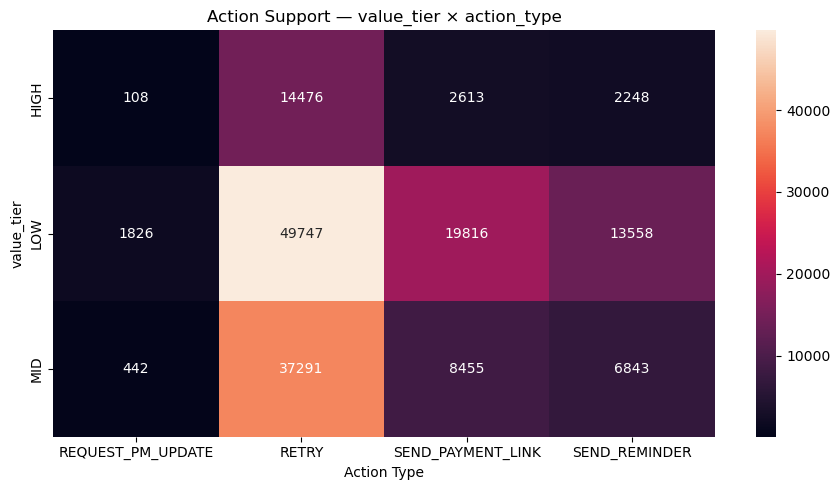

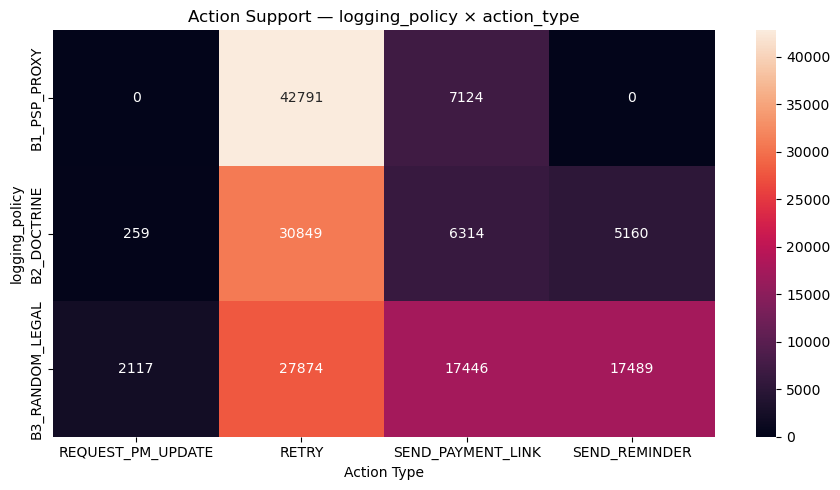

In [19]:

if "action_type" in ml.columns:

    support = (
        ml["action_type"]
        .value_counts()
        .rename("support_count")
        .reset_index()
    )
    support.columns = [
        "action_type",
        "support_count",
    ]

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=support.sort_values("support_count"),
        x="support_count",
        y="action_type",
        errorbar=None,
    )
    plt.title("Action Support in ML Datamart")
    save_plot(
        "action_support_barplot.png"
    )

    for group_col in [
        "failure_class",
        "failure_class_at_decision",
        "rail",
        "value_tier",
        "logging_policy",
    ]:

        if group_col not in ml.columns:
            continue

        ct = pd.crosstab(
            ml[group_col],
            ml["action_type"],
        )

        if ct.empty:
            continue

        plt.figure(
            figsize=(
                max(9, len(ct.columns) * 1.4),
                max(5, len(ct.index) * 0.5),
            )
        )

        sns.heatmap(
            ct,
            annot=True if ct.size <= 100 else False,
            fmt="g",
        )
        plt.title(
            f"Action Support — {group_col} × action_type"
        )
        plt.xlabel("Action Type")
        plt.ylabel(group_col)
        save_plot(
            f"action_support_{group_col}_heatmap.png"
        )


## 15. Advanced Insight Extraction

The notebook now converts the most important visual patterns into evidence records.

Important:
- These are exploratory associations.
- High observed action success is NOT automatically causal.
- Statistical significance is NOT feature importance.
- Findings must be supported by observed counts/rates.

In [20]:

# Example robust insight extraction for key dimensions.
# We only generate findings when minimum support is satisfied.

def record_dimension_insight(
    dimension,
    min_count=100,
):
    if dimension not in ml.columns:
        return

    summary = (
        ml.groupby(dimension, dropna=False)[target_col]
        .agg(
            observations="size",
            observed_success_rate="mean",
        )
        .reset_index()
    )

    supported = summary[
        summary["observations"] >= min_count
    ].copy()

    if len(supported) < 2:
        return

    best = supported.loc[
        supported["observed_success_rate"].idxmax()
    ]
    worst = supported.loc[
        supported["observed_success_rate"].idxmin()
    ]

    spread = (
        best["observed_success_rate"]
        - worst["observed_success_rate"]
    )

    add_insight(
        insights,
        section="Observed target heterogeneity",
        finding=f"Observed success varies across {dimension}.",
        evidence=(
            f"Highest supported group: {best[dimension]} "
            f"({best['observed_success_rate']:.3f}, "
            f"n={int(best['observations'])}); "
            f"lowest supported group: {worst[dimension]} "
            f"({worst['observed_success_rate']:.3f}, "
            f"n={int(worst['observations'])}); "
            f"spread={spread:.3f}."
        ),
        interpretation=(
            f"The logged intervention outcome is heterogeneous "
            f"across {dimension}."
        ),
        ml_implication=(
            f"{dimension} should remain a candidate state/context "
            f"variable for C3 review if it is decision-time available."
        ),
        caveat=(
            "Observed association; not a causal treatment effect."
        ),
        metric="max_minus_min_supported_success_rate",
        value=float(spread),
    )


for dimension in [
    "action_type",
    "failure_class",
    "failure_class_at_decision",
    "rail",
    "value_tier",
    "logging_policy",
]:
    record_dimension_insight(
        dimension,
        min_count=100,
    )

# Numeric nonlinear insights
if "numeric_relationships" in globals():
    for _, row in numeric_relationships.head(10).iterrows():
        if row["max_minus_min_rate"] <= 0:
            continue

        add_insight(
            insights,
            section="Nonlinear feature-target relationship",
            finding=(
                f"{row['feature']} shows variation in observed success "
                f"across quantile bins."
            ),
            evidence=(
                f"Max-minus-min binned observed success rate = "
                f"{row['max_minus_min_rate']:.3f}."
            ),
            interpretation=(
                "The relationship may be nonlinear and should not be "
                "summarized by correlation alone."
            ),
            ml_implication=(
                "Retain as a C3 candidate for appropriate transformation/"
                "encoding and later model comparison."
            ),
            caveat=(
                "Exploratory relationship; confounding and action-selection "
                "effects are not removed here."
            ),
            metric="binned_success_rate_spread",
            value=float(row["max_minus_min_rate"]),
        )

insights_df = pd.DataFrame(insights)
display(insights_df)

insights_df.to_csv(
    REPORT_DIR / "advanced_insights.csv",
    index=False,
)


,section,finding,evidence,interpretation,ml_implication,caveat,metric,value
0,Observed target heterogeneity,Observed success varies across action_type.,"Highest supported group: RETRY (0.267, n=10151...",The logged intervention outcome is heterogeneo...,action_type should remain a candidate state/co...,Observed association; not a causal treatment e...,max_minus_min_supported_success_rate,0.141800
1,Observed target heterogeneity,Observed success varies across failure_class_a...,Highest supported group: BANK_TECHNICAL (0.772...,The logged intervention outcome is heterogeneo...,failure_class_at_decision should remain a cand...,Observed association; not a causal treatment e...,max_minus_min_supported_success_rate,0.648903
2,Observed target heterogeneity,Observed success varies across rail.,"Highest supported group: CARD_SI (0.285, n=330...",The logged intervention outcome is heterogeneo...,rail should remain a candidate state/context v...,Observed association; not a causal treatment e...,max_minus_min_supported_success_rate,0.071515
3,Observed target heterogeneity,Observed success varies across value_tier.,"Highest supported group: LOW (0.294, n=84947);...",The logged intervention outcome is heterogeneo...,value_tier should remain a candidate state/con...,Observed association; not a causal treatment e...,max_minus_min_supported_success_rate,0.181777
4,Observed target heterogeneity,Observed success varies across logging_policy.,"Highest supported group: B2_DOCTRINE (0.305, n...",The logged intervention outcome is heterogeneo...,logging_policy should remain a candidate state...,Observed association; not a causal treatment e...,max_minus_min_supported_success_rate,0.113165


## 16. Graphical Anomaly / Outlier Review

In [21]:

anomaly_rows = []

for col in [
    "amount_inr",
    "prior_failure_count",
    "tenure_months",
    "attempt_index",
    "time_since_first_failure_days",
    "proxy_days_to_salary",
]:
    if col not in ml.columns:
        continue

    s = pd.to_numeric(
        ml[col],
        errors="coerce"
    ).dropna()

    if len(s) < 50:
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    anomaly_rows.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_review_bound": lower,
        "upper_review_bound": upper,
        "below_bound_count": int((s < lower).sum()),
        "above_bound_count": int((s > upper).sum()),
    })

anomaly_review = pd.DataFrame(anomaly_rows)
display(anomaly_review)

anomaly_review.to_csv(
    REPORT_DIR / "anomaly_review.csv",
    index=False,
)

print(
    "Outlier flags are REVIEW signals only. "
    "No observations were removed."
)


,feature,q1,q3,iqr,lower_review_bound,upper_review_bound,below_bound_count,above_bound_count
0,amount_inr,299.0,999.0,700.0,-751.0,2049.0,0,19445


Outlier flags are REVIEW signals only. No observations were removed.


## 17. C2B Final Output

Outputs are stored in:

`reports/eda_graphical/`

The final C2B report contains:
- advanced insights
- interaction summaries
- nonlinear relationships
- action-support evidence
- anomaly-review signals
- saved Seaborn graphics

No final feature selection is performed here.
C3 will use this evidence to establish the final feature contract.

In [22]:

# Compact machine-readable summary
summary = {
    "target_column": target_col,
    "ml_rows": int(len(ml)),
    "unique_cases": (
        int(ml["case_id"].nunique())
        if "case_id" in ml.columns else None
    ),
    "unique_customers": (
        int(ml["customer_id"].nunique())
        if "customer_id" in ml.columns else None
    ),
    "candidate_feature_count": int(len(candidate_cols)),
    "insight_count": int(len(insights_df)),
}

with open(
    REPORT_DIR / "c2b_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

# Human-readable report
lines = [
    "# C2B Graphical EDA Findings",
    "",
    "This report is generated from observed normalized Dataset V1 data.",
    "It contains exploratory associations, not causal treatment effects.",
    "",
]

for _, row in insights_df.iterrows():
    lines.extend([
        f"## {row['section']}",
        f"**Finding:** {row['finding']}",
        f"**Evidence:** {row['evidence']}",
        f"**Interpretation:** {row['interpretation']}",
        f"**ML implication:** {row['ml_implication']}",
        f"**Caveat:** {row['caveat']}",
        "",
    ])

(DOCS_DIR / "C2B_GRAPHICAL_EDA_FINDINGS.md").write_text(
    "\n".join(lines),
    encoding="utf-8",
)

print("C2B complete.")
print("Plots/reports:", REPORT_DIR)
print("Findings:", DOCS_DIR / "C2B_GRAPHICAL_EDA_FINDINGS.md")


C2B complete.
Plots/reports: c:\Users\Soham\Documents\revenue-recovery\reports\eda_graphical
Findings: c:\Users\Soham\Documents\revenue-recovery\docs\C2B_GRAPHICAL_EDA_FINDINGS.md
